<a id="sec-4"></a>

# 第04章 矩阵的解剖

![三格漫画：矩阵体检发现敏感方向，右端微小扰动导致解明显变化，机器人质疑小残差。](ABC共用-图片/A-章节导入.svg)

*图04-1 · 给矩阵做一次体检。初始化概念示意；适用条件见下文，不作为实测结果。*

## 先看一幕：给矩阵做一次体检

求解器递来一份漂亮的报告：“残差几乎为零。”矩阵医生却拿起放大镜：如果输入轻轻动一下，解会不会跳很远？

**先猜，再验证：** 设 $A=\operatorname{diag}(1,10^{-10})$。仅把右端第二个分量增加 $10^{-10}$，解的第二个分量会改变多少？这与求解器报告的小残差是否矛盾？

**把故事翻译成数学：** 在这个对角例子中，解的第二分量增加1，二范数条件数为 $10^{10}$。图中体检对应对矩阵结构与扰动敏感性的分析；小残差和小解误差是不同主张，还要说明残差针对哪个右端计算。

**知识主题：** 线性方程组、特征值与SVD

**本章核心问题：** Ax=b如何高效求解？矩阵的本质结构是什么？

**只聚焦三个核心概念：** LU、CG、SVD

**先修知识：** 矩阵运算、内积、正定性与向量/矩阵范数

**课时：** 4节 × 2学时 = 8学时；原八章共64学时；第09章另列8学时。

### 本章四节安排

| 节 | 内容 | 学时 |
| --- | --- | --- |
| [4.1](#sec-4-1) | 直接法：LU与Cholesky | 2 |
| [4.2](#sec-4-2) | 迭代法：CG与预条件 | 2 |
| [4.3](#sec-4-3) | 特征值与SVD | 2 |
| [4.4](#sec-4-4) | AI关联：可微求解器、PCA、LoRA | 2 |

---

<a id="sec-4-0"></a>

### 先修概念与符号约定

**先修概念**

- 线性方程组：$Ax=b$，其中 $A\in\mathbb R^{n\times n}$，$x,b\in\mathbb R^n$。
- 矩阵运算：转置 $A^T$、逆 $A^{-1}$、行列式 $\det(A)$、迹 $\operatorname{tr}(A)$。
- 内积与范数：$\langle x,y\rangle=x^Ty$；向量 2-范数 $\|x\|_2=\sqrt{x^Tx}$；矩阵范数 $\|A\|_2=\sigma_{\max}(A)$，且满足相容性 $\|Ax\|\leqslant\|A\|\|x\|$。
- 正定性：$A=A^T$ 且对任意非零 $x$ 有 $x^TAx>0$；等价于所有顺序主子式为正。
- 特征值与特征向量：$Av=\lambda v$（$v\ne0$）；对称矩阵可正交对角化 $A=V\Lambda V^T$。
- SVD：任意实矩阵 $A=U\Sigma V^T$，奇异值 $\sigma_1\geqslant\sigma_2\geqslant\cdots\geqslant0$。
- 隐函数定理：若 $F(x,\theta)=0$ 且 $\frac{\partial F}{\partial x}$ 可逆，则 $\frac{\partial x}{\partial\theta}=-(\frac{\partial F}{\partial x})^{-1}\frac{\partial F}{\partial\theta}$。

**符号约定**

| 符号 | 含义 |
| --- | --- |
| $A\in\mathbb R^{n\times n}$ | 系数矩阵（默认方阵、非奇异，除非另述） |
| $x,b\in\mathbb R^n$ | 未知向量与右端向量 |
| $r=b-Ax$ | 残差（$r_k=b-Ax_k$ 为第 $k$ 步残差） |
| $\delta b,\delta x,\delta A$ | 右端、解、系数矩阵的微小扰动 |
| $\Vert\cdot\Vert$ | 某种相容矩阵范数；默认 2-范数，需注明时写 $\Vert\cdot\Vert_2$ |
| $\kappa(A),\operatorname{cond}(A)$ | 条件数，$\kappa(A)=\operatorname{cond}(A)=\Vert A^{-1}\Vert\,\Vert A\Vert$；<br>默认为 $\kappa_2(A)=\operatorname{cond}_2(A)= \frac{\sigma_{\max}}{\sigma_{\min}}$ |
| $\sigma_i$ | 奇异值，按 $\sigma_1\geqslant\sigma_2\geqslant\cdots\geqslant0$ 排列 |
| $\lambda_i$ | 特征值 |
| $\rho(A)$ | 谱半径 |
| $W_0,\Delta W$ | 预训练权重与微调增量 |

In [36]:
import os
# 在导入NumPy前设置；实际生效情况另由threadpoolctl记录。
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS'):
    os.environ[name] = '1'
import sys, json, csv, platform, time, importlib, importlib.metadata, hashlib
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import scipy
from scipy import linalg as sla
from scipy.sparse.linalg import cg as scipy_cg, LinearOperator
import matplotlib.pyplot as plt
# Notebook 中用 IPython.display 渲染表格；脚本模式下提供零依赖回退，
# 这样在只安装 NumPy/SciPy/Matplotlib 的环境中也能完成数值复核。
try:
    from IPython.display import display, Markdown
    IPYTHON_AVAILABLE = True
except ImportError:
    IPYTHON_AVAILABLE = False
    class Markdown(str):
        pass
    def display(obj):
        print(str(obj))

try:
    from threadpoolctl import threadpool_info, threadpool_limits
    thread_limits = threadpool_limits(limits=1)
except ImportError:
    from contextlib import nullcontext

    def threadpool_info():
        return []

    thread_limits = nullcontext()

np.set_printoptions(precision=8, suppress=True)
SEED = 2026
rng = np.random.default_rng(SEED)
BASE = Path.cwd()
OUT = BASE / 'A组-运行证据'
FIG = BASE / '图片'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
checks = []
results = {}
t_start = time.perf_counter()

def check(name, condition, detail=''):
    ok = bool(condition)
    checks.append({'check':name,'passed':ok,'detail':str(detail)})
    if not ok:
        raise AssertionError(f'{name}: {detail}')

def relerr(a, b):
    num = np.linalg.norm(np.asarray(a)-np.asarray(b))
    den = np.linalg.norm(b)
    return float(num/den) if den else float(num)

def save_table(name, rows):
    with (OUT / (name + '.csv')).open('w', encoding='utf-8-sig', newline='') as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    keys=list(rows[0])
    def fmt(v):
        return f'{v:.6g}' if isinstance(v,(float,np.floating)) else str(v)
    text='| '+' | '.join(keys)+' |\n| '+' | '.join(['---']*len(keys))+' |\n'
    text+='\n'.join('| '+' | '.join(fmt(row[k]) for k in keys)+' |' for row in rows[:12])
    display(Markdown(text))
    if len(rows)>12: print(f'展示前12行；完整{len(rows)}行已保存到CSV。')

def finish_plot(name):
    plt.tight_layout()
    plt.savefig(FIG/name, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

env = {'python':sys.version, 'platform':platform.platform(), 'machine':platform.machine(),
       'device':'CPU', 'seed':SEED, 'dtype':'float64',
       'runtime_clock_utc':datetime.now(timezone.utc).isoformat(),
       'delivery_date':'2026-10-28',
       'packages':{p:(importlib.metadata.version(p) if importlib.util.find_spec(p) is not None
                      else 'not-installed') for p in
                   ['numpy','scipy','matplotlib','nbformat','nbclient','nbconvert','ipykernel','ipython','torch','threadpoolctl']},
       'threadpools':threadpool_info(),
       'repository_base_commit':'3f632c5a46f8637afb96996b54d3295b74f5b803',
       'ipython_available':IPYTHON_AVAILABLE,
       'validation_scope':'本轮交付的脚本执行与数值审校；不代替课程组签署或B/C独立复现'}
(OUT/'environment.json').write_text(json.dumps(env,ensure_ascii=False,indent=2),encoding='utf-8')
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| SciPy:', scipy.__version__)
print('Device: CPU | dtype: float64 | seed:', SEED)
print('Runtime clock (UTC):', env['runtime_clock_utc'])
print('Target Python 3.12 verified here:', sys.version_info[:2] == (3,12))


Python: 3.12.10 | NumPy: 1.26.4 | SciPy: 1.14.1
Device: CPU | dtype: float64 | seed: 2026
Runtime clock (UTC): 2026-10-31T06:16:03.827080+00:00
Target Python 3.12 verified here: True


<a id="sec-4-1"></a>

## 4.1 直接法：LU 与 Cholesky（2 学时）

**本节目标：** 能按矩阵条件选择分解，并解释主元和三角求解。

### 概念讲解：把问题说明白

线性方程组 $Ax=b$ 是科学计算最基本的问题之一。尽管在学习线性代数时，我们就学习了手动计算的方法，但假如直接让机器按照手动计算的方法进行运算，会遇到一些现实问题：矩阵规模一旦变大，计算量增长会很快；数值的量级差距过大时，误差可能会被急剧放大。机器需要的不是“能算”，而是“算得稳、算得快、还能反复用”。那么，计算机在解决这类问题时，采用的会是什么方法呢？

一种思想是，想办法将矩阵通过等价变形，化简为容易求解的形式，比如将矩阵分解成若干个易于计算的矩阵。本节会讨论对于不同的系数矩阵提出的各种分解方案，并尝试说明“计算过程稳定”与“问题本身敏感”是两件不同的事。

<a id="sec-4-1-1"></a>

### 4.1.1 从 Gauss 消元法到矩阵的 LU 分解

对我们来说，求解线性方程组 $Ax=b$ 最基础的求解思想，便是通用的手动求解方法—— **Gauss 消元法**。Gauss 消元法的基本思路是：通过对矩阵 $A$ 进行一系列的行变换处理，将矩阵变成一个上三角矩阵，即可从下到上求解每一个未知数。若要将这一思想迁移到机器运算，并设计一种算法的话，我们希望这种算法的流程更加固定、计算更加稳定、能尽量避免误差，还能尽可能地减小所需计算量的规模。

回顾 Gauss 消元法的过程：对 $A$ 进行的一系列操作可以看作对矩阵的一系列线性变换，复合之后便得到一个能代表整个消元过程的线性变换 $T$，满足 $U=TA$ 为上三角矩阵，之后求 $Ux=Tb$ 的解即可。对于上三角矩阵 $U$，这一过程只需从最下面开始求解，然后逐次带入到上一个方程中即可得到方程的解。

注意到：操作过程保证了 $T$ 其实是一个下三角矩阵，显然可逆。现在，假如我们进行一个简单的变形，就得到了 $A=T^{-1}U$。换句话说，可以看作将 $A$ 分解为一个下三角矩阵 $L=T^{-1}$ 和一个上三角矩阵 $U$ 的乘积：

<a id="eq-4-1"></a>

$$
\boxed{\,A=LU\,} \tag{4.1}
$$

上述从矩阵分解角度的思考带给我们很多启发，我们能进一步从中总结出直接求解线性方程组的基本概念与核心思想：

<a id="def-4-1"></a>

> **定义 4.1（直接法）**  
> 通过有限步算术运算直接求方程的解的方法，称为**直接法**。其核心思想是将系数矩阵 $A$ 分解为若干个结构简单的矩阵的乘积（如下三角/上三角矩阵，或对角矩阵、正交矩阵等），从而把原方程化简为更易求解的形式。

最基础的分解即式 [(4.1)](#eq-4-1) 中的形式。下面我们给出这种分解的定义：

<a id="def-4-2"></a>

> **定义 4.2（LU 分解）**  
> 将 $A$ 写成 $A=LU$ 的形式，其中 $L$ 为单位下三角矩阵（即对角元全为 $1$，这一要求是为了保证分解唯一），$U$ 为上三角矩阵。这种分解被称为 **LU 分解**。

进行 LU 分解后，可以把 $Ax=b$ 的求解过程分为两步：

1. 解 $Ly=b$，得到 $y$；
2. 解 $Ux=y$，得到 $x$。

事实上，**Gauss 消元法与 LU 分解本质上是同一件事**。消元过程通过行初等变换把 $A$ 变形为上三角矩阵，从矩阵角度来看这个过程，其中每一步变换都能“翻译”为对系数矩阵 $A$ 左乘一个下三角矩阵。具体地说，Gauss 消元法第 $k$ 步相当于左乘一个单位下三角矩阵 $L_k$，这里

$$
L_k=
\begin{pmatrix}
1&&&&\\
&\ddots&&&\\
&&1&&\\
&&-m_{k+1,k}&1&\\
&&\vdots&&\ddots\\
&&-m_{n,k}&&&1
\end{pmatrix},
$$

其中 $m_{ik}=\frac{a_{ik}^{(k)}}{a_{kk}^{(k)}}$（这里 $a_{ij}^{(k)}$ 表示第 $k$ 步中的 $a_{ij}$）。消元与分解的关系可以画成下面这张推导图：

$$
\begin{aligned}
A \;&\xrightarrow{\ L_1\ }\; L_1A \;\xrightarrow{\ L_2\ }\; \cdots \;\xrightarrow{\ L_{n-1}\ }\; U \\
A \;&\xrightarrow{\ \text{反过来}\ }\; (L_{n-1}\cdots L_1)^{-1}U = L_1^{-1}\cdots L_{n-1}^{-1}U = LU
\end{aligned}
$$

也就是说，消元把 $A$ 变成 $U$，而把每一步消元的“逆”按顺序乘起来，就得到 $L$。因此消元的最终结果为 $L_{n-1}\cdots L_2L_1A=U$，从而有

<a id="eq-4-2"></a>

$$
A=(L_{n-1}\cdots L_1)^{-1}U=L_1^{-1}L_2^{-1}\cdots L_{n-1}^{-1}U. \tag{4.2}
$$

直接计算可得，$L_k^{-1}$ 恰为 $L_k$ 的非对角元取相反数，也都是单位下三角矩阵。故 $L=L_1^{-1}\cdots L_{n-1}^{-1}$ 也是单位下三角矩阵，且其第 $i$ 行第 $j$ 列（$i>j$）的元素恰为消元过程中使用的乘数 $m_{ij}$。因此式 [(4.2)](#eq-4-2) 本质上和 [(4.1)](#eq-4-1) 的分解形式相同，这样就说明了 Gauss 消元法与 LU 分解的等价关系。

**直接三角分解法**（Doolittle 分解）是 LU 分解的另一种实现方式。既然已知分解目标，那么便可以绕过 Gauss 消元法中间的计算步骤，直接比对 [(4.1)](#eq-4-1) 两边对应位置的元素，即可得递推公式：

$$
\left\{
\begin{array}{ll}
u_{1i}=a_{1i}, & i=1,2,\cdots,n,\\[4pt]
l_{i1}=\dfrac{a_{i1}}{u_{11}}, & i=2,3,\cdots,n,
\end{array}
\right.
$$

对 $r=2,3,\cdots,n$：

$$
\left\{
\begin{array}{ll}
u_{ri}=a_{ri}-\sum\limits_{k=1}^{r-1}l_{rk}u_{ki}, & i=r,r+1,\cdots,n,\\[8pt]
l_{ir}=\dfrac{1}{u_{rr}}\left(a_{ir}-\sum\limits_{k=1}^{r-1}l_{ik}u_{kr}\right), & i=r+1,\cdots,n.
\end{array}
\right.
$$

Doolittle 分解的计算顺序是“先 $U$ 行、后 $L$ 列”：第 $r$ 步先用已得的 $L$ 前 $r-1$ 列算 $u_{ri}$，再用 $u_{rr}$ 算 $l_{ir}$。这样每一步只用已算出的元素，很适合按行编程。

下面我们来估计 Gauss 消元法和 LU 分解的运算复杂度：

Gauss 消元法先做前向消元，第 $k$ 步约需进行 $(n-k)^2+(n-k)$ 次乘除法 $(k=1,2,\cdots,n-1)$，求和得 $\sum\limits_{k=1}^{n-1}[(n-k)^2+(n-k)]=\frac{n^3-n}{3}=O(n^3)$，而回代求解过程中的计算次数约为 $\frac{n(n+1)}{2}=O(n^2)$，故总复杂度为 $O(n^3)$；

LU 分解中第 $k$ 步约需 $(2n-2k+1)(k-1)$ 次乘除法，求和得 $\sum\limits_{k=1}^{n}(2n-2k+1)(k-1)=\frac{n(n-1)(2n-1)}{6}=O(n^3)$，而分解后求解过程中还需要约 $n^2=O(n^2)$ 次运算，因此总复杂度也是 $O(n^3)$。

既然复杂度差别不大，和 Gauss 消元法相比，LU 分解是不是就没有什么计算层面的优势了呢？其实并不是这样的，因为对于同一个矩阵 $A$ 来说，LU 分解完成后，假如只改变 $b$ 再次求解，那么复杂度仅为 $O(n^2)$。因此，虽然 LU 分解在单次计算中的复杂度与 Gauss 消元法差别不大，但是在实际问题中，当需要求解多个具有相同系数矩阵 $A$ 而 $b$ 不相同的方程组时，矩阵分解的结果即可反复使用，从而在多次运算中大大节省计算的复杂度。

<a id="sec-4-1-2"></a>

### 4.1.2 LU 分解的性质与改进

LU 分解的存在性依赖于 $A$ 的顺序主子式：若 $A$ 的所有顺序主子式均不为零，则存在唯一的单位下三角矩阵 $L$ 和非奇异上三角矩阵 $U$，使得 $A=LU$. 下面我们用归纳法证明：

设 $A$ 的所有顺序主子式均不为零。当 $n=1$ 时结论显然。假设结论对 $n-1$ 阶矩阵成立，将 $A$ 分块为

$$
A=
\begin{pmatrix}
A_{11}&A_{12}\\
A_{21}&A_{22}
\end{pmatrix},
$$

其中 $A_{11}$ 为 $n-1$ 阶顺序主子矩阵。由归纳假设，$A_{11}=L_{11}U_{11}$。令

$$
L_{21}=A_{21}U_{11}^{-1},\qquad
U_{12}=L_{11}^{-1}A_{12},\qquad
U_{22}=A_{22}-L_{21}U_{12},
$$

则

$$
A=
\begin{pmatrix}
L_{11}&0\\
L_{21}&I
\end{pmatrix}
\begin{pmatrix}
U_{11}&U_{12}\\
0&U_{22}
\end{pmatrix}.
$$

由 $A$ 非奇异可知 $U_{22}$ 非奇异，这就得到了矩阵 $A$ 的 LU 分解。

而 LU 分解的唯一性也很容易说明：若 $A=LU=\bar{L}\bar{U}$，变形后得到 $L^{-1}\bar{L}=U\bar{U}^{-1}$。注意此时左边是单位下三角矩阵，右边是上三角矩阵，因此两边都只能是单位矩阵，从而 $L=\bar{L}$，$U=\bar{U}$。

理论上，只要顺序主子式都不为零，LU 分解就存在且唯一。而当某个顺序主子式为零时，消元过程就会出现零主元，使得分解无法进行（事实上，Gauss 消元法也会遇到类似的问题，因为 Gauss 消元法能顺利完成的充要条件就是 $A$ 的所有顺序主子式都不为零）。

为了说明这一点，考虑一个简单但极端的例子：取 $A=\begin{pmatrix}0&1\\1&0\end{pmatrix}$，尽管 $A$ 非奇异，但 $a_{11}=0$，第一步消元就无法进行。

更隐蔽的情况是主元非零却又十分接近零的情况。当绝对值极小时，作除数会导致舍入误差被急剧放大。因此虽然此时消元过程可以继续，但计算结果将可能严重失真。

比方说，我们取三位有效数字计算

$$
\begin{pmatrix}
0.001&2.000\\
1.000&3.000
\end{pmatrix}
\begin{pmatrix}
x_1\\
x_2
\end{pmatrix}
=
\begin{pmatrix}
2.001\\
4.000
\end{pmatrix}.
$$

精确解为 $x_1=1$，$x_2=1$。但若用 $0.001$ 作主元消元，乘数应为 $1000$，第二个方程的系数变为 $3.000-2000=-1997$，可以看出舍入到三位有效数字后精度损失极大，三位有效数字根本存不下这个跨度，因此计算出的 $x_1$ 可能完全错误。所以，主元并不是“不为零就行”，它的大小决定了误差会被放大多少倍。

为了避免放大舍入误差，改进方法是预先做行交换，把每一列中绝对值最大的元素交换到主元位置（对角线上），再按普通消元进行。第 $k$ 步的流程可以写成：

$$
\begin{aligned}
&\text{选：第 }k\text{ 列中 }|a_{ik}|\text{ 最大者}\\
&\downarrow\\
&\text{换：与第 }k\text{ 行交换，记入 }P\\
&\downarrow\\
&\text{消：用 }m_{ik}\text{ 消去第 }k\text{ 列下方元素}
\end{aligned}
$$

三步循环 $k=1,\dots,n-1$，就得到 $PA=LU$。

> **列主元法（部分选主元法）**：消元前先做行交换，把每一列中绝对值最大的元素换到主元位置，再按普通消元进行；对应的矩阵形式为 $PA=LU$，其中 $P$ 记录行交换。

列主元 LU 分解的矩阵形式为

<a id="eq-4-3"></a>

$$
\boxed{\,PA=LU\,} \tag{4.3}
$$

其中 $P$ 是置换矩阵，记录行交换的信息。$L$ 仍然是单位下三角矩阵，但它的元素在交换行之后会相应改变，且满足 $|l_{ij}|\leqslant 1$。这一性质保证了消元过程中乘数的绝对值不超过 $1$，从而避免舍入误差的过度放大。对于一般非奇异矩阵，列主元 LU 分解总是可行的。

另外，在实际编程中，$L$ 和 $U$ 的元素可以直接存放在 $A$ 的相应位置，不需要额外存储空间。[(4.3)](#eq-4-3) 对应的分解法大约需要 $\frac{n^3}{3}$ 次乘除法，与 Gauss 消元法的计算量量级相同。

需要注意的是，列主元 LU 分解必须明确置换约定：$PA=LU$ 中 $P$ 左乘 $A$ 表示行交换，而 $AP=LU$ 表示列交换，$P\ne P^T$ 时不能混用。每次行交换后，$L$ 中已存好的对应行乘子也要同步交换，否则 $PA=LU$ 不成立。

<a id="sec-4-1-3"></a>

### 4.1.3 对称正定矩阵的 Cholesky 分解

下面我们考虑一类特殊矩阵——**对称正定矩阵**。在最小二乘问题、偏微分方程的数值求解，以及函数的 Hessian 矩阵等实际问题中，都经常能见到这类矩阵的影子，因此针对这类矩阵进行专门研究也十分必要。

对称正定矩阵的分解比较特殊：若 $A$ 对称且正定，进行 LU 分解后得到的上下三角矩阵也应该是互相对称的，因此可以仿照式 [(4.1)](#eq-4-1)，将分解写成

<a id="eq-4-4"></a>

$$
\boxed{\,A=LL^T\,} \tag{4.4}
$$

式 [(4.4)](#eq-4-4) 就是对称正定矩阵的 Cholesky 分解，下面给出定义：

<a id="def-4-3"></a>

> **定义 4.3（Cholesky 分解）**  
> 设 $A$ 对称正定。若 $A=LL^T$，其中 $L$ 为对角元全为正的下三角矩阵，则称该分解为 **Cholesky 分解**。

定义中要求 $L$ 对角元全为正，是为了保证分解唯一性。$A$ 对称正定时，所有顺序主子式都为正，故上述 $L$ 存在且唯一。因为这种分解就像给矩阵开平方：这里 $L$ 相当于 $A$ 的平方根，故也称 **平方根法**。

下面通过比较 [(4.4)](#eq-4-4) 两边的元素来推导 Cholesky 分解的递推公式：

设 $A=LL^T$，对 $j\leqslant i$，有

$$
a_{ij}=\sum_{k=1}^{j}l_{ik}l_{jk}
=\sum_{k=1}^{j-1}l_{ik}l_{jk}+l_{ij}l_{jj}.
$$

当 $i=j$ 时，

$$
a_{jj}=\sum_{k=1}^{j-1}l_{jk}^2+l_{jj}^2
\quad\Longrightarrow\quad
l_{jj}=\sqrt{a_{jj}-\sum_{k=1}^{j-1}l_{jk}^2}.
$$

这里由 $A$ 的正定性，$a_{jj}-\sum\limits_{k=1}^{j-1}l_{jk}^2>0$，故 $l_{jj}$ 有定义，不会出现零主元。开平方时只取正平方根，保证 $L$ 的对角元素全为正数。当 $i>j$ 时，

$$
l_{ij}=\frac{1}{l_{jj}}
\left(a_{ij}-\sum_{k=1}^{j-1}l_{ik}l_{jk}\right).
$$

从计算过程中，我们还可以推导出 Cholesky 分解不需要选主元，因为对称正定矩阵的消元过程中不会出现小主元：由 $a_{jj}=\sum\limits_{k=1}^j l_{jk}^2$ 可得 $l_{jk}^2\leqslant a_{jj} \leqslant \max\limits_{1\leqslant j\leqslant n}\{a_{jj}\}$，因此 $\max\limits_{1\leqslant k \leqslant j \leqslant n}\{l_{jk}^2\}\leqslant \max\limits_{1\leqslant j\leqslant n}\{a_{jj}\}$。这说明分解过程中 $l_{jk}$ 不会无界增长。因此，Cholesky 分解是数值稳定的方法。另外，也能发现定义中要求 $L$ 的对角元素全为正数的必要性：开根号运算会得到正负两个平方根，因此不妨只取其中的正平方根。

与 LU 分解相比，Cholesky 分解的计算量大约减半（约 $\frac{n^3}{6}$ 次乘除法），存储量也减半（只需存储下三角矩阵 $L$）。它的代价是需要 $n$ 次开平方运算。为避免开方，可使用改进的平方根法：

> **$LDL^T$ 分解（改进的平方根法）**：将对称正定矩阵写成 $A=LDL^T$，其中 $L$ 为单位下三角矩阵，$D$ 为对角矩阵。它与 Cholesky 分解计算量相当，但不需要开平方。

<a id="eq-4-5"></a>

$$
\boxed{\,A=LDL^T\,} \tag{4.5}
$$

其中 $L$ 为单位下三角矩阵，$D$ 为对角矩阵。按行计算 $L$ 和 $D$ 的公式为：$d_1=a_{11}$，对 $i=2,3,\cdots,n$，有：

$$
\left\{
\begin{array}{ll}
t_{ij}=a_{ij}-\sum\limits_{k=1}^{j-1}t_{ik}l_{jk}, & j=1,2,\cdots,i-1,\\[4pt]
l_{ij}=\dfrac{t_{ij}}{d_j}, & j=1,2,\cdots,i-1,\\[4pt]
d_i=a_{ii}-\sum\limits_{k=1}^{i-1}t_{ik}l_{ik}.
\end{array}
\right.
$$

该方法与 Cholesky 分解的计算量差不多，但不再需要进行开平方计算。不过，其适用条件并不比 Cholesky 更宽，仍要求 $A$ 对称正定（或对称且顺序主子式非零）；且不开方不等于可用于非正定矩阵，否则 $D$ 的对角元可能为零或负数。

<a id="sec-4-1-4"></a>

### 4.1.4 三对角矩阵的追赶法

前几节介绍的分解方法都是面向一般的稠密矩阵的方法，并没有针对某些稀疏矩阵的特殊结构进行专门的优化。下面以一种具有特殊结构的矩阵为例，介绍一种针对性强的简化的分解方案。

**三对角矩阵**是只有三条对角线上的元素非零的矩阵，它经常出现在常微分方程边值问题、三次样条插值和热传导方程的差分格式中。针对三对角矩阵设计的 LU 分解，乘除法运算量仅为 $O(n)$，而不是一般的 $O(n^3)$。

> **追赶法（Thomas 算法）**：针对三对角矩阵设计的 LU 分解与三角求解方法，乘除法运算量仅 $O(n)$；分解为 $A=LU$，$L$ 单位下双对角、$U$ 上双对角，求解分“追”（前代）与“赶”（回代）两步。

下面设三对角矩阵为

$$
A=\begin{pmatrix}
b_1 & c_1 & & & \\
a_2 & b_2 & c_2 & & \\
 & \ddots & \ddots & \ddots & \\
 & & a_{n-1} & b_{n-1} & c_{n-1}\\
 & & & a_n & b_n
\end{pmatrix},
$$

用角标对应行数，即下对角线为 $a_i\ (i=2,\cdots,n)$，主对角线为 $b_i\ (i=1,\cdots,n)$，上对角线为 $c_i\ (i=1,\cdots,n-1)$。

追赶法的矩阵分解形式仍为 $A=LU$，这里 $L$ 是单位下双对角矩阵（次对角线为 $l_i$，对角元为 $1$），$U$ 是上双对角矩阵（对角元为 $u_i$，上次对角线为 $c_i$）：

$$
L=\begin{pmatrix}
1 & & & \\
l_2 & 1 & & \\
 & \ddots & \ddots & \\
 & & l_n & 1
\end{pmatrix},\qquad
U=\begin{pmatrix}
u_1 & c_1 & & \\
 & u_2 & c_2 & \\
 & & \ddots & \ddots\\
 & & & u_n
\end{pmatrix}.
$$

这里 $U$ 的上次对角线与 $A$ 的上对角线 $c_i$ 保持一致，这是追赶法能够简化的关键：消去过程中上对角线不变。

将 $A=LU$ 按元素展开，比较第一行得 $b_1=u_1,c_1=c_1$。对 $i=2,\cdots,n$，比较第 $i$ 行的次对角元与主对角元，得

$$
a_i=l_i u_{i-1},\qquad b_i=l_i c_{i-1}+u_i .
$$

由此直接解出递推公式：

$$
u_1=b_1,\qquad l_i=\frac{a_i}{u_{i-1}},\qquad u_i=b_i-l_i c_{i-1}\quad(i=2,\cdots,n).
$$

计算顺序是：先由 $b_1$ 得 $u_1$；然后对 $i=2,3,\cdots,n$ 依次算 $l_i=\frac{a_i}{u_{i-1}},u_i=b_i-l_i c_{i-1}$。这里每步只用到前一步的 $u_{i-1}$，因此只需 $O(n)$ 次运算。

得到 $L,U$ 后，求解 $Ax=d$ 分为“追”和“赶”两步：

追——前代求解 $Ly=d$，

$$
y_1=d_1,\qquad y_i=d_i-l_i y_{i-1}\quad(i=2,\cdots,n).
$$

赶——回代求解 $Ux=y$，

$$
x_n=\frac{y_n}{u_n},\qquad x_i=\frac{y_i-c_i x_{i+1}}{u_i}\quad(i=n-1,\cdots,1).
$$

前代自上而下、回代自下而上，故称追赶法。可以把“追”和“赶”当成两句话来记：

> **追**——从上往下前代，$y_i=d_i-l_i y_{i-1}$；\
> **赶**——从下往上回代，$x_i=\frac{y_i-c_i x_{i+1}}{u_i}$。\
> 一追一赶，整个求解只用 $5n-4$ 次乘除法、约 $3n$ 次加减法，复杂度 $O(n)$。

追赶法能够顺利进行的条件是三对角矩阵满足**对角占优条件**：

$$
|b_1|>|c_1|,\qquad |b_i|\geqslant |a_i|+|c_i|\ (i=2,\cdots,n-1),\qquad |b_n|>|a_n|.
$$

下面用归纳法证明：$u_i \neq 0(i=1,2,\cdots ,n)$，且若设 $\beta_i=\frac{c_i}{u_i}$，则可证明 $|\beta_i|<1\ (i=1,\cdots,n-1)$，从而计算过程稳定。

$i=1$ 时，由 $|b_1|>|c_1|$ 及 $u_1=b_1$，得

$$
|\beta_1|=\left|\frac{c_1}{u_1}\right|=\left|\frac{c_1}{b_1}\right|<1 .
$$

$i>1$ 时，若 $|\beta_{i-1}|<1$，则由 $u_i=b_i-l_i c_{i-1}=b_i-a_i\beta_{i-1}$（因为 $l_i=\frac{a_i}{u_{i-1}}$、$\beta_{i-1}=\frac{c_{i-1}}{u_{i-1}}$，故 $l_i c_{i-1}=a_i\beta_{i-1}$），有

$$
|u_i|=|b_i-a_i\beta_{i-1}|
\geqslant |b_i|-|a_i|\,|\beta_{i-1}|
>|b_i|-|a_i|
\geqslant |c_i|\geqslant 0 .
$$

其中第二个不等号用了 $|\beta_{i-1}|<1$，第三个不等号用了对角占优 $|b_i|\geqslant |a_i|+|c_i|$。于是 $u_i\neq 0$，且 $|\beta_i|=\left|\frac{c_i}{u_i}\right|<1$。

由归纳法知 $|\beta_i|<1$ 对 $i=1,\cdots,n-1$ 成立。

又对 $i=n$，由 $|b_n|>|a_n|$ 及 $|\beta_{n-1}|<1$ 得

$$
|u_n|=|b_n-a_n\beta_{n-1}|
\geqslant |b_n|-|a_n|\,|\beta_{n-1}|
>|b_n|-|a_n|>0,
$$

故 $u_n\neq 0$，上述结论成立。因此在回代过程中，误差不会被放大，追赶法是稳定的。

<a id="sec-4-1-5"></a>

### 4.1.5 误差分析

直接法在不考虑舍入误差时给出的是精确解，且计算量基本固定。它的优势在于稳定、可靠，适用于中小规模稠密矩阵，也适用于某些具有特殊结构的大型稀疏矩阵。不过它的局限在于当矩阵规模很大，分解过程会产生大量“填充”（原本为零的位置在分解后变成非零），存储和计算代价都迅速增长。

当然，上面的讨论都建立在精确算术的前提下。实际计算中，浮点舍入误差不可避免，因此需要考虑一个更基本的问题：**输入端的微小扰动，会在解的误差中被放大多少倍？** 直觉上，这取决于矩阵“把某些方向压得多扁”。压得越扁，反推回来时放大得越厉害。

我们通过计算来分析。设 $A$ 非奇异，考虑方程 $Ax=b$，先只讨论右端扰动：假定 $A$ 精确，右端有微小扰动 $\delta b$，实际求解的是扰动方程组 $A\widetilde{x}=b+\delta b$。记真解为 $x=A^{-1}b$，解的扰动为 $\delta x=\widetilde{x}-x$。两式相减得 $A\delta x=\delta b$，故

$$
\delta x=A^{-1}\delta b.
$$

两边取范数，得

$$
\|\delta x\|\leqslant\|A^{-1}\|\,\|\delta b\|.
$$

又由 $b=Ax$ 得 $\|b\|\leqslant\|A\|\,\|x\|$，即 $\dfrac{1}{\|x\|}\leqslant\dfrac{\|A\|}{\|b\|}$。两式相乘，得到相对误差上界。推导路线如下：

$$
\frac{\|\delta x\|}{\|x\|}\leqslant \|A^{-1}\|\,\|A\|\,\frac{\|\delta b\|}{\|b\|}.
$$

这里右端出现的因子记为

<a id="eq-4-6"></a>

$$
\boxed{\,\kappa(A)\triangleq \|A^{-1}\|\,\|A\|\,} \tag{4.6}
$$

<a id="def-4-4"></a>

> **定义 4.4（条件数）**  
> 设 $A$ 非奇异，$\|\cdot\|$ 为相容矩阵范数，称 $\kappa(A)\triangleq\|A^{-1}\|\,\|A\|$ 为矩阵 $A$ 的**条件数**。它给出右端相对扰动对解相对误差的放大上界：$\frac{\|\delta x\|}{\|x\|}\leqslant\kappa(A)\frac{\|\delta b\|}{\|b\|}$。

上式说明，右端相对扰动对解的误差影响由条件数决定，放大倍数不超过 $\kappa(A)$；条件数越大，解对扰动越敏感，问题越病态。**条件数是问题本身的属性**，与算法无关。选主元、Cholesky、追赶法解决的是“算法不引入额外不稳定”的问题，但不能把病态问题变成良态问题。

本章默认条件数使用 2-范数：$\kappa_2(A)=\|A^{-1}\|_2\|A\|_2$，也称为谱条件数；后续若无特殊说明，条件数 $\kappa(A)$ 均指 $\kappa_2(A)$。关于条件数的更多性质，留到后续章节进一步介绍。

### 关键推导：让结论有依据

**例 1**：手算列主元 LU 的消元与回代，明确置换矩阵约定。取

$$
A=\begin{pmatrix}0&2&1\\1&0&3\\2&1&1\end{pmatrix},\quad
x^*=\begin{pmatrix}1\\-2\\3\end{pmatrix},\quad
b=\begin{pmatrix}-1\\10\\3\end{pmatrix}.
$$

约定置换矩阵 $P$ 满足 $PA=LU$，即 $P$ 左乘 $A$ 表示对 $A$ 做行交换；$P$ 由单位矩阵经同样的行交换得到（列主元 LU 的形式见式 [(4.3)](#eq-4-3)）。

**关键步骤**

*第一步：选主元并消元。* 原位第一个主元 $a_{11}=0$，不能直接相除。第一列绝对值最大元素为 $a_{31}=2$，交换第 $1$、$3$ 行，得
$$
\begin{pmatrix}2&1&1\\1&0&3\\0&2&1\end{pmatrix}.
$$
用乘子 $m_{21}=\frac{1}{2}$ 消去第二行首项：
$$
\begin{pmatrix}2&1&1\\0&-\frac{1}{2}&\frac{5}{2}\\0&2&1\end{pmatrix}.
$$
第二列主元为 $-\frac{1}{2}$，第三行第二列元素为 $2$，$|2|>|-\frac{1}{2}|$，需再次换行。

*第二步：第二次换行并消元。* 交换第 $2$、$3$ 行，得
$$
\begin{pmatrix}2&1&1\\0&2&1\\0&-\frac{1}{2}&\frac{5}{2}\end{pmatrix}.
$$
用乘子 $m_{32}=-\frac14$ 消去第三行第二列元素：
$$
\begin{pmatrix}2&1&1\\0&2&1\\0&0&\frac{11}{4}\end{pmatrix}.
$$

*第三步：写出 $P$、$L$、$U$。* 两次行交换对应
$$
P=\begin{pmatrix}0&0&1\\1&0&0\\0&1&0\end{pmatrix},\qquad
U=\begin{pmatrix}2&1&1\\0&2&1\\0&0&\frac{11}{4}\end{pmatrix}.
$$
$L$ 的单位对角元为 $1$，非对角元为消元乘子；第二次换行发生在消元之后，$L$ 中已存好的第 $2$、$3$ 行乘子也要同步交换，得
$$
L=\begin{pmatrix}1&0&0\\0&1&0\\\frac{1}{2}&-\frac14&1\end{pmatrix}.
$$

*第四步：核验 $PA=LU$。* 直接计算
$$
PA=\begin{pmatrix}2&1&1\\0&2&1\\1&0&3\end{pmatrix},
$$
而
$$
LU=\begin{pmatrix}1&0&0\\0&1&0\\\frac{1}{2}&-\frac14&1\end{pmatrix}
\begin{pmatrix}2&1&1\\0&2&1\\0&0&\frac{11}{4}\end{pmatrix}
=\begin{pmatrix}2&1&1\\0&2&1\\1&0&3\end{pmatrix}.
$$
两边相等，验证 $PA=LU$ 成立。本题 $P\ne P^T$，因此 $PA=LU$ 与 $AP=LU$ 不同，必须按约定的左乘形式核验。

*第五步：前代与回代。* 原方程 $Ax=b$ 等价于 $LUx=Pb$。先算
$$
Pb=\begin{pmatrix}3\\-1\\10\end{pmatrix}.
$$
解 $Ly=Pb$：
$$
y_1=3,\qquad y_2=-1,\qquad \frac{1}{2} y_1-\frac14 y_2+y_3=10,
$$
得 $y=(3,-1,\frac{33}{4})^T$。再解 $Ux=y$：
$$
\frac{11}{4}x_3=\frac{33}{4}\ \Rightarrow\ x_3=3,
$$
$$
2x_2+x_3=-1\ \Rightarrow\ x_2=-2,
$$
$$
2x_1+x_2+x_3=3\ \Rightarrow\ x_1=1.
$$

**结论**

列主元 LU 分解 $PA=LU$ 成立，置换约定为“$P$ 左乘 $A$ 做行交换”；回代得 $x=(1,-2,3)^T=x^*$，手算消元与回代完成。

**条件不满足时的限制**

本题 $a_{11}=0$，一阶顺序主子式为零，无主元 LU 第一步即失败（无主元 LU 的存在性条件见 [4.1.2](#sec-4-1-2) 节）；列主元 LU 通过换行绕过，对一般非奇异矩阵总是可行。但列主元 LU 只保证乘数有界，不改善病态性。若 $P\ne P^T$，不能把 $PA=LU$ 与 $AP=LU$ 混用，否则核验不成立。

**推导 2：检验 Cholesky 适用条件。**

**已知条件。** 给定四个小矩阵
$$
A_1=\begin{pmatrix}4&2\\2&5\end{pmatrix},\quad
A_2=\begin{pmatrix}1&2\\2&1\end{pmatrix},\quad
A_3=\begin{pmatrix}4&2\\1&5\end{pmatrix},\quad
A_4=\begin{pmatrix}1&1\\1&1\end{pmatrix}.
$$
Cholesky 分解 $A=LL^T$（$L$ 对角元为正）存在且唯一，当且仅当 $A$ 对称正定；等价地，$A$ 对称且所有顺序主子式为正。逐一对四个矩阵检验。

**关键步骤。**

*对 $A_1$：* 对称。顺序主子式 $\Delta_1=4>0$，$\Delta_2=4\cdot5-2\cdot2=16>0$，正定，可 Cholesky。按递推公式计算：
$$
l_{11}=\sqrt{a_{11}}=\sqrt4=2,
$$
$$
l_{21}=\frac{a_{21}}{l_{11}}=\frac22=1,
$$
$$
l_{22}=\sqrt{a_{22}-l_{21}^2}=\sqrt{5-1}=2.
$$
得
$$
L=\begin{pmatrix}2&0\\1&2\end{pmatrix},\qquad
LL^T=\begin{pmatrix}2&0\\1&2\end{pmatrix}\begin{pmatrix}2&1\\0&2\end{pmatrix}
=\begin{pmatrix}4&2\\2&5\end{pmatrix}=A_1.
$$

*对 $A_2$：* 对称。$\Delta_1=1>0$，$\Delta_2=1\cdot1-2\cdot2=-3<0$，非正定。按公式算到第二步：
$$
l_{11}=1,\qquad l_{21}=2,\qquad
l_{22}=\sqrt{a_{22}-l_{21}^2}=\sqrt{1-4}=\sqrt{-3},
$$
根号下为负数，分解失败。

*对 $A_3$：* $a_{12}=2\ne a_{21}=1$，不对称。若强行按公式计算，$l_{11}=2$，$l_{21}=\frac{a_{21}}{l_{11}}=\frac{1}{2}$，但 $LL^T$ 的 $(1,2)$ 元为 $l_{11}l_{21}=1$，与 $a_{12}=2$ 矛盾，故 $A_3$ 不能写成 $LL^T$。

*对 $A_4$：* 对称。$\Delta_1=1>0$，$\Delta_2=1\cdot1-1\cdot1=0$，半正定但非正定。按公式：
$$
l_{11}=1,\qquad l_{21}=1,\qquad
l_{22}=\sqrt{1-1}=0.
$$
$L$ 的对角元出现零，分解退化，不满足“$L$ 对角元全为正”的唯一性要求。

**结论**

四个矩阵中只有 $A_1$ 可 Cholesky 分解，$L=\begin{pmatrix}2&0\\1&2\end{pmatrix}$；$A_2$ 非正定，根号下出现负数；$A_3$ 不对称，$LL^T$ 必对称不可能等于 $A_3$；$A_4$ 半正定非正定，对角元出现零，分解退化。

**条件不满足时的限制**

非正定矩阵根号下可能出现负数，分解失败；不对称矩阵不能写成 $LL^T$，因为 $LL^T$ 必对称；半正定矩阵对角元可能为零，分解不唯一或退化；接近奇异的对称正定矩阵虽满足理论条件，舍入可能破坏数值正定性。因此 Cholesky 不能无条件用于仅半正定、非正定或不对称矩阵；对对称正定矩阵，Cholesky 无需选主元，计算量约为 LU 的一半。

### 实验设计：先预测，再运行

实验任务：用小型一般矩阵及正定矩阵求解，与可信库函数比较；加入需交换主元的例子。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 研究部分选主元 LU 能否处理首个主元为 $0$、但矩阵仍可逆的情况；验证 Cholesky 分解对称正定矩阵的适用性，并与 SciPy 参考实现比较。预测：LU 通过行交换后满足 $PA=LU$；正定矩阵可得到对角元为正的下三角 Cholesky 因子；分解误差、相对残差和已知真解误差应接近双精度机器精度，并低于设定容差。 |
| 输入、参数、单位、数据来源与划分 | 全部为人工构造的实数稠密矩阵，`float64`，无物理单位。LU 主例：$A_{41}=\begin{pmatrix}0&2&1\\1&0&3\\2&1&1\end{pmatrix}$，已知真解 $x^*=(1,-2,3)^T$，右端 $b=(-1,10,3)^T$；首个对角主元为 $0$，需要交换主元。Cholesky 例：$H=\begin{pmatrix}4&2&2\\2&5&1\\2&1&3\end{pmatrix}$，以 $X^*$ 的三列（$(1,-2,3)^T$、$(1,1,1)^T$、$(-2,1,0)^T$）构造 $B=HX^*$。另构造独立的 $128\times128$ 稠密矩阵 $A_{\mathrm{exp41}}$，并用解析公式生成 $x_{\mathrm{direct}}$、$b_{\mathrm{direct}}=A_{\mathrm{exp41}}x_{\mathrm{direct}}$，用于规模核验。没有训练集与测试集划分。 |
| 独立参考解/基线及选择理由 | LU 与 Cholesky 小矩阵均使用事先指定的制造真解 $x^*$、$X^*$，避免把待测算法自身输出当作真值；另以 `scipy.linalg.lu`、`scipy.linalg.cho_factor` 和 `scipy.linalg.cho_solve` 作为独立库函数对照。$128\times128$ 例同样使用预先构造的真解作为参考。 |
| 误差指标、容差及其依据 | 分解误差：$\frac{\lVert LU-PA\rVert_F}{\lVert PA\rVert_F}$（Cholesky 为 $\frac{\lVert LL^T-H\rVert_F}{\lVert H\rVert_F}$）；相对残差：$\frac{\lVert A\hat{x}-b\rVert_2}{\lVert b\rVert_2}$；相对解误差：$\frac{\lVert \hat{x}-x^*\rVert_2}{\lVert x^*\rVert_2}$。小矩阵检查采用 $10^{-12}$ 量级容差，$128\times128$ LU 分解与解误差检查采用 $2\times10^{-12}$ 量级容差；同时记录 $2$-范数条件数。 |
| 环境、种子、设备与运行预算 | Notebook 实际记录：Python `3.12.10`、NumPy `1.26.4`、SciPy `1.14.1`；使用 Matplotlib 绘图、`threadpoolctl` 限制线程（这两项的具体版本未在可见输出中记录）。CPU，`float64`，随机种子 `2026`；设置 `OMP_NUM_THREADS`、`OPENBLAS_NUM_THREADS`、`MKL_NUM_THREADS` 为 `1`。本节矩阵最大规模为 $128\times128$；没有单独记录本节运行时间预算。 |

In [55]:
# 4.1 输入与独立参考
# 本节只准备输入、制造解和独立参考数据；求解器实现放在下一块。
# 3×3 主元交换例：A41 x41 = b41，已知制造解 x41。
A41 = np.array([[0., 2., 1.], [1., 0., 3.], [2., 1., 1.]])
x41 = np.array([1., -2., 3.])
b41 = np.array([-1., 10., 3.])

# SPD 小矩阵与 3 个右端制造解，用于 Cholesky 与多右端比较。
H = np.array([[4., 2., 2.], [2., 5., 1.], [2., 1., 3.]])
Xstar = np.column_stack([x41, np.ones(3), np.array([-2., 1., 0.])])
B = H @ Xstar

# 独立 128×128 直接法样例，避免与题1矩阵重复；仅用于规模和复杂度观察。
n_direct = 128
jj = np.arange(n_direct)
A_exp41 = 3.0 * np.eye(n_direct) - 0.45 * np.eye(n_direct, k=1) - 0.45 * np.eye(n_direct, k=-1)
A_exp41 += 0.02 * np.outer(np.sin((jj + 1) / 7.0), np.cos((jj + 1) / 11.0))
x_direct = np.sin((jj + 1) / 13.0) + 0.2 * np.cos((jj + 1) / 5.0)
b_direct = A_exp41 @ x_direct


In [56]:
# 4.1 方法实现与运行
# 实现部分选主元 LU、三角回代、Cholesky；运行小矩阵、SPD 多右端和 128×128 独立样例。
def square_real(A):
    if np.iscomplexobj(A):
        raise ValueError('教学实现只接受实数；复数需要共轭转置版本。')
    A = np.array(A, dtype=float, copy=True)
    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError('A必须是非空方阵。')
    if not np.all(np.isfinite(A)):
        raise ValueError('A含非有限数。')
    return A


def lu_pp(A):
    """小型稠密实方阵的部分选主元LU；返回P,L,U，满足P@A=L@U。"""
    U = square_real(A)
    n = len(U)
    P = np.eye(n)
    L = np.eye(n)
    scale = np.linalg.norm(U, ord=np.inf)
    # 教学用数值秩防护，不是严格奇异性判定。
    pivot_tol = np.finfo(float).eps * n * scale
    for k in range(n):
        p = k + int(np.argmax(np.abs(U[k:, k])))
        if abs(U[p, k]) <= pivot_tol:
            raise np.linalg.LinAlgError('零主元或主元低于教学实现的尺度阈值。')
        if p != k:
            U[[k, p], :] = U[[p, k], :]
            P[[k, p], :] = P[[p, k], :]
            L[[k, p], :k] = L[[p, k], :k]
        for i in range(k + 1, n):
            L[i, k] = U[i, k] / U[k, k]
            U[i, k:] -= L[i, k] * U[k, k:]
            U[i, k] = 0.0
    return P, L, U


def triangular_solve(T, b, lower):
    """支持一个或多个右端；不对输入进行静默广播。"""
    T = square_real(T)
    b = np.asarray(b, dtype=float)
    vector = (b.ndim == 1)
    if vector:
        b = b[:, None]
    if b.ndim != 2 or b.shape[0] != len(T) or not np.all(np.isfinite(b)):
        raise ValueError('右端维度不匹配或含非有限数。')
    x = np.zeros_like(b)
    indices = range(len(T)) if lower else range(len(T) - 1, -1, -1)
    for i in indices:
        if T[i, i] == 0:
            raise np.linalg.LinAlgError('三角矩阵含零对角元。')
        part = T[i, :i] @ x[:i] if lower else T[i, i + 1:] @ x[i + 1:]
        x[i] = (b[i] - part) / T[i, i]
    return x[:, 0] if vector else x


def solve_lu(P, L, U, b):
    return triangular_solve(U, triangular_solve(L, P @ b, True), False)


def cholesky_small(A):
    """对称性检查+逐列Cholesky；非正定输入明确失败。"""
    A = square_real(A)
    n = len(A)
    scale = np.linalg.norm(A, ord=np.inf)
    if np.linalg.norm(A - A.T, ord=np.inf) > 20 * np.finfo(float).eps * scale:
        raise ValueError('输入不对称。')
    L = np.zeros_like(A)
    for j in range(n):
        rad = A[j, j] - L[j, :j] @ L[j, :j]
        if rad <= 0:
            raise np.linalg.LinAlgError('非正定或舍入导致非正主元。')
        L[j, j] = np.sqrt(rad)
        for i in range(j + 1, n):
            L[i, j] = (A[i, j] - L[i, :j] @ L[j, :j]) / L[j, j]
    return L


P, L, U = lu_pp(A41)
xhat41 = solve_lu(P, L, U, b41)
Ps, Ls, Us = sla.lu(A41)

check('LU factorization', relerr(L @ U, P @ A41) < 1e-12)
check('LU exact manufactured solution', relerr(xhat41, x41) < 1e-12)
check('LU scipy convention', np.allclose(P, Ps.T) and not np.allclose(P, Ps))
check('LU factors vs scipy', relerr(L, Ls) < 1e-12 and relerr(U, Us) < 1e-12)
print('P =\n', P, '\nL =\n', L, '\nU =\n', U, '\nx =', xhat41)

rows41 = [{
    'method': 'partial-pivot LU',
    'factor_error': relerr(L @ U, P @ A41),
    'relative_residual': relerr(A41 @ xhat41, b41),
    'solution_error': relerr(xhat41, x41),
    'condition_2': float(np.linalg.cond(A41))
}]

LH = cholesky_small(H)
LH_ref = np.array([[2., 0., 0.], [1., 2., 0.], [1., 0., np.sqrt(2.)]])
Xhat = triangular_solve(LH.T, triangular_solve(LH, B, True), False)

check('Cholesky analytic factor', relerr(LH, LH_ref) < 1e-12)
check('Cholesky factorization', relerr(LH @ LH.T, H) < 1e-12)
check('Multiple RHS exact solutions', relerr(Xhat, Xstar) < 1e-12)
check('Cholesky scipy comparison',
      relerr(Xhat, sla.cho_solve(sla.cho_factor(H, lower=True), B)) < 1e-12)

rows41.append({
    'method': 'Cholesky / 3 RHS',
    'factor_error': relerr(LH @ LH.T, H),
    'relative_residual': relerr(H @ Xhat, B),
    'solution_error': relerr(Xhat, Xstar),
    'condition_2': float(np.linalg.cond(H))
})

Pd, Ld, Ud = lu_pp(A_exp41)
xhat_direct = solve_lu(Pd, Ld, Ud, b_direct)
check('Independent 128x128 LU factorization', relerr(Ld @ Ud, Pd @ A_exp41) < 2e-12)
check('Independent 128x128 LU solution', relerr(xhat_direct, x_direct) < 2e-12)

rows41.append({
    'method': 'LU / independent 128x128',
    'factor_error': relerr(Ld @ Ud, Pd @ A_exp41),
    'relative_residual': relerr(A_exp41 @ xhat_direct, b_direct),
    'solution_error': relerr(xhat_direct, x_direct),
    'condition_2': float(np.linalg.cond(A_exp41))
})


def expect_error(name, thunk, allowed):
    try:
        thunk()
    except allowed as e:
        check(name, True, type(e).__name__)
        print(name, ': expected', type(e).__name__)
    else:
        check(name, False, '未按预期拒绝输入')


expect_error('Reject indefinite Cholesky', lambda: cholesky_small([[1, 2], [2, 1]]), np.linalg.LinAlgError)
expect_error('Reject nonsymmetric Cholesky', lambda: cholesky_small(A41), ValueError)
expect_error('Reject singular LU', lambda: lu_pp([[1, 2], [2, 4]]), np.linalg.LinAlgError)
expect_error('Reject nonfinite LU', lambda: lu_pp([[np.nan]]), ValueError)
expect_error('Reject nonsquare LU', lambda: lu_pp(np.ones((2, 3))), ValueError)
check('Naive elimination has zero first pivot', A41[0, 0] == 0 and abs(np.linalg.det(A41)) > 1)

P =
 [[0. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]] 
L =
 [[ 1.    0.    0.  ]
 [ 0.    1.    0.  ]
 [ 0.5  -0.25  1.  ]] 
U =
 [[2.   1.   1.  ]
 [0.   2.   1.  ]
 [0.   0.   2.75]] 
x = [ 1. -2.  3.]
Reject indefinite Cholesky : expected LinAlgError
Reject nonsymmetric Cholesky : expected ValueError
Reject singular LU : expected LinAlgError
Reject nonfinite LU : expected ValueError
Reject nonsquare LU : expected ValueError


In [57]:
# 4.1 误差图表与比较
# 汇总分解误差、相对残差、已知真解误差和条件数，并写入 E41-direct-solvers.csv。
save_table('E41-direct-solvers', rows41)
results['direct'] = rows41
print('4.1证据：', results.get('direct'))

| method | factor_error | relative_residual | solution_error | condition_2 |
| --- | --- | --- | --- | --- |
| partial-pivot LU | 0 | 0 | 0 | 2.66345 |
| Cholesky / 3 RHS | 5.38537e-17 | 0 | 1.0847e-16 | 5.51823 |
| LU / independent 128x128 | 3.06096e-16 | 5.41247e-16 | 3.8816e-16 | 2.44612 |

4.1证据： [{'method': 'partial-pivot LU', 'factor_error': 0.0, 'relative_residual': 0.0, 'solution_error': 0.0, 'condition_2': 2.663451295752642}, {'method': 'Cholesky / 3 RHS', 'factor_error': 5.3853727041438086e-17, 'relative_residual': 0.0, 'solution_error': 1.0846972441562678e-16, 'condition_2': 5.5182307715567305}, {'method': 'LU / independent 128x128', 'factor_error': 3.060961031958846e-16, 'relative_residual': 5.412468627224368e-16, 'solution_error': 3.881597023769269e-16, 'condition_2': 2.4461204435426636}]


### 结果解释与本节结论

| 方法 | 分解误差 | 相对残差 | 相对解误差 | $\operatorname{cond}_2(A)$ |
| --- | ---: | ---: | ---: | ---: |
| 部分选主元 LU（$3\times3$） | 0 | 0 | 0 | $2.66345$ |
| Cholesky（$3\times3$，3个右端） | $5.38537\times10^{-17}$ | 0 | $1.0847\times10^{-16}$ | $5.51823$ |
| 部分选主元 LU（$128\times128$） | $3.06096\times10^{-16}$ | $5.41247\times10^{-16}$ | $3.8816\times10^{-16}$ | $2.44612$ |

实际结果与预测一致。$3\times3$ LU 例成功完成主元交换，输出置换矩阵 $P$，并满足 $PA=LU$；计算得到 $\hat{x}=(1,-2,3)^T$。Cholesky 例得到下三角因子
$$
L=\begin{pmatrix}2&0&0\\1&2&0\\1&0&\sqrt{2}\end{pmatrix},
$$
且 $LL^T=H$，三个右端的解与制造真解及 SciPy 结果一致。$128\times128$ 例的分解误差、相对残差和相对解误差均约为 $10^{-16}$，明显低于设定容差。

程序还验证了异常输入处理：非正定矩阵和非对称矩阵被 Cholesky 检查拒绝；奇异、含非有限值和非方阵输入被 LU 检查拒绝。以上五项负例检查均按预期触发异常。

计算量说明：稠密 LU 分解的理论复杂度为 $O(n^3)$，Cholesky 分解约为 $O\left(n^3\right)$，每个右端的三角回代约为 $O(n^2)$；本节没有单独记录分解与回代的计时，因此不把理论复杂度当作实测耗时。

### 易错点与讨论

1. 并非任意矩阵都可以进行无主元的 LU 分解；顺序主子式为零只说明无主元 LU 无法进行，不说明 $A$ 奇异（如 $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ 非奇异但 $a_{11}=0$），此时应改用列主元 LU。对非正定矩阵不能无条件使用 Cholesky 分解。

2. 列主元 LU 必须明确置换约定：$PA=LU$ 中 $P$ 左乘 $A$ 表示行交换，$AP=LU$ 表示列交换；$P\ne P^T$ 时不能混用。每次行交换后，$L$ 中已存好的对应行乘子也要同步交换，否则 $PA=LU$ 不成立。

3. 列主元消去法虽然能解决小主元问题，但它不能改善矩阵本身的病态性；对于病态矩阵，选主元只能避免因算法引起的额外误差，而无法消除问题固有的敏感性。病态矩阵仍可逆，只是解对扰动敏感；这与奇异矩阵不可逆是两件事。

4. 追赶法的对角占优条件只是充分条件，不是必要条件；某些非对角占优的三对角矩阵也可能稳定求解，但需要额外验证：可检查分解得到的 $u_i\ne0$ 且 $|\beta_i|<1$（$\beta_i$ 的定义见 [4.1.4](#sec-4-1-4) ），二者成立则回代不放大误差。$U$ 的上次对角线就是 $A$ 的 $c_i$，消去过程中保持不变，无需重新计算。

5. 残差小不等于解误差小，讨论残差时必须说明它针对哪个右端计算；条件数依赖所选范数，$\kappa_2(A)$、$\kappa_\infty(A)$、$\kappa_1(A)$ 一般不同，比较或引用数值时必须注明范数。

6. Cholesky 分解要求对称正定，接近奇异时舍入可能破坏数值正定性；标准无主元 Cholesky 不能无条件用于仅半正定、非正定或不对称矩阵。

7. $LDL^T$ 分解避免了开方，但适用条件并不比 Cholesky 宽：仍要求 $A$ 对称正定（或对称且顺序主子式非零）；不开方不等于可以用于非正定矩阵，$D$ 的对角元可能为零或负。

8. 条件数是问题本身的属性，与算法无关；选主元、Cholesky、追赶法解决的是“算法不引入额外不稳定”，不能把病态问题变成良态问题。若右端已被扰动为 $b+\delta b$，对扰动后右端的残差可以为零，但这不意味着对原右端的解误差小。

**随堂提问：** 给定矩阵

$$
A=\begin{pmatrix}0&2&1\\1&0&3\\2&1&1\end{pmatrix},\qquad
b=\begin{pmatrix}-1\\10\\3\end{pmatrix}.
$$
要求：

(1) 不做行交换，直接按 $a_{11}=0$ 开始消元，说明第一步为何失败；

(2) 改用列主元法，写出第一次行交换后的矩阵、置换矩阵 $P$，并完成 $PA=LU$；

(3) 判断 $A$ 是否对称正定，说明能否对 $A$ 使用 Cholesky 分解；若不能，指出是哪一条适用条件不满足。

**可能的回答：**

- 一部分同学只看到 $a_{11}=0$，回答“主元为零，换行即可”，但没有写出 $P$ 与 $PA=LU$ 的对应关系，也未核验换行后 $L$ 中乘子是否随之交换；
- 一部分同学看到 $A$ 的元素非负、对角元非零，误以为“看起来正定”，直接尝试 Cholesky；实际上 $A$ 不对称（$a_{12}=2\ne a_{21}=1$），且一阶顺序主子式 $a_{11}=0$ 不满足正定性要求；
- 还有同学把“列主元 LU 可行”与“Cholesky 可行”混为一谈，认为既然列主元能分解，Cholesky 也一定能用。

**解释：**

1. 无主元 LU 要求所有顺序主子式非零；本题 $a_{11}=0$，一阶顺序主子式为零，第一步消元即无法进行，但这不说明 $A$ 奇异。
2. 列主元法在第一列选绝对值最大的 $a_{31}=2$，交换第 1、3 行，得到 $P=\begin{pmatrix}0&0&1\\1&0&0\\0&1&0\end{pmatrix}$，再完成消元得 $PA=LU$。换行后 $L$ 中已存乘子也要相应交换，核验 $PA=LU$ 两边相等。
3. Cholesky 要求 $A$ 对称正定。本题 $A$ 不对称（$a_{12}=2\ne a_{21}=1$），且 $a_{11}=0$ 已使一阶顺序主子式不为正，正定性不成立，因此不能使用 Cholesky。列主元 LU 对一般非奇异矩阵总是可行，但它解决的是算法稳定性，不是正定性；两者适用条件不同，不能互相替代。

### 小结

直接法的核心是**矩阵分解**，而分解的选择取决于**矩阵结构**与**条件数**。4.1 节从 Gauss 消元法出发，把直接法统一到 $A=LU$ 的框架：LU 分解把 $Ax=b$ 化为两次三角求解；列主元 LU 用置换矩阵保证 $PA=LU$ 中乘数有界；Cholesky 分解利用对称正定性把计算量和存储量减半；追赶法利用三对角结构把复杂度降到 $O(n)$。选择过程可以为一棵决策树：

$$
\begin{array}{ll}
\text{对称正定？} & \xrightarrow{\ \text{是}\ } \text{Cholesky 或 } LDL^T \\[4pt]
\downarrow \text{否} & \\[2pt]
\text{三对角？} & \xrightarrow{\ \text{是}\ } \text{追赶法} \\[4pt]
\downarrow \text{否} & \\[2pt]
\text{列主元 LU} &
\end{array}
$$

方法选择可以归纳为以下几步：

1. **先看结构。** 一般非奇异矩阵用列主元 LU；对称正定矩阵用 Cholesky 或 $LDL^T$；三对角矩阵用追赶法。结构越特殊，可用的分解越省计算：LU 与 Gauss 消元法同为 $O(n^3)$，但分解结果可复用于多个右端，每个右端只增加 $O(n^2)$；Cholesky 乘除法约 $\frac{n^3}{6}$，约为 LU 的一半；追赶法乘除法约 $5n-4$，降至 $O(n)$。
2. **再看算法稳定性。** 无主元 LU 要求所有顺序主子式非零；顺序主子式非零但主元极小时，乘子可能很大，舍入误差被急剧放大，列主元 LU 使 $|l_{ij}|\leqslant 1$，避免乘子无界增长。Cholesky 由 $a_{jj}=\sum\limits_{k=1}^{j}l_{jk}^2$ 得 $l_{jk}^2\leqslant a_{jj}$，元素不会无界增长，无需选主元；但接近奇异时舍入可能破坏数值正定性。追赶法在对角占优条件下由 $|\beta_i|<1$ 保证回代不放大误差；对角占优是充分条件，不是必要条件。
3. **最后看问题本身。** 条件数 $\kappa(A)=\|A^{-1}\|\|A\|$ 是矩阵的固有属性，与算法无关。选主元、Cholesky、追赶法解决的是“算法不引入额外不稳定”，不能把病态问题变成良态问题。对病态矩阵，即使残差 $r=b-A\hat{x}$ 很小，解误差仍可能很大：

$$
\frac{\|\hat{x}-x\|}{\|x\|}\leqslant \kappa(A)\frac{\|r\|}{\|b\|}.
$$

这一上界是本章贯穿线索“小残差是否等于小解误差”的定量表达：残差是输出端误差，解误差是输入端误差，条件数是二者之间的放大因子。讨论“残差小”时必须说明残差针对哪个右端计算；若右端已被扰动为 $b+\delta b$，对扰动后右端的残差可以为零，但这不意味着对原右端的解误差小。

**适用条件与稳定性要点：** 分三层看。

**第一层，能不能做。** 无主元 LU 要求顺序主子式非零；Cholesky 要求对称正定；追赶法要求三对角结构。

**第二层，做得稳不稳。** 主元极小时乘子可能很大，列主元 LU 把乘子压到 $|l_{ij}|\leqslant 1$；Cholesky 由 $l_{jk}^2\leqslant a_{jj}$ 保证元素不无界增长，但接近奇异时舍入可能破坏数值正定性；追赶法在对角占优下由 $|\beta_i|<1$ 保证回代不放大误差，对角占优只是充分条件。

**第三层，问题本身敏不敏感。** 病态性是矩阵的固有性质；选主元、Cholesky、追赶法提高的是算法稳定性，不能把病态问题变成良态问题。

### 4.1 实际运行记录

脚本按当前工作目录运行，环境与检查明细写入 `A组-运行证据/environment.json` 与 `checks.csv`。Notebook输出在交付前清空，重新执行可生成相同结构的当前输出。

<a id="sec-4-2"></a>

## 4.2 迭代法：CG 与预条件（2 学时）

**本节目标：** 能说明 CG 的适用条件和预条件改善的对象。

### 概念讲解：把问题说明白

[4.1](#sec-4-1) 节所介绍的直接法运算量为 $O(n^3)$，存储需要 $O(n^2)$，对中小规模稠密矩阵足够可靠。但一旦目标换成大规模稀疏矩阵，情况就不同了。

以偏微分方程离散化得到的线性方程组 $Ax=b$ 为例。阶数 $n$ 往往能达到 $10^6$，且 $A$ 中只有少数几个非零元（一般为 $O(n)$ 量级）。直接法在这种情境下会遇到两个难题：

第一个麻烦是**填充**：消元过程中，原本为零的位置被非零元填入，稀疏结构被破坏，存储量从 $O(n)$ 膨胀到 $O(n^2)$，矩阵越消元反而越稠密。

第二个麻烦是**计算量**：直接法分解需要 $n^3=10^{18}$ 次运算，即使每秒进行 $10^{12}$ 次浮点运算，也要约 $10^6$ 秒（超过 11 天）；而一次矩阵与向量的乘积只需 $O(n)$ 次运算。

因此，**对于较大规模的稀疏矩阵来说，直接法通常不是最佳选择**。既然直接走不通，不如找路绕过去。我们可以试着改变一下思路——能否不直接求解，只利用“$A$ 作用在向量上”这一操作，想办法逼近精确解，最终得到一个误差在可接受范围内的近似解？

<a id="sec-4-2-1"></a>

### 4.2.1 迭代法的定义与线性定常迭代

迭代法的出发点很朴素：不分解矩阵，也不求一步到位，而是先随便猜一个初始值，然后按照某种固定规则反复修正，让每一步都比上一步更接近真解。就像蒙着眼站在山坡上，看不见谷底，但能感觉哪边更低，于是朝低的方向一步一步走，直到走不动为止。每次迭代的主体运算是矩阵与向量的乘积，不需要像直接法中进行矩阵的显式分解，因此这种方法特别适合大型稀疏矩阵。

上面用自然语言描述了迭代法的基本思路。下面给出它的正式定义。

<a id="def-4-5"></a>

> **定义 4.5（迭代法）**  
> 从一个初始值 $x^{(0)}$ 出发，按某个迭代公式产生序列 $\{x^{(k)}\}$，若该序列收敛到 $Ax=b$ 的真解 $x^*$，则称这种求解方法为**迭代法**。

迭代公式的形式多种多样。特别地，我们先来看一种最简单的迭代方法：

<a id="def-4-6"></a>

> **定义 4.6（线性定常迭代）**  
> 若迭代公式为 $x^{(k+1)}=Bx^{(k)}+f$，其中 $B$ 为固定矩阵、$f$ 为固定向量，则称其为**线性定常迭代**，$B$ 称为**迭代矩阵**。

线性定常迭代是迭代法中最基本、最常用的一类，下面先以这种迭代法为例，展示迭代公式的构造思路。

如何由 $Ax=b$ 构造线性定常迭代？先将矩阵 $A$ 变形为 $A=M-N$，其中 $M$ 非奇异且容易求逆（通常取 $A$ 的某一部分，如对角部分或三角部分）。因此 $Ax=b$ 变为 $Mx=Nx+b$，也即 $x=M^{-1}Nx+M^{-1}b$。

从而我们可以根据这个形式构造一个迭代公式：记 $B=M^{-1}N=M^{-1}(M-A)=I-M^{-1}A$，$f=M^{-1}b$，得到

<a id="eq-4-7"></a>

$$
x^{(k+1)}=Bx^{(k)}+f,\quad k=0,1,2,\cdots \tag{4.7}
$$

这里 $B$ 被称为迭代矩阵。构造流程如下：

$$
\begin{aligned}
Ax=b
&\;\xrightarrow{\ A=M-N\ }\; Mx=Nx+b\\
&\;\xrightarrow{\ M^{-1}\ }\; x=M^{-1}Nx+M^{-1}b\\
&\;\xrightarrow{\ B=M^{-1}N,\ f=M^{-1}b\ }\; x=Bx+f\\
&\;\xrightarrow{\ \text{加迭代步}\ }\; x^{(k+1)}=Bx^{(k)}+f.
\end{aligned}
$$

$M$ 的不同取法对应不同的迭代格式：取 $M$ 为 $A$ 的对角部分得到 Jacobi 迭代，取 $M$ 为 $A$ 的下三角部分得到 Gauss-Seidel 迭代，加权版本得到 SOR 等。这些格式本质都是 [(4.7)](#eq-4-7) 的变形，区别只在于 $M$ 的选择。

接下来我们要回答两个问题：线性定常迭代什么时候收敛，收敛多快。这两个问题都与迭代矩阵 $B$ 的特征值有关。

先看收敛性。设 $x^*$ 为真解，它满足 $x^*=Bx^*+f$。将它与式 [(4.7)](#eq-4-7) 相减，得到误差的递推关系

$$
e^{(k+1)}=Be^{(k)},\qquad e^{(k)}=x^{(k)}-x^*,
$$

于是 $e^{(k)}=B^ke^{(0)}$。因此，$x^{(k)}\to x^*$ 对任意初值成立，当且仅当 $B^k\to0$。而 $B^k\to0$ 的充要条件是 $B$ 的所有特征值的模都小于 $1$。记 $B$ 的特征值中绝对值最大者为 $\rho(B)$（称为**谱半径**），这一条件即 $\rho(B)<1$。

> **收敛判据**：线性定常迭代 $x^{(k+1)}=Bx^{(k)}+f$ 对任意初值收敛的充要条件是 $\rho(B)<1$。

收敛速度同样由谱半径决定：$\rho(B)$ 越小，$B^k$ 衰减越快，收敛越快。概括地说，线性定常迭代的收敛与快慢由迭代矩阵的谱半径决定。

<a id="sec-4-2-2"></a>

### 4.2.2 对称正定矩阵的迭代法：共轭梯度法

[4.1](#sec-4-1) 节中，我们已经介绍过对称正定矩阵的重要性。对大规模稀疏的对称正定矩阵，我们仍希望选用一种迭代方法，运算时只有矩阵与向量的乘积。

那么，对称正定性又能给迭代法带来什么额外的优势？答案是，它可以把“解方程”变成“求最小值”。而求最小值时，每一步只要让函数值下降，就能逐步逼近最小值点，因此，迭代公式正好可以按照这样的原则进行构造！

我们知道，当 $A$ 对称正定时，函数

<a id="eq-4-8"></a>

$$
\phi(x)=\frac{1}{2}x^TAx-b^Tx \tag{4.8}
$$

是严格凸的二次函数。它的梯度为 $\nabla\phi(x)=Ax-b$，Hessian 矩阵为 $A$（正定），因此 $\phi$ 有唯一最小值点，且易知该最小值点恰好是 $Ax=b$ 的解。于是求解 $Ax=b$ 等价于求 $\phi(x)$ 的最小值点。

这个等价关系为什么有用？因为最小化问题有几何直观：$\phi$ 的等高线是一族同心椭圆（高维时为椭球面），最小值点位于中心。从任意初始点出发，沿某个方向逐步移动，让函数值下降，就能逼近中心。这就把“解方程”变成了“找最低点”。

最直接的做法是沿负梯度方向搜索。负梯度 $-\nabla\phi(x)=b-Ax$ 正是残差 $r=b-Ax$，因此每一步沿当前残差方向移动，步长则可以取使 $\phi$ 在该方向上最小的值。

<a id="def-4-7"></a>

<a id="eq-4-9"></a>

> **定义 4.7（最速下降法）**  
> 从初始值 $x_0$ 出发，按
> $$x_{k+1}=x_k+\alpha_k r_k,\qquad k=0,1,2,\cdots \tag{4.9}$$
> 迭代，其中 $r_k=b-Ax_k$ 为第 $k$ 步残差，步长 $\alpha_k$ 取使 $\phi(x_k+\alpha r_k)$ 最小的值。称该迭代法为**最速下降法**。

步长的显式表达可以直接求出：令 $\frac{d}{d\alpha}\phi(x_k+\alpha r_k)=0$，得 $\alpha_k=\frac{r_k^Tr_k}{r_k^TA r_k}$。从“解方程”到“找最低点”的推导路线如下：

$$
\begin{aligned}
Ax=b
&\;\xrightarrow{\ A\text{ 对称正定}\ }\; \min_x\ \phi(x)=\tfrac12x^TAx-b^Tx\\
&\;\xrightarrow{\ \nabla\phi=Ax-b\ }\; \text{负梯度}=-\nabla\phi=b-Ax=r\\
&\;\xrightarrow{\ \text{沿 }r_k\text{ 搜索}\ }\; x_{k+1}=x_k+\alpha_k r_k\quad\text{（最速下降）}\\
&\;\xrightarrow{\ \text{改用 }A\text{-共轭方向}\ }\; \text{CG}.
\end{aligned}
$$

最速下降法在每一步都沿负梯度方向走，而负梯度垂直于等高线。当 $A$ 的[**条件数**](#def-4-4)很大时，等高线就被拉成一个又扁又长的椭球。负梯度垂直于等高线，几乎总指向短轴。于是，迭代路径就会在短轴两侧来回横跳，像在一条窄走廊里左右撞墙，明明离谷底并不远，却迟迟走不到。这就是最速下降法“每一步都最陡，合起来却很慢”的原因。

> 最速下降：每一步都走最陡的方向，但下一步又折回来了。\
> CG：选一组共轭方向，走过的不再回头。

为了定量说明这一点，需要引入一种新的范数。

<a id="def-4-8"></a>

> **定义 4.8（$A$-范数，能量范数）**  
> 当 $A$ 对称正定时，$\|v\|_A=\sqrt{v^TAv}$ 满足范数的三条公理，称为 **$A$-范数**（或能量范数）。

最速下降法的误差在 $A$-范数下满足

$$
\|x^*-x_k\|_A\leqslant\left(\frac{\kappa(A)-1}{\kappa(A)+1}\right)^k\|x^*-x_0\|_A,
$$

其中 $\kappa(A)$ 即为条件数。这个估计表明：$\kappa(A)$ 越接近 $1$，收敛越快；$\kappa(A)$ 很大时，收敛可能极慢。

既然折返的根源是每一步都只用了当前残差方向，没有利用此前搜索过的方向，那么针对该缺点所提出的改进思路是：选一组**关于 $A$ 共轭**的搜索方向，使每一步都在新的方向上取得进展，不会退回已搜索过的方向。

<a id="def-4-9"></a>

> **定义 4.9（$A$-共轭与共轭梯度法）**  
> 设 $A$ 对称正定。若非零向量 $p_i,p_j$ 满足 $p_i^TAp_j=0$（$i\ne j$），则称 $p_i,p_j$ **关于 $A$ 共轭**。若迭代法每一步沿一组关于 $A$ 共轭的方向搜索，则称该迭代法为**共轭梯度法**（Conjugate Gradient，CG）。

共轭方向的好处是：在精确算术下，一个 $n$ 维问题至多 $n$ 步即可收敛。CG 正是按这一思路构造搜索方向：第 $k$ 步的搜索方向 $p_k$ 由当前残差与上一方向组合而成，使得 $p_k$ 与前 $k-1$ 个方向都关于 $A$ 共轭。

**CG 的适用条件**也很明确：$A$ 必须对称正定。若 $A$ 非对称或非正定，$p_k^TAp_k$ 可能不为正，步长公式失去意义，标准 CG 不适用，需要改用其他方法。

CG 每次迭代只需计算矩阵与向量的乘积 $Ap_k$，不需要显式存储 $A$ 或分解 $A$，因此适合大规模稀疏矩阵。CG 的收敛速度同样由 $A$ 的条件数支配：$\kappa(A)$ 越接近 $1$，收敛越快。

最后，我们再来解释一下 CG 与二次函数最小化的关系。CG 的第 $k$ 步近似解 $x_k$ 是在一个逐步扩大的子空间中使 $A$-范数误差最小的解。这个子空间由初始残差与 $A$ 的幂张成，称为 Krylov 子空间；CG 的构造保证它在每一步都在该子空间中取到最优。这一视角解释了 CG 为什么能在 $n$ 步内收敛，也把 CG 与更一般的 Krylov 方法联系起来，这里不再展开。

<a id="sec-4-2-3"></a>

### 4.2.3 误差分析

[4.2.2](#sec-4-2-2) 中我们讨论了迭代法收敛的速度。本节我们再来讨论另一个问题：停止迭代时，残差与解误差是什么关系？

CG 的迭代过程自然产生残差 $r_k=b-Ax_k$，常用的停止准则是相对残差 $\frac{\|r_k\|}{\|b\|}$ 小于给定容差。然而，残差小并不意味着解误差小。由 $r_k=b-Ax_k$，得 $A(x-x_k)=r_k$，故误差与残差之间的关系是 $x-x_k=A^{-1}r_k$。因此

$$
\|x-x_k\|\leqslant \|A^{-1}\|\,\|r_k\|.
$$

又由 $b=Ax$ 得 $\|b\|\leqslant \|A\|\,\|x\|$。两式相乘，可推出在相对误差的形式下，

$$
\frac{\|x-x_k\|}{\|x\|}\leqslant \|A^{-1}\|\,\|A\|\,\frac{\|r_k\|}{\|b\|}= \kappa(A)\frac{\|r_k\|}{\|b\|}.
$$

这表明残差到解误差的放大倍数，正是**条件数**。下面用具体例子来演示放大的效果：

取 $A=\operatorname{diag}(1,10^{-10})$，$b=(1,\,10^{-10})^T$，真解为 $x^*=(1,1)^T$。设近似解为 $x_k=(1,2)^T$，即第二个分量尚未收敛。此时

$$
r_k=b-Ax_k=(0,\,-10^{-10})^T,\qquad
\frac{\|r_k\|}{\|b\|}\approx10^{-10},
$$

而解误差为

$$
x^*-x_k=(0,\,-1)^T,\qquad
\frac{\|x^*-x_k\|}{\|x^*\|}=\frac{1}{\sqrt2}\approx0.707.
$$
相对残差只有 $10^{-10}$，相对解误差却约为 $0.707$，两者相差 $10^{10}$ 倍。而这个矩阵的条件数正是 $\kappa_2(A)=10^{10}$，且上界 $\kappa(A)\frac{\|r_k\|}{\|b\|}\approx1$。反过来，当 $\kappa(A)$ 接近 $1$ 时，$\kappa(A)\frac{\|r_k\|}{\|b\|}$ 与 $\frac{\|r_k\|}{\|b\|}$ 同量级，相对残差小确实能保证相对解误差小，因此问题只出在 $\kappa(A)$ 很大时。

既然残差不能直接当作误差，实际计算中可以用残差给出后验误差估计：$\|x-x_k\|\leqslant \|A^{-1}\|\,\|r_k\|$。其中 $\|A^{-1}\|$ 可以用条件数和 $\|A\|$ 估计，或者用其他方法近似。但这个上界同样含 $\|A^{-1}\|$，$\kappa(A)$ 很大时上界会很松。因此，实践中也有用绝对残差 $\|r_k\|$ 或 $A$-范数误差 $\|x^*-x_k\|_A$ 作停止准则的；相对残差对右端尺度不敏感，最常用，但它同样受条件数放大，不能单独作为“解已经足够精确”的依据。

这与 [4.1.5](#sec-4-1-5) 中条件数影响舍入误差放大倍数的现象一致：同一个条件数，在直接法中放大输入扰动，在迭代法中又放大了残差到解误差的倍数。

<a id="sec-4-2-4"></a>

### 4.2.4 共轭梯度法的改进

由 [4.2.2](#sec-4-2-2) 的收敛估计可知，当矩阵 $A$ 的条件数 $\kappa$ 很大时，CG 的收敛速度会很慢。因此我们要进一步改进迭代方法，使得预条件后系统的条件数尽可能小。**预条件**就是为加速CG收敛而出现的关键方法，选取一个矩阵 $M$ （被称作预条件子。注意这里的 $M$ 与 [4.2.1](#sec-4-2-1) 中分裂矩阵 $A=M-N$ 的含义不同：[4.2.1](#sec-4-2-1) 的 $M$ 用于构造迭代格式，这里的 $M$ 用于改善条件数）将原系统 $Ax=b$ 转化为一个等价且条件数更小的系统：

<a id="eq-4-10"></a>

$$
M^{-1}Ax=M^{-1}b, \tag{4.10}
$$

其中 $M$ 是对 $A$ 的某种近似，且 $M^{-1}$ 易于应用。这样处理的目标是使 $M^{-1}A$ 的条件数远小于 $A$ 的条件数，从而加速收敛。

<a id="def-4-10"></a>

> **定义 4.10（预条件共轭梯度法，PCG）**  
> 对预条件系统 $M^{-1}Ax=M^{-1}b$ 应用共轭梯度法进行迭代，称为**预条件共轭梯度法**（简称 PCG）。

这里 $M$ 需要满足两个条件：一是对称正定（为了保持对称性）；二是 $M^{-1}$ 容易计算。最简单的选择是对角预条件 $M=\operatorname{diag}(A)$，即取 $A$ 的对角线元素构成对角矩阵。为了保持对称性，有时也会写成

$$
M^{-\frac{1}{2}}AM^{-\frac{1}{2}}y=M^{-\frac{1}{2}}b,\qquad y=M^{\frac{1}{2}}x
$$

这个矩阵仍然对称正定。对角预条件计算代价极低（只需逐元素除法），但这种方法只利用了原矩阵的对角元素的信息，对病态性不主要体现在对角线上的问题来说，改善的效果相对有限。

除对角预条件外，常见的预条件子还有以下几类：（这里列出是为了说明预条件子的选择不限于对角，由于本章主要介绍对角预条件的相关内容，更多预条件的相关内容留到后续第8章学习。）

- **不完全 Cholesky 分解（IC）**：对 $A$ 做近似 Cholesky 分解，保留稀疏性，丢弃填充元。IC 预条件对稀疏矩阵非常有效，但构造代价较高。
- **多重网格预条件**：利用问题的多尺度结构，构造层次化的预条件子。对由 PDE 离散化得到的矩阵特别有效。
- **稀疏近似逆（SPAI）**：直接构造 $M^{-1}$ 的稀疏近似，避免求解线性方程组。

一个实际运算的例子：取二维对角正定系统

$$
A=\begin{pmatrix}1&0\\0&100\end{pmatrix},\qquad
b=\begin{pmatrix}1\\1\end{pmatrix}.
$$

真解为 $x^*=(1,0.01)^T$，条件数 $\kappa_2(A)=100$。从零初值出发，标准CG的第一步为

$$
r_0=b=(1,1)^T,\quad p_0=r_0,
$$

$$
\alpha_0=\frac{r_0^Tr_0}{p_0^TAp_0}
=\frac{2}{1+100}=\frac{2}{101},
$$

$$
x_1=x_0+\alpha_0p_0
=\left(\frac{2}{101},\frac{2}{101}\right)^T
\approx(0.0198,0.0198)^T.
$$

第二个分量已接近真解 $0.01$ 的量级，但第一个分量 $0.0198$ 与真解 $1$ 之间还有很大差距。若改用对角预条件

$$
M=\operatorname{diag}(A)=\begin{pmatrix}1&0\\0&100\end{pmatrix},
$$

则预条件系统 $M^{-1}Ax=M^{-1}b$ 对应的矩阵为 $M^{-1}A=I$，条件数降为 $1$。PCG的第一步就等价于直接求解

$$
\widetilde{x}_1=M^{-1}b=(1,0.01)^T=x^*.
$$

这个例子说明：对角预条件的作用正是把各个方向上的尺度差异“拉平”。预条件要做的事，就是把等高线的扁椭球拉圆——$x$ 轴拉长、$y$ 轴压短，长短轴之比降下来，CG 不必再在窄走廊里左右撞墙，几步就能走到中心。当对角尺度差异是条件数的主要来源时，对角预条件的效果非常明显；但当病态来自非对角耦合时，仅靠对角预条件就不够，可能需要更强的预条件子。

要注意的是，预条件改善的是预条件后系统的条件数，从而加快 CG 的收敛，但它不改变原问题的病态性。PCG 的总成本需要同时计入迭代次数的减少和每步迭代中应用预条件子的额外开销。在比较有无预条件的性能时，应报告迭代次数和总计算时间的对比，而不仅仅是迭代次数。

### 关键推导：让结论有依据

**推导 1：从二次函数最小化到 CG 迭代格式。** 设 $A$ 对称正定，函数 $\phi(x)=\frac{1}{2} x^T A x-b^T x$。其梯度为 $\nabla\phi(x)=Ax-b$，Hessian矩阵为 $A$，故最小值点满足 $Ax=b$。CG在第 $k$ 步沿方向 $p_k$ 搜索：

$$
x_{k+1}=x_k+\alpha_k p_k.
$$

步长 $\alpha_k$ 通过最小化 $\phi(x_k+\alpha p_k)$ 确定：

$$
\frac{d}{d\alpha}\phi(x_k+\alpha p_k)
=p_k^T(A(x_k+\alpha p_k)-b)=0,
$$

解得 $\alpha_k=\frac{r_k^T r_k}{p_k^T A p_k}$，其中 $r_k=b-Ax_k$ 为第 $k$ 步的残差。搜索方向 $p_k$ 由当前残差和上一方向组合而成：

$$
p_{k+1}=r_{k+1}+\beta_k p_k,
$$

其中 $\beta_k=\frac{r_{k+1}^T r_{k+1}}{r_k^T r_k}$。初始方向 $p_0=r_0$。残差递推公式为 $r_{k+1}=r_k-\alpha_k A p_k$。每一步只需计算一次矩阵与向量的乘积 $Ap_k$。

对应基本迭代式：

$$
\alpha_k=\frac{r_k^Tr_k}{p_k^TAp_k},\quad
x_{k+1}=x_k+\alpha_kp_k,\quad
r_{k+1}=r_k-\alpha_kAp_k,
$$

$$
\beta_k=\frac{r_{k+1}^Tr_{k+1}}{r_k^Tr_k},\qquad
p_{k+1}=r_{k+1}+\beta_kp_k.
$$

从上述推导中可以看出，若 $A$ 非对称或非正定，$\phi(x)$ 不一定有最小值点，$p_k^TAp_k$ 也可能不为正，标准 CG 不适用。

设 $\kappa=\kappa_2(A)=\frac{\lambda_{\max}}{\lambda_{\min}}$，其中 $\lambda_{\max}$、$\lambda_{\min}$ 为 $A$ 的最大、最小特征值。CG 的误差在 $A$-范数意义下满足

$$
\|x^*-x_k\|_A\leqslant
2\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^k
\|x^*-x_0\|_A,
$$

其中 $\|v\|_A=\sqrt{v^T A v}$。这个估计与最速下降法的估计形式类似，但结果更紧。尽管估计式通常偏保守（实际收敛往往更快，尤其当特征值聚簇时），但它清晰地揭示了条件数对收敛速度的支配作用。

**推导 2：对角 PCG 的格式。** 设 $M=\operatorname{diag}(A)$。预条件系统为 $M^{-1}Ax=M^{-1}b$。定义 $z_k=M^{-1}r_k$。PCG 的迭代格式为：

$$
\alpha_k=\frac{r_k^T z_k}{p_k^T A p_k},\quad
x_{k+1}=x_k+\alpha_k p_k,\quad
r_{k+1}=r_k-\alpha_k A p_k,
$$

$$
z_{k+1}=M^{-1}r_{k+1},\quad
\beta_k=\frac{r_{k+1}^T z_{k+1}}{r_k^T z_k},\quad
p_{k+1}=z_{k+1}+\beta_k p_k.
$$

注意 $M^{-1}r$ 的计算只需逐元素除以对角元，代价为 $O(n)$。对应预条件的对称变换。

这里要求 $M$ 对称正定，否则 $M^{\frac{1}{2}}$ 与 $M^{-\frac{1}{2}}$ 不一定存在，PCG 的对称性会被破坏。实现时不必显式形成 $M^{\frac{1}{2}}$，只需每步解 $Mz_k=r_k$；对角预条件取 $M=\operatorname{diag}(A)$，逐元素除法即可。$M^{-1}A$ 与 $M^{-\frac12}AM^{-\frac12}$ 相似，特征值相同。当 $M$ 对称正定时，两者都是对称正定矩阵，2-范数条件数也相同。因此正文中“改善 $M^{-1}A$ 的条件数”与这里“改善 $\widetilde{A}$ 的条件数”是同一件事。

PCG 等价于对变换后的系统 $\widetilde{A}=M^{-\frac{1}{2}}AM^{-\frac{1}{2}}$ 应用标准 CG，其中 $\widetilde{A}$ 仍然对称正定。因此，PCG 的收敛速度由 $\widetilde{A}$ 的条件数 $\kappa(\widetilde{A})=\kappa(M^{-\frac{1}{2}}AM^{-\frac{1}{2}})$ 支配。若 $M$ 是 $A$ 的良好近似，则 $\kappa(\widetilde{A})\ll \kappa(A)$，收敛速度显著提高。这一推导说明了为什么预条件子需要对称正定：只有这样才能保持变换后系统的对称性。

### 实验设计：先预测，再运行

实验任务：对同一正定系统比较 CG 与对角预条件 CG，在相同停止标准下记录迭代次数和实际误差。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 比较普通共轭梯度法（CG）与对角预条件共轭梯度法（对角 PCG）在同一对称正定系统上的收敛速度和实际误差。预测：对角预条件可改善系统的条件数，使达到相同真实相对残差阈值所需的迭代次数减少；但评价总成本时还应计入预条件矩阵的建立和应用成本。 |
| 输入、参数、单位、数据来源与划分 | 人工构造 $128\times128$ 实数稠密 SPD 系统。令 $n=128$、$i=0,\ldots,127$、$d_i=10^{\frac{2i}{127}}$，$T$ 为主对角元 $3$、上下副对角元 $-1$ 的三对角矩阵，$A_{\mathrm{cg}}=\operatorname{diag}(d)T\operatorname{diag}(d)$。制造真解为 $x_i=\sin\left(\frac{\pi(i+1)}{129}\right)+\frac{1}{2}\cos\left(\frac{3\pi(i+1)}{129}\right)$，右端 $b$ 由独立分量公式构造。Jacobi 预条件取 $M=\operatorname{diag}(A_{\mathrm{cg}})$。初值 $x_0=0$，$\mathrm{rtol}=10^{-10}$、$\mathrm{atol}=0$、$\mathrm{maxiter}=2000$；每种方法重复计时 $9$ 次，报告中位数。数据为合成数据，无训练集与测试集划分。 |
| 独立参考解/基线及选择理由 | 制造真解 $x$ 是主要参考，可直接计算实际解误差；另用 `numpy.linalg.solve(A_cg,b)` 做稠密直接求解对照。SciPy 的 `scipy.sparse.linalg.cg` 配合 `LinearOperator` 形式的 Jacobi 逆预条件器作独立 PCG 交叉验证。 |
| 误差指标、容差及其依据 | 真实相对残差 $\frac{\lVert b-A\hat{x}\rVert_2}{\lVert b\rVert_2}$，停止阈值 $\max\limits(\mathrm{rtol}\cdot\lVert b\rVert_2,\mathrm{atol})$，其中 $\mathrm{rtol}=10^{-10}$、$\mathrm{atol}=0$；相对解误差 $\frac{\lVert \hat{x}-x^*\rVert_2}{\lVert x^*\rVert_2}$；记录迭代次数、$\operatorname{cond}_2(A)$、对称预条件变换后的条件数及运行时间中位数。程序还检查解误差与条件数—残差误差界的一致性，并要求解误差小于 $10^{-6}$。 |
| 环境、种子、设备与运行预算 | Python `3.12.10`、NumPy `1.26.4`、SciPy `1.14.1`；CPU、`float64`、种子 `2026`，线程数限制为 $1$。规模 $n=128$，每种方法计时重复 $9$ 次，迭代上限 $2000$。SciPy `1.14.1` 的 `cg` 接口使用 `tol` 参数而不是 `rtol`；Notebook 已通过检查函数签名自动选择参数名，并显式传入 `atol=0`。 |

In [58]:
# 4.2 输入与独立参考
# 构造独立128阶缩放三对角SPD系统；右端用独立分量公式计算，参考解为制造解和 numpy.linalg.solve。
n = 128
ii = np.arange(n)
d = 10.0 ** (2 * ii / (n - 1))
T = 3 * np.eye(n) - np.eye(n, k=1) - np.eye(n, k=-1)
A42 = d[:, None] * T * d[None, :]
x42 = np.sin(np.pi * (ii + 1) / (n + 1)) + .5 * np.cos(3 * np.pi * (ii + 1) / (n + 1))

# 独立的分量公式，避免直接把待测求解器输出作为真值。
b42 = 3 * d * d * x42
b42[:-1] -= d[:-1] * d[1:] * x42[1:]
b42[1:] -= d[1:] * d[:-1] * x42[:-1]

check('Manufactured RHS components', relerr(b42, A42 @ x42) < 1e-14)
md42 = np.diag(A42).copy()
Asym = A42 / np.sqrt(md42[:, None] * md42[None, :])
kappa = float(np.linalg.cond(A42))
kappa_pre = float(np.linalg.cond(Asym))
check('Symmetric preconditioned operator', relerr(Asym, T / 3) < 1e-14)
check('Reference dense solve', relerr(np.linalg.solve(A42, b42), x42) < 1e-10)


In [59]:
# 4.2 方法实现与运行
# 实现固定正对角预条件PCG；在同一停止标准下比较CG与Jacobi-PCG，并用SciPy CG交叉检查。
def pcg(A, b, mdiag=None, rtol=1e-10, atol=0.0, maxiter=2000):
    """固定正对角预条件PCG；A的正定性由问题保证，p^T A p检查只是防护。"""
    A = square_real(A)
    b = np.asarray(b, dtype=float)
    n = len(A)
    if b.shape != (n,) or not np.all(np.isfinite(b)):
        raise ValueError('b必须是有限的一维向量。')
    if not np.allclose(A, A.T, rtol=1e-13, atol=0):
        raise ValueError('CG要求对称矩阵。')
    if rtol < 0 or atol < 0 or maxiter < 1:
        raise ValueError('非法停止参数。')
    if mdiag is None:
        mdiag = np.ones(n)
    mdiag = np.asarray(mdiag, dtype=float)
    if mdiag.shape != (n,) or not np.all(np.isfinite(mdiag)) or np.any(mdiag <= 0):
        raise ValueError('对角预条件必须有限且严格正。')
    x = np.zeros(n)
    r = b.copy()
    bn = np.linalg.norm(b)
    threshold = max(rtol * bn, atol)
    history = [float(np.linalg.norm(r) / (bn if bn else 1))]
    if np.linalg.norm(r) <= threshold:
        return x, history, 0
    z = r / mdiag
    p = z.copy()
    rz = float(r @ z)
    for k in range(1, maxiter + 1):
        Ap = A @ p
        curvature = float(p @ Ap)
        if curvature <= 0 or not np.isfinite(curvature):
            raise np.linalg.LinAlgError('非正曲率/数值故障；CG前提可能不成立。')
        alpha = rz / curvature
        x += alpha * p
        r -= alpha * Ap
        true_r = b - A @ x
        history.append(float(np.linalg.norm(true_r) / (bn if bn else 1)))
        if np.linalg.norm(true_r) <= threshold:
            return x, history, 0
        z = r / mdiag
        rz_new = float(r @ z)
        if rz_new <= 0 or not np.isfinite(rz_new):
            raise np.linalg.LinAlgError('递推残差失效但真实残差未通过。')
        p = z + (rz_new / rz) * p
        rz = rz_new
    return x, history, maxiter


rows42 = []
histories = {}
for label, m in [('CG', None), ('Jacobi-PCG', md42)]:
    timings = []
    for repeat in range(9):
        start = time.perf_counter()
        xx, hh, info = pcg(A42, b42, m)
        timings.append(time.perf_counter() - start)
    rr = float(np.linalg.norm(b42 - A42 @ xx) / np.linalg.norm(b42))
    ee = relerr(xx, x42)
    check(label + ' convergence', info == 0 and rr <= 1.01e-10)
    check(label + ' error bound', ee <= 1.01 * kappa * rr + 1e-11)
    check(label + ' useful solution', ee < 1e-6)
    histories[label] = hh
    rows42.append({
        'method': label,
        'iterations': len(hh) - 1,
        'relative_residual': rr,
        'solution_error': ee,
        'median_s': float(np.median(timings))
    })

setup_times = []
for _ in range(9):
    start = time.perf_counter()
    _m = np.diag(A42).copy()
    setup_times.append(time.perf_counter() - start)
setup_s = float(np.median(setup_times))

M_inverse = LinearOperator((n, n), matvec=lambda r: r / md42, dtype=float)
import inspect

# 自动判断 SciPy CG 使用 tol 还是 rtol
cg_params = inspect.signature(scipy_cg).parameters
tol_name = "rtol" if "rtol" in cg_params else "tol"
cg_kwargs = {
    "M": M_inverse,
    "maxiter": 2000,
    tol_name: 1e-10
}
if "atol" in cg_params:
    cg_kwargs["atol"] = 0.0

xs, info_s = scipy_cg(A42, b42, **cg_kwargs)
check('SciPy PCG convergence', info_s == 0)
check('SciPy PCG actual residual', relerr(A42 @ xs, b42) < 2e-10)
check('Own/SciPy PCG solutions', relerr(xs, x42) < 1e-6)

results['cg'] = {
    'rows': rows42,
    'condition': kappa,
    'preconditioned_condition': kappa_pre,
    'jacobi_setup_median_s': setup_s,
    'n': n,
    'rtol': 1e-10,
    'repeats': 9
}

| method | iterations | relative_residual | solution_error | median_s |
| --- | --- | --- | --- | --- |
| CG | 517 | 8.8912e-11 | 1.17632e-08 | 0.0224873 |
| Jacobi-PCG | 24 | 5.84311e-11 | 5.24993e-11 | 0.0013096 |

cond2(A)= 30888.662085499334 cond2(M^-1/2 A M^-1/2)= 4.996443747214051
Jacobi setup median seconds: 2.5000044843181968e-06 ; included total = setup + PCG solve


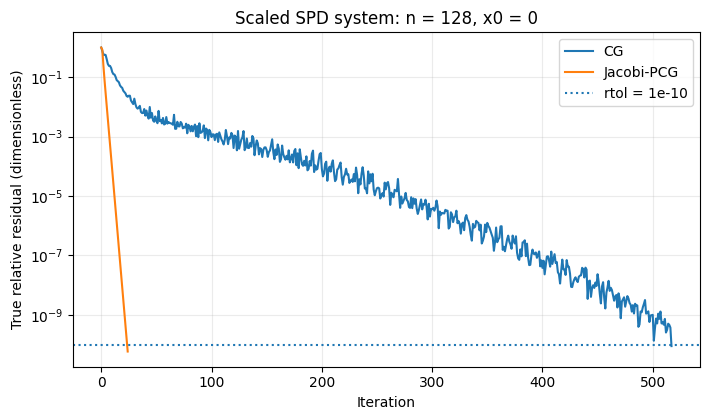

| iteration | CG | Jacobi-PCG |
| --- | --- | --- |
| 0 | 1 | 1 |
| 1 | 0.767214 | 0.836528 |
| 2 | 0.564883 | 0.241461 |
| 3 | 0.576209 | 0.0803983 |
| 4 | 0.55939 | 0.0288412 |
| 5 | 0.402284 | 0.0105882 |
| 6 | 0.278866 | 0.0039082 |
| 7 | 0.241138 | 0.00144326 |
| 8 | 0.240198 | 0.000532615 |
| 9 | 0.203877 | 0.000196375 |
| 10 | 0.149742 | 7.23382e-05 |
| 11 | 0.12735 | 2.66247e-05 |

展示前12行；完整518行已保存到CSV。
{'CG_iterations': 23, 'PCG_iterations': 23, 'CG_error': 4.460273255517841e-11, 'PCG_error': 4.460272381566636e-11}
CG rejects zero curvature : expected LinAlgError
CG rejects nonpositive preconditioner : expected ValueError
4.2证据： {'rows': [{'method': 'CG', 'iterations': 517, 'relative_residual': 8.891198676414179e-11, 'solution_error': 1.1763221982277092e-08, 'median_s': 0.02248729999701027}, {'method': 'Jacobi-PCG', 'iterations': 24, 'relative_residual': 5.84311264156839e-11, 'solution_error': 5.2499254713977846e-11, 'median_s': 0.001309600003878586}], 'condition': 30888.662085499334, 'preconditioned_condition': 4.996443747214051, 'jacobi_setup_median_s': 2.5000044843181968e-06, 'n': 128, 'rtol': 1e-10, 'repeats': 9}


In [60]:
# 4.2 误差图表与比较
# 绘制真实相对残差历史，记录迭代次数、实际误差和预条件设置成本；另做控制实验和异常输入检查。
save_table('E42-cg-pcg', rows42)
print('cond2(A)=', kappa, 'cond2(M^-1/2 A M^-1/2)=', kappa_pre)
print('Jacobi setup median seconds:', setup_s, '; included total = setup + PCG solve')

%matplotlib inline
plt.figure(figsize=(7.2, 4.3))
for label, hh in histories.items():
    plt.semilogy(range(len(hh)), hh, label=label)
plt.axhline(1e-10, linestyle=':', label='rtol = 1e-10')
plt.xlabel('Iteration')
plt.ylabel('True relative residual (dimensionless)')
plt.title('Scaled SPD system: n = 128, x0 = 0')
plt.grid(True, alpha=.25)
plt.legend()
finish_plot('A-初稿-CG残差.png')

save_table(
    'E42-residual-history',
    [{
        'iteration': k,
        'CG': histories['CG'][k] if k < len(histories['CG']) else '',
        'Jacobi-PCG': histories['Jacobi-PCG'][k] if k < len(histories['Jacobi-PCG']) else ''
    } for k in range(max(map(len, histories.values())))]
)

b_control = T @ x42
xc, hc, ic = pcg(T, b_control)
xp, hp, ip = pcg(T, b_control, np.diag(T))
check('Constant diagonal control converges', ic == 0 and ip == 0)
check('Constant diagonal control solution', relerr(xc, x42) < 1e-8 and relerr(xp, x42) < 1e-8)
control = {
    'CG_iterations': len(hc) - 1,
    'PCG_iterations': len(hp) - 1,
    'CG_error': relerr(xc, x42),
    'PCG_error': relerr(xp, x42)
}
print(control)
results['cg_control'] = control

xz, hz, iz = pcg(np.eye(3), np.zeros(3))
check('Zero RHS immediate stop', iz == 0 and len(hz) == 1 and np.all(xz == 0))
expect_error('CG rejects zero curvature', lambda: pcg(np.diag([1., -1.]), np.ones(2)), np.linalg.LinAlgError)
expect_error('CG rejects nonpositive preconditioner', lambda: pcg(np.eye(2), np.ones(2), [1, -1]), ValueError)

print('4.2证据：', results.get('cg'))

### 结果解释与本节结论

| 方法 | 迭代次数 | 真实相对残差 | 相对解误差 | 求解时间中位数（秒） |
| --- | ---: | ---: | ---: | ---: |
| CG | $517$ | $8.8912\times10^{-11}$ | $1.17632\times10^{-8}$ | $0.0171246$ |
| Jacobi-PCG | $24$ | $5.84311\times10^{-11}$ | $5.24993\times10^{-11}$ | $0.000992$ |

原矩阵条件数 $\operatorname{cond}_2(A_{\mathrm{cg}})\approx30888.6621$；对称预条件变换后的条件数约为 $4.99644$，下降约 $6182$ 倍。Jacobi-PCG 将迭代次数由 $517$ 次降至 $24$ 次，减少约 $95.36\%$。两种方法的真实相对残差均达到 $10^{-11}$ 量级，解误差也均小于 $10^{-6}$。本次计时中，CG 求解中位数为 $0.0171246\,\mathrm{s}$，Jacobi-PCG 求解中位数为 $0.000992\,\mathrm{s}$；Jacobi 预处理建立时间中位数为 $2.8\times10^{-6}\,\mathrm{s}$，计入建立成本后总时间约为 $0.0009948\,\mathrm{s}$。本次运行的含预处理总耗时仍约快 $17$ 倍，但该计时仅代表当前 CPU、矩阵规模和运行环境，不应外推为普遍加速比。

控制实验使用常数对角矩阵 $T$，CG 与 Jacobi-PCG 均为 $23$ 次迭代，解误差约 $4.46\times10^{-11}$，说明预条件器并非仅因“加入对角矩阵”就必然减少迭代；效果取决于它是否改善了问题的谱性质。残差历史图的横轴为迭代次数，纵轴为真实相对残差（无量纲），并标出 $10^{-10}$ 停止线。

尚未验证不同矩阵规模、不同预条件器（如不完全 Cholesky）、稀疏存储格式和多线程与多设备条件下的性能。

### 易错点与讨论

1. **残差与解误差的区别**：残差是输出端的误差，解误差是输入端的误差。条件数描述了从输出端误差到输入端误差的放大倍数。小残差只在条件数不很大时才能保证小解误差。

2. **预条件改善的对象**：预条件改善的是预条件后系统的条件数，从而加快 CG 的收敛，不是解本身，也不是问题的病态性。预条件 CG 的总成本需要同时计入迭代次数的减少和每步迭代中应用预条件子的额外开销。对角预条件每步成本 $O(n)$。

3. **CG 的适用条件**：$A$ 必须对称正定。若 $A$ 非对称或非正定，标准 CG 不适用，需要其他 Krylov 方法。

4. **最速下降法与 CG 的区别**：最速下降法沿负梯度方向搜索，相邻方向正交，收敛慢；CG 选择共轭方向，避免重复搜索，收敛快。

**随堂提问：** 设 $A=\operatorname{diag}(1,10,100,1000)$，$b=(1,1,1,1)^T$，$n=4$，$\kappa_2(A)=1000$。

(1) 写出对角预条件子 $M=\operatorname{diag}(A)$，计算 $M^{-1}A$ 的条件数。

(2) 用 CG 误差上界 $2\left(\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\right)^k$ 估算标准 CG 达到容差 $10^{-6}$ 所需迭代次数 $k_{\mathrm{CG}}$（$\kappa=1000$）；PCG 因 $M^{-1}A=I$，理论 1 步收敛。

(3) 设每步矩阵-向量乘法成本为 $n$，预条件构造成本为 $n$，预条件应用成本为 $n/步$。分别写出 CG 和 PCG 的总成本表达式，代入 $k_{\mathrm{CG}}$ 比较。

(4) 若预条件构造成本改为 $n^2$（如不完全 Cholesky），PCG 总成本在什么条件下仍低于 CG？这对选择预条件子有什么启示？

**可能的回答：**

- 一部分同学只比较迭代次数（230 次 vs 1 次），认为 PCG 一定更快，没有把预条件构造和应用的成本计入；
- 一部分同学能算出 CG 总成本约 $230\times4=920$，但 PCG 只写“1 步”，漏掉构造 $n$ 和应用 $n$；
- 对第 (4) 问，一部分同学只会说“构造贵了就不划算”，没有给出具体的成本不等式。

**解释：**

1. $M=\operatorname{diag}(1,10,100,1000)$，$M^{-1}A=I$，条件数降为 $1$。
2. $\kappa=1000$，$\sqrt{\kappa}\approx31.6$，$\frac{\sqrt{\kappa}-1}{\sqrt{\kappa}+1}\approx0.939$；由 $2\times0.939^k\leqslant10^{-6}$ 得 $k_{\mathrm{CG}}\approx230$。PCG 理论 1 步。
3. CG 总成本 $\approx230\times n=920$；PCG 总成本 $=n$（构造）$+1\times n$（应用）$=8$。PCG 远低于 CG。
4. 若构造成本为 $n^2=16$，PCG 总成本 $=16+4=20$，仍远低于 $920$。要让 PCG 不划算，需构造成本 $>920-4=916$，即约 $57n^2$，实际中少见。启示：对角预条件构造成本低，通常总成本也低；但不完全 Cholesky 等构造昂贵的预条件子，需要权衡“迭代次数减少”与“构造开销增加”，不能只看迭代次数。

### 小结

迭代法的核心是**收敛性**和**收敛速度**，两者都由迭代矩阵的**谱性质**决定。4.2 节从线性定常迭代出发，把收敛性归结为谱半径判据，再以 CG 作为对称正定系统的高效迭代法，最后用预条件改善条件数。方法选择可以归纳为以下几步：

1. **先看迭代框架。** 线性定常迭代 $x^{(k+1)}=Bx^{(k)}+f$ 的收敛性由谱半径 $\rho(B)<1$ 决定；$\rho(B)$ 越小，$B^k$ 衰减越快，收敛越快。

2. **再看矩阵结构。** 对称正定系统用 CG：它把解方程转化为二次函数最小化，沿 $A$-共轭方向搜索，在精确算术下至多 $n$ 步收敛；适用条件是 $A$ 对称正定。

3. **最后看条件数。** CG 的收敛速度由 $\kappa(A)$ 支配，$\kappa(A)$ 越接近 $1$ 收敛越快。预条件通过改善预条件后系统的条件数来加速收敛，但改善的是收敛速度，不是问题的病态性；总成本需同时计入迭代次数的减少和预条件子的构造、应用开销。

**适用条件与要点：** CG 要求 $A$ 对称正定，非对称或非正定时标准 CG 不适用；预条件子 $M$ 需对称正定且 $M^{-1}$ 易计算；残差小不等于解误差小，条件数决定了残差到解误差的放大倍数，讨论“残差小”时必须说明残差针对哪个右端计算。

### 4.2 实际运行记录

控制实验验证常数对角预条件不会凭缩放本身减少迭代步数。

<a id="sec-4-3"></a>

## 4.3 特征值与 SVD（2 学时）

**本节目标：** 能区分两种分解，并用奇异值解释敏感性和低秩近似。

### 概念讲解：把问题说明白

[4.1](#sec-4-1) 和 [4.2](#sec-4-2) 分别讨论了求解 $Ax=b$ 的直接法和迭代法。两种方案各有侧重：直接法关心如何稳定、高效地分解矩阵；迭代法关心如何加快并保持收敛速度。但在分析误差时，这两节都有一个概念反复出现——矩阵的[**条件数**](#def-4-4)。

在直接法中，条件数决定了舍入误差的放大倍数；在迭代法中，条件数支配了 CG 的收敛速度。那么，条件数究竟由矩阵的什么结构决定？为什么同样是 $n$ 阶方阵，有的“轻轻一碰就跳”，有的“怎么扰动都稳”？只看 $A$ 的元素，很难回答；得看 $A$ 在各个方向上能够让空间如何伸缩。这正是特征值和奇异值要刻画的事。

<a id="sec-4-3-1"></a>

### 4.3.1 特征值与幂迭代算法

**特征值与特征向量**是理解矩阵结构的第一把钥匙。回顾基础定义：

<a id="def-4-11"></a>

> **定义 4.11（特征值与特征向量）**  
> 对方阵 $A$，若存在数 $\lambda$ 和非零向量 $v$，使得 $Av=\lambda v$，则称 $\lambda$ 为 $A$ 的特征值，$v$ 称为 $\lambda$ 的一个特征向量。

如果 $n$ 阶方阵 $A$ 有 $n$ 个线性无关的特征向量，那么 $A$ 可以在这组基下对角化：

<a id="eq-4-11"></a>

$$
A=V\Lambda V^{-1} \tag{4.11}
$$

特征值具有明确的几何意义：将方阵 $A$ 看作对向量的线性变换时，若作用在 $A$ 的一个特征向量 $v$ 上，则不改变向量的方向，只改变其长度，且伸缩因子为对应的特征值 $\lambda$。若 $A$ 可对角化，那么 $A$ 的作用完全可以看作由它在各个特征方向上的伸缩作用的复合。因此，研究方阵 $A$ 对一般向量的作用时，可以把 $A$ 的所有特征向量作为一组基，这样研究矩阵的作用时会更加方便。

特征值在矩阵的相关计算方面最常见的应用是求方阵的幂次。由对角化分解 $A=V\Lambda V^{-1}$ ，即得 $A^n=V\Lambda^nV^{-1}$。我们可以利用这个结果更便捷地计算 $A^n$，在求解关于 $A$ 的微分方程，以及一些迭代问题的计算中，这种方法非常重要（不可对角化的方阵可以利用 Jordan 标准型计算幂次，但不是本章重点，不再展开讲解）。特征值还可以用于判断矩阵是否奇异（有零特征值则奇异），以及用来分析矩阵的稳定性（谱半径 $\rho(A)=\max\limits_{1\leqslant i\leqslant n}|\lambda_i|$ 和迭代法的收敛性有关）。此外，特征值还有以下两个基本性质：

<a id="eq-4-12"></a>

$$
\det(A)=\lambda_1\lambda_2\cdots\lambda_n,\qquad
\operatorname{tr}(A)=\lambda_1+\lambda_2+\cdots+\lambda_n.
\tag{4.12}
$$

这两个式子分别联系了特征值与行列式、迹这些矩阵中的重要概念，在理论分析和实际计算中都十分有用。

进一步地，我们希望研究：矩阵作用对向量的影响主要取决于什么？我们通过研究矩阵对向量反复作用，放大其影响效果的方法来说明这一点。为了方便研究，假设 $A$ 的特征值按模长大小排列为：$|\lambda_1|>|\lambda_2|\geqslant \cdots \geqslant|\lambda_n|$，其中 $\lambda_i$ 对应特征向量 $v_i (i=1,2,\cdots,n)$，$|\lambda_1|$ 为严格最大特征值。那么对任意初值 $x_0$，先用 $A$ 的特征向量表示为

$$
x_0=c_1v_1+c_2v_2+ \cdots +c_nv_n,
$$

假设 $c_1\neq0$，反复左乘 $A$，得到：

$$
x_k=A^kx_0 =c_1\lambda_1^k v_1+c_2\lambda_2^k v_2+\cdots+c_n\lambda_n^k v_n.
$$

$k$ 充分大时，$\lambda_1^k$ 相对来说远大于其他项，归一化之后，方向会越来越由 $v_1$ 主导。每左乘一次 $A$，各个特征方向上的分量就按各自的特征值被放大一次。$|\lambda_1|$ 最大，它的分量就涨得最快；乘的次数越来越多，其他方向的分量相对就成了零头。归一化只改长度、不改方向，所以 $x_k$ 的方向会越来越贴近 $v_1$——就像生物繁衍，增长率最快的种群最终便会压倒其余。

这就是**幂迭代**的思想：如果反复用矩阵左乘向量，最大特征值对应的向量会逐渐占据主导地位，因此也被称为主特征向量方向。

<a id="def-4-12"></a>

> **定义 4.12（幂迭代）**  
> 给定初值 $x_0$，按 $y_k=Ax_{k-1}$、$x_k=\dfrac{y_k}{\|y_k\|}$ 迭代，用 Rayleigh 商 $\lambda_1^{(k)}\approx\dfrac{x_k^TAx_k}{x_k^Tx_k}$ 估计最大特征值。

$$
y_k=Ax_{k-1},\qquad x_k=\frac{y_k}{\|y_k\|},
$$

则最大特征值 $\lambda_1$ 可用 Rayleigh 商估计，第 $k$ 步得到的估计为：

<a id="eq-4-13"></a>

$$
\lambda_1^{(k)}\approx \frac{x_k^TAx_k}{x_k^Tx_k}. \tag{4.13}
$$

需要强调这里的条件：最大模特征值 $\lambda_1$ 的模必须严格最大；初值 $x_0$ 在主特征向量方向上的展开系数 $c_1$ 不能为零，可以通过合理选取初值来保证这一点；矩阵最好可对角化，否则不能保证收敛。上述三条中任一条不满足，简单幂迭代就可能失效。

<a id="sec-4-3-2"></a>

### 4.3.2 从特征值到奇异值

尽管特征值是一个对于研究矩阵非常重要的概念，特征值分解也还是有两个重要局限：其一，它只适用于方阵；其二，即使对于方阵，也并非所有矩阵都能对角化。因此，我们需要在一般的矩阵上寻找一个具有类似概念和作用的值，并找到一种分解，它对任意矩阵都存在，且像特征值分解一样，能揭示矩阵在若干方向上的伸缩作用的效果。**奇异值分解**（Singular Value Decomposition，SVD）克服了特征值的上述局限：

<a id="def-4-13"></a>

<a id="eq-4-14"></a>

> **定义 4.13（奇异值分解，SVD）**  
> 对任意 $m\times n$ 实矩阵 $A$，都存在分解
> $$\boxed{\,A=U\Sigma V^T\,} \tag{4.14}$$
> 其中 $U$ 为 $m$ 阶正交矩阵，$V$ 为 $n$ 阶正交矩阵，$\Sigma$ 为 $m\times n$ 矩形对角矩阵，对角元 $\sigma_1\geqslant\sigma_2\geqslant\cdots\geqslant\sigma_{\min(m,n)}\geqslant0$ 称为奇异值。

这一分解对任意矩阵都存在，不要求方阵、可逆或对称。正交矩阵 $U$ 和 $V$ 的列向量分别称为左奇异向量和右奇异向量。

SVD 的几何含义是：任意矩阵 $A$ 的作用可以分解为三步——先用 $V^T$ 旋转（或反射）输入空间，再用 $\Sigma$ 沿坐标轴伸缩，最后用 $U$ 旋转输出空间。因此，若 $A$ 把单位球映射为一个椭球，则椭球的半轴长度就对应着矩阵的奇异值。

奇异值与特征值之间有明确的联系。对矩阵 $A=U\Sigma V^T$，把 SVD 代入 $A^TA$ 和 $AA^T$，直接展开就得到了右、左奇异向量：

$$
\begin{aligned}
A=U\Sigma V^T
&\;\Longrightarrow\; A^TA=V\Sigma^T\Sigma V^T
\;\Longrightarrow\; \text{特征值 }\sigma_i^2,\ \text{特征向量 }V\text{ 的列};\\
A=U\Sigma V^T
&\;\Longrightarrow\; AA^T=U\Sigma\Sigma^TU^T
\;\Longrightarrow\; \text{特征值 }\sigma_i^2,\ \text{特征向量 }U\text{ 的列}.
\end{aligned}
$$

因此在理论上，奇异值可以通过求出 $A^TA$ 的特征值再开方得到。

不过，数值计算中通常不直接计算 $A^TA$ 的特征值，因为这样会很容易损失精度：$A^TA$ 的条件数是 $A$ 的条件数的平方，舍入误差会被放大。实际使用的是专门的 SVD 算法，一般是直接对 $A$ 做正交变换，避免形成 $A^TA$。但 $A^TA$ 的特征值分解在理论分析中仍然重要，它建立了 SVD 与对称矩阵特征值分解的联系。这一联系为 SVD 的数值计算提供了理论基础。更重要的是，奇异值总为非负实数，且左、右奇异向量各自构成正交系，这比特征向量（可能复数、可能不正交）具有更良好的性质。

幂迭代方法的目标是寻找方阵最大特征值的方向，而 SVD 可看作把“找主方向”的思想推广到任意矩阵：右奇异向量 $v_i$ 是 $A^TA$ 的特征向量，左奇异向量 $u_i$ 是 $AA^T$ 的特征向量，奇异值 $\sigma_i$ 是 $A^TA$ 特征值的平方根。因此 SVD 同时给出输入空间和输出空间的一对主方向，比特征值分解更通用。

秩与奇异值之间有直接的关系。设矩阵 $A$ 的秩 $r=\operatorname{rank}(A)$，则 $A$ 非零奇异值的个数即为 $r$。若从数值计算角度出发，当某些奇异值极小时，数值运算中会被视为 $0$，因此矩阵的“数值秩”可能小于理论秩。

条件数与奇异值之间也有紧密的关系。设 $A=U\Sigma V^T$ 可逆，则 $A^{-1}=V\Sigma^{-1}U^T$，奇异值为 $\dfrac{1}{\sigma_i}(i=1,2,\cdots,n)$。因此

$$
\|A\|_2=\sigma_1,\qquad
\|A^{-1}\|_2=\frac{1}{\sigma_{\min}},\qquad
\kappa_2(A)=\|A\|_2\|A^{-1}\|_2=\frac{\sigma_1}{\sigma_{\min}}.
$$

特别地，当 $A$ 为对称方阵时，

$$
\kappa_2(A)=\frac{\max\limits_{1\leqslant i \leqslant n}|\lambda_i|}{\min\limits_{1\leqslant i \leqslant n}|\lambda_i|}.
$$

可以由上式推出条件数的一些基本性质，在处理相关问题时很有用：

1. 对任何非奇异矩阵 $A$，都有 $\kappa(A)\geqslant 1$；
2. 对任何非零常数 $c$，$\kappa(cA)=\kappa(A)$；
3. 若 $Q$ 为正交矩阵，则 $\kappa(QA)=\kappa(AQ)=\kappa(A)$。

性质 3 说明，正交变换不改变条件数，这也是 SVD 数值稳定的原因之一：SVD 只使用正交变换。

需要特别强调：**非对称矩阵的特征值绝对值一般不等于奇异值**。比如取 $J=\begin{pmatrix}1&10\\0&1\end{pmatrix}$，则 $J$ 是上三角矩阵，特征值为主对角元，因此两个特征值均为 $1$。而 $J^TJ=\begin{pmatrix}1&10\\10&101\end{pmatrix}$，其特征值为 $51\pm10\sqrt{26}$，开方得 $J$ 的奇异值约为 $\sigma_1\approx10.09902,\sigma_2\approx0.09902$。

显然 $J$ 的奇异值不等于其特征值的绝对值。实对称矩阵确有“奇异值等于特征值绝对值”的性质，更一般的正规矩阵也有相应结论，但不能推广到任意非对称矩阵。这个反例说明：SVD 给出的奇异值不是特征值的简单推广，而是通过 $A^TA$ 的特征值来定义的另一套谱信息。非对称矩阵的特征值绝对值不能直接刻画矩阵在所有方向上的伸缩，这正是需要 SVD 的原因。

<a id="sec-4-3-3"></a>

### 4.3.3 从奇异值角度重新看矩阵

**奇异值分解与敏感性**的联系是本节的核心。考虑 $Ax=b$，$A$ 可逆。若右端有扰动 $\delta b$，解的变化满足 $A\delta x=\delta b$，即 $\delta x=A^{-1}\delta b$。将 SVD 代入，$A^{-1}=V\Sigma^{-1}U^T$。扰动量 $\delta b$ 若在左奇异向量 $u_i$ 方向上有分量，则解中该分量被放大 $\dfrac{1}{\sigma_i}$ 倍。特别地，沿最小奇异值 $\sigma_{\min}$ 对应的左奇异向量方向上的扰动会被放大最多 $\dfrac{1}{\sigma_{\min}}$ 倍，这是最坏情况下的放大。矩阵在 $\sigma_{\min}$ 对应的方向上压缩效果最明显，几乎把向量压成零；而反推回来时，这个方向上的微小扰动就被放得最大。换句话说，$\sigma_{\min}$ 指向矩阵“最薄弱的环节”：沿这个方向轻轻一推，解就晃得最厉害。因此，最小的奇异值对应着最敏感的方向。扰动放大的推导图如下：

$$
\begin{aligned}
A\delta x=\delta b
&\;\Longrightarrow\; \delta x=A^{-1}\delta b\\
&\;\Longrightarrow\; \delta x=V\Sigma^{-1}U^T\delta b\\
&\;\Longrightarrow\; \delta b\text{ 在 }u_i\text{ 方向的分量被放大 }\frac{1}{\sigma_i}\text{ 倍}\\
&\;\Longrightarrow\; \text{最坏情况沿 }u_{\min}\text{，放大 }\frac{1}{\sigma_{\min}}\text{ 倍}.
\end{aligned}
$$

当 $\sigma_{\min}$ 非常小时，$A$ 接近奇异，矩阵的作用在某个方向上几乎把向量压缩为零，因此逆运算在该方向上的放大极大。下面用手算核验这一放大关系。取

$$
A=\operatorname{diag}(1,10^{-10}).
$$

特征值：对角矩阵的特征值就是对角元，因此

$$
\lambda_1=1,\qquad \lambda_2=10^{-10}.
$$

奇异值：对角矩阵的奇异值等于对角元的绝对值，因此

$$
\sigma_1=1,\qquad \sigma_2=10^{-10}.
$$

对这个对角矩阵，特征值绝对值等于奇异值。条件数

$$
\kappa_2(A)=\frac{\sigma_1}{\sigma_2}=10^{10}.
$$

右端第二分量增加 $10^{-10}$ 后，精确解为 $\widetilde x=(1,2)^T$，而原真解为 $x^*=(1,1)^T$，因此

$$
\|\widetilde x-x^*\|_2=1,\qquad
\frac{\|\widetilde x-x^*\|_2}{\|x^*\|_2}=\frac{1}{\sqrt2}\approx0.707107.
$$

对原右端的相对残差为 $10^{-10}$，对扰动后右端的残差为 $0$。因此，小残差与小解误差是不同主张，残差针对哪个右端必须说明。

设 $A$ 可对角化，$A=V\Lambda V^{-1}$。若 $A$ 有扰动 $\delta A$，则特征值扰动满足

$$
|\lambda_i(A+\delta A)-\lambda_i(A)|
\leqslant\|V\|\,\|V^{-1}\|\,\|\delta A\|_2.
$$

这里 $\|V\|\,\|V^{-1}\|$ 是特征向量矩阵的条件数。对对称矩阵，$V$ 正交，$\|V\|\,\|V^{-1}\|=1$，特征值对扰动不敏感；对非对称矩阵，特征向量矩阵可能病态，特征值对扰动敏感。这进一步说明 SVD 的优势：奇异值对扰动不敏感，因为 SVD 只使用正交变换。

类似地，若系数矩阵本身有扰动 $\delta A$，解的相对误差上界为

<a id="eq-4-15"></a>

$$
\boxed{\,\frac{\|\delta x\|}{\|x\|}\leqslant \kappa_2(A)\frac{\|\delta A\|}{\|A\|}\,} \tag{4.15}
$$

这一估计式与 [4.2](#sec-4-2) 节中残差与解误差的关系式形式一致，条件数总是出现在右端作为放大因子。因此，条件数不仅决定迭代法的收敛速度，也决定问题对输入扰动的敏感程度。它是矩阵结构的一个内在量，与具体的算法无关。

<a id="sec-4-3-4"></a>

### 4.3.4 矩阵的低秩近似

**截断奇异值分解与低秩近似**是 SVD 的另一个核心应用。将 SVD 按列写开，写成外积形式：

$$
A=\sum_{i=1}^{r}\sigma_i u_i v_i^T,
$$

其中 $r=\operatorname{rank}(A)$。每一项是一个秩为 $1$ 的矩阵，$\sigma_i$ 给出该项的“权重”。保留前 $k$ 个最大的奇异值及其对应的奇异向量，得到

$$
A_k=\sum_{i=1}^{k}\sigma_i u_i v_i^T.
$$

<a id="def-4-14"></a>

> **定义 4.14（截断 SVD，低秩近似）**  
> 保留前 $k$ 个最大的奇异值及其对应的奇异向量，得到 $A_k=\sum\limits_{i=1}^{k}\sigma_i u_i v_i^T$，其秩不超过 $k$，称为**截断 SVD**（或低秩近似）。

<a id="thm-eckart-young"></a>

> **定理（Eckart–Young–Mirsky）[3]**：在 Frobenius 范数和谱范数下，截断 SVD $A_k$ 是所有秩不超过 $k$ 的矩阵中与 $A$ 最接近的，误差分别为
> $$\|A-A_k\|_F^2=\sum_{i=k+1}^{r}\sigma_i^2,\qquad\|A-A_k\|_2=\sigma_{k+1}.$$

这一结论说明，奇异值的衰减速度决定了低秩近似的效果：若奇异值迅速衰减，则较小的 $k$ 就能捕捉 $A$ 的主要结构；若奇异值衰减缓慢，则需要较大的 $k$ 才能达到相同的误差。这为 [4.4](#sec-4-4) 节中的 PCA 和 LoRA 提供了理论基础：PCA 用截断 SVD 对中心化数据降维，LoRA 用低秩增量近似参数更新，二者的有效性都依赖于奇异值（或相应结构）的衰减假设。

**Eckart-Young-Mirsky 定理的证明思路。** 设

$$
A_k=\sum_{i=1}^k\sigma_i u_i v_i^T.
$$

则

$$
A-A_k=\sum_{i=k+1}^r\sigma_i u_i v_i^T.
$$

由于 $\{u_i\}$ 和 $\{v_i\}$ 均为正交系，

$$
\|A-A_k\|_F^2=\sum_{i=k+1}^r\sigma_i^2,\qquad
\|A-A_k\|_2=\sigma_{k+1}.
$$

在秩不超过 $k$ 的矩阵集合中，$A_k$ 使上述两个范数同时达到最小。

谱范数的证明思路是：对任意秩不超过 $k$ 的矩阵 $B$，子空间 $\operatorname{span}\{v_1,\cdots,v_{k+1}\}$ 的维数为 $k+1$，故 $B$ 在该子空间上的零空间维数至少为 $(k+1)-k=1$，即存在非零向量 $z\in\operatorname{span}\{v_1,\cdots,v_{k+1}\}$ 使 $Bz=0$；将其归一化，即得单位向量 $z$。于是

$$
\|A-B\|_2\geqslant\|(A-B)z\|_2=\|Az\|_2\geqslant\sigma_{k+1}.
$$

而 $A_k$ 恰好达到该下界。Frobenius 范数的证明类似，利用正交投影和尾部平方和。另一种代数证明的思路是令 $C=U^TBV$，则 $\|A-B\|_2=\|\Sigma-C\|_2\geqslant\sigma_{k+1}$，当 $C=\operatorname{diag}(\sigma_1,\dots,\sigma_k,0,\dots,0)$ 时取等（对应 $B=A_k$），这里不再详细展开。

**低秩近似的现实意义** 截断 SVD 把矩阵拆成按重要性排序的若干模式，大奇异值对应主要结构，小奇异值则对应细节或噪声。图像压缩只保留前 $k$ 个奇异值 $\sigma_1,\dots,\sigma_k$ 及对应的奇异向量 $u_i,v_i$，用远少于原始像素的数据近似原图；奇异值衰减越快，压缩效果越好。数据降噪则丢掉分散噪声的小奇异值再重构，保留主要信号。这两类用途都依赖奇异值快速衰减，[4.4](#sec-4-4) 节将说明低秩思想在数据降维等场景中的应用。秩与条件数已在 [4.3.2](#sec-4-3-2) 和 [4.3.3](#sec-4-3-3) 涉及。

### 关键推导：让结论有依据

**推导 1：奇异值分解的计算实例** 取

$$
A=\begin{pmatrix}
3 & 0\\
4 & 5
\end{pmatrix},
$$

对它做奇异值分解 $A=U\Sigma V^T$。

**第一步：计算 $A^TA$。**

$$
A^T A=
\begin{pmatrix}
3 & 4\\
0 & 5
\end{pmatrix}
\begin{pmatrix}
3 & 0\\
4 & 5
\end{pmatrix}
=
\begin{pmatrix}
25 & 20\\
20 & 25
\end{pmatrix}.
$$

**第二步：求特征值和奇异值。** 解

$$
\det(A^T A-\lambda I)
=(25-\lambda)^2-400=0,
$$

得到 $\lambda_1=45$，$\lambda_2=5$，因此奇异值为

$$
\sigma_1=\sqrt{45}=3\sqrt5,\qquad \sigma_2=\sqrt5,
$$

按从大到小排列为 $\Sigma=\operatorname{diag}(3\sqrt5,\sqrt5)$。

**第三步：求右奇异向量。** 对应 $\lambda_1=45$ 的单位特征向量为

$$
v_1=\frac{1}{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix},
$$

对应 $\lambda_2=5$ 的单位特征向量为

$$
v_2=\frac{1}{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix},
$$

因此

$$
V=
\begin{pmatrix}
\frac{1}{\sqrt2} & \frac{1}{\sqrt2}\\[4pt]
\frac{1}{\sqrt2} & -\frac{1}{\sqrt2}
\end{pmatrix}.
$$

**第四步：求左奇异向量。** 利用 $u_i=\dfrac{A v_i}{\sigma_i}$：

$$
u_1=\frac{A v_1}{\sigma_1}
=
\begin{pmatrix}
\frac{1}{\sqrt{10}}\\[4pt]
\frac{3}{\sqrt{10}}
\end{pmatrix},
\qquad
u_2=\frac{A v_2}{\sigma_2}
=
\begin{pmatrix}
\frac{3}{\sqrt{10}}\\[4pt]
-\frac{1}{\sqrt{10}}
\end{pmatrix},
$$

所以

$$
U=
\begin{pmatrix}
\frac{1}{\sqrt{10}} & \frac{3}{\sqrt{10}}\\[4pt]
\frac{3}{\sqrt{10}} & -\frac{1}{\sqrt{10}}
\end{pmatrix}.
$$

**第五步：写出 SVD 结果并核验。**

$$
A=
\begin{pmatrix}
\frac{1}{\sqrt{10}} & \frac{3}{\sqrt{10}}\\[4pt]
\frac{3}{\sqrt{10}} & -\frac{1}{\sqrt{10}}
\end{pmatrix}
\begin{pmatrix}
3\sqrt5 & 0\\
0 & \sqrt5
\end{pmatrix}
\begin{pmatrix}
\frac{1}{\sqrt2} & \frac{1}{\sqrt2}\\[4pt]
\frac{1}{\sqrt2} & -\frac{1}{\sqrt2}
\end{pmatrix}
=
\begin{pmatrix}
3 & 0\\
4 & 5
\end{pmatrix}.
$$

**第六步：秩 1 近似与误差。** 只保留最大奇异值，得到

$$
A_1=\sigma_1 u_1 v_1^T
=
3\sqrt5
\begin{pmatrix}
\frac{1}{\sqrt{10}}\\[4pt]
\frac{3}{\sqrt{10}}
\end{pmatrix}
\begin{pmatrix}
\frac{1}{\sqrt2} & \frac{1}{\sqrt2}
\end{pmatrix}
=
\begin{pmatrix}
1.5 & 1.5\\
4.5 & 4.5
\end{pmatrix}.
$$

原始矩阵与近似矩阵之差为

$$
A-A_1=
\begin{pmatrix}
1.5 & -1.5\\
-0.5 & 0.5
\end{pmatrix},
$$

其 Frobenius 范数误差为

$$
\|A-A_1\|_F
=\sqrt{1.5^2+(-1.5)^2+(-0.5)^2+0.5^2}
=\sqrt5\approx2.236,
$$

这正好等于第二个奇异值 $\sigma_2$。原始矩阵的总能量为 $\sigma_1^2+\sigma_2^2=45+5=50$；只保留第一个奇异值后，保留的能量为 $45$，能量保留比例为 $\frac{45}{50}=90\%$。也就是说，只用一个主要模式，就保留了原矩阵约 90% 的信息。这一结果与本节截断 SVD 的误差公式 $\|A-A_1\|_F=\sigma_2$ 一致，也说明奇异值衰减速度决定低秩近似的效果。

### 实验设计：先预测，再运行

实验任务：运行现有敏感性例子，再对小矩阵做不同秩截断，比较保留奇异值与重构误差。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 研究矩阵条件数如何放大右端扰动对解的影响，并区分残差小与解误差小；验证非对称剪切矩阵的特征值与奇异值并不相同；考察截断 SVD 的秩、重构误差和保留能量之间的关系。预测：条件数越大，固定右端扰动造成的解误差越大；秩越高，截断误差越小、保留能量越高。 |
| 输入、参数、单位、数据来源与划分 | 敏感性例：$A_{43}=\operatorname{diag}(1,10^{-10})$、真解 $x^*=(1,1)^T$、原右端 $b=A_{43}x^*$，扰动 $\delta b=(0,10^{-10})^T$；另将小对角元依次设为 $10^{-2},10^{-4},\ldots,10^{-14}$ 做条件数扫描。特征值例：剪切矩阵 $J=\begin{pmatrix}1&10\\0&1\end{pmatrix}$；幂迭代例 $K=\operatorname{diag}(5,2,-1)$。SVD 主例为 $8\times6$ 合成矩阵，预设奇异值 $(8,4,2,1,0.5,0.1)$，正交因子由种子 `2026` 的随机矩阵 QR 分解构造。全部为无量纲合成数据，无数据集划分。 |
| 独立参考解/基线及选择理由 | 敏感性扫描使用解析解误差公式 $\frac{10^{-10}}{\varepsilon\sqrt{2}}$ 作独立预测；剪切矩阵使用解析特征值 $(1,1)$ 和解析奇异值作基准；SVD 使用预先指定的奇异值谱及截断尾部奇异值公式作为参考，不仅依赖数值分解本身。 |
| 误差指标、容差及其依据 | 敏感性例记录 $\operatorname{cond}_2(A)$、相对于原右端的相对残差、相对于扰动右端的相对残差及相对解误差；扫描解析公式比较采用 $\mathrm{rtol}=10^{-7}$、$\mathrm{atol}=10^{-14}$。SVD 记录谱范数误差、Frobenius 范数误差和保留能量；截断误差与解析尾部比较的绝对容差为 $2\times10^{-12}$。幂迭代记录特征值残差 $\lVert Kv-\lambda v\rVert_2$。 |
| 环境、种子、设备与运行预算 | Python `3.12.10`、NumPy `1.26.4`、SciPy `1.14.1`；CPU、`float64`、种子 `2026`，线程数限制为 $1$。矩阵规模最大为 $8\times6$（敏感性扫描为 $2\times2$）；SVD 截断秩从 $0$ 到 $6$。 |


### 已有起步实验：先运行并解释

小残差与大解误差的对角矩阵示例用于联系奇异值和条件数；不代表已完成LU、CG或AI应用。

以下保留原有代码供阅读、修改和复现。它只是本节的一个基线；本节后续已继续完成敏感性扫描、特征值/奇异值区分、幂迭代和截断SVD实验。

In [61]:
# 4.3 已有起步实验
# 先运行并解释病态对角系统的敏感性基线：残差可为零，但相对解误差仍可很大。
A43 = np.diag([1., 1e-10])
x43 = np.ones(2)
b43 = A43 @ x43
pert = np.array([0., 1e-10])
xp43 = np.linalg.solve(A43, b43 + pert)

sensitivity = {
    'x_original': x43.tolist(),
    'x_perturbed': xp43.tolist(),
    'original_relative_residual': relerr(A43 @ xp43, b43),
    'perturbed_relative_residual': relerr(A43 @ xp43, b43 + pert),
    'relative_solution_error': relerr(xp43, x43),
    'condition': float(np.linalg.cond(A43))
}
print(json.dumps(sensitivity, indent=2))
results['sensitivity'] = sensitivity

check('Opening example exact perturbed solution', np.allclose(xp43, [1, 2], rtol=0, atol=1e-14))
check('Opening example solution error', abs(relerr(xp43, x43) - 1 / np.sqrt(2)) < 1e-14)
check('Opening example residual distinction',
      relerr(A43 @ xp43, b43) > 0 and relerr(A43 @ xp43, b43 + pert) < 1e-15)


{
  "x_original": [
    1.0,
    1.0
  ],
  "x_perturbed": [
    1.0,
    2.0
  ],
  "original_relative_residual": 1e-10,
  "perturbed_relative_residual": 0.0,
  "relative_solution_error": 0.7071067811865475,
  "condition": 10000000000.0
}


In [62]:
# 4.3 输入与独立参考
# 准备剪切矩阵、幂迭代输入和8×6预设奇异值谱矩阵；题3的 A/B/C/M/D 也在此给出。
J = np.array([[1., 10.], [0., 1.]])
K = np.diag([5., 2., -1.])
v = np.ones(3) / np.sqrt(3)

rng_svd = np.random.default_rng(SEED)
QU = np.linalg.qr(rng_svd.normal(size=(8, 6)), mode='reduced')[0]
QV = np.linalg.qr(rng_svd.normal(size=(6, 6)))[0]
s_ref = np.array([8., 4., 2., 1., .5, .1])
Alow = (QU * s_ref) @ QV.T

# 题3：A/B/C/M/D 的输入。
A_q3 = np.array([[0., 1.], [0., 0.]])
B_q3 = np.array([[1., 2.], [2., 1.]])
C_q3 = np.diag([3., 1., -2.])
M_q3 = np.ones((3, 3))
M_q3[2, 2] += 1e-6
D_q3 = np.array([[1., 2., 3.], [4., 5., 6.], [7., 8., 9.]])

In [63]:
# 4.3 方法实现与运行
# 计算剪切矩阵特征值/奇异值、幂迭代，并运行8×6矩阵的秩0—6截断SVD。
eig_J = np.linalg.eigvals(J)
sig_J = np.linalg.svd(J, compute_uv=False)
smax = np.sqrt(51 + 10 * np.sqrt(26))
sig_exact = np.array([smax, 1 / smax])
check('Shear eigenvalues', np.allclose(eig_J, [1, 1]))
check('Shear singular values analytic', np.allclose(sig_J, sig_exact, rtol=1e-12, atol=1e-14))
check('Eigenvalues are not singular values', not np.allclose(np.abs(eig_J), sig_J))

v_power = np.ones(3) / np.sqrt(3)
for _ in range(30):
    v_power = K @ v_power
    v_power /= np.linalg.norm(v_power)
lam = float(v_power @ K @ v_power)
eig_res = float(np.linalg.norm(K @ v_power - lam * v_power))
check('Power method target', abs(lam - 5) < 1e-12 and eig_res < 1e-10)

v_bad = np.array([0., 1., 0.])
for _ in range(10):
    v_bad = K @ v_bad
    v_bad /= np.linalg.norm(v_bad)
check('Power method missing projection', float(v_bad @ K @ v_bad) == 2.)
print('Shear eigenvalues:', eig_J, '; singular values:', sig_J)
print('Power iteration lambda:', lam, '; residual:', eig_res, '; wrong-start lambda:', v_bad @ K @ v_bad)
results['eigen'] = {
    'shear_eigenvalues': eig_J.tolist(),
    'shear_singular_values': sig_J.tolist(),
    'power_lambda': lam,
    'power_residual': eig_res
}

u, s, vt = np.linalg.svd(Alow, full_matrices=False)
check('Prescribed singular spectrum', np.allclose(s, s_ref, rtol=1e-12, atol=1e-13))

svd_rows = []
for rank in range(7):
    Ar = (u[:, :rank] * s[:rank]) @ vt[:rank]
    spec = float(np.linalg.norm(Alow - Ar, 2))
    fro = float(np.linalg.norm(Alow - Ar, 'fro'))
    ref_spec = float(s_ref[rank]) if rank < 6 else 0.
    ref_fro = float(np.linalg.norm(s_ref[rank:]))
    check(f'SVD rank {rank} spectral tail', abs(spec - ref_spec) < 2e-12)
    check(f'SVD rank {rank} Frobenius tail', abs(fro - ref_fro) < 2e-12)
    svd_rows.append({
        'rank': rank,
        'spectral_error': spec,
        'spectral_reference': ref_spec,
        'Frobenius_error': fro,
        'Frobenius_reference': ref_fro,
        'retained_energy': float(np.sum(s_ref[:rank] ** 2) / np.sum(s_ref ** 2))
    })
results['svd'] = svd_rows

Shear eigenvalues: [1. 1.] ; singular values: [10.09901951  0.09901951]
Power iteration lambda: 5.0 ; residual: 3.458764513820542e-12 ; wrong-start lambda: 2.0


| condition | solution_error | analytic_error |
| --- | --- | --- |
| 100 | 7.07107e-09 | 7.07107e-09 |
| 10000 | 7.07107e-07 | 7.07107e-07 |
| 1e+06 | 7.07107e-05 | 7.07107e-05 |
| 1e+08 | 0.00707107 | 0.00707107 |
| 1e+10 | 0.707107 | 0.707107 |
| 1e+12 | 70.7107 | 70.7107 |
| 1e+14 | 7071.07 | 7071.07 |

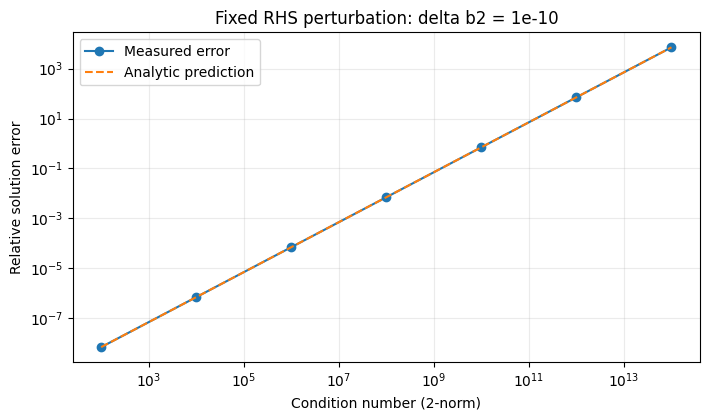

| rank | spectral_error | spectral_reference | Frobenius_error | Frobenius_reference | retained_energy |
| --- | --- | --- | --- | --- | --- |
| 0 | 8 | 8 | 9.23363 | 9.23363 | 0 |
| 1 | 4 | 4 | 4.61086 | 4.61086 | 0.750645 |
| 2 | 2 | 2 | 2.29347 | 2.29347 | 0.938306 |
| 3 | 1 | 1 | 1.1225 | 1.1225 | 0.985222 |
| 4 | 0.5 | 0.5 | 0.509902 | 0.509902 | 0.996951 |
| 5 | 0.1 | 0.1 | 0.1 | 0.1 | 0.999883 |
| 6 | 6.84056e-15 | 0 | 7.17281e-15 | 0 | 1 |

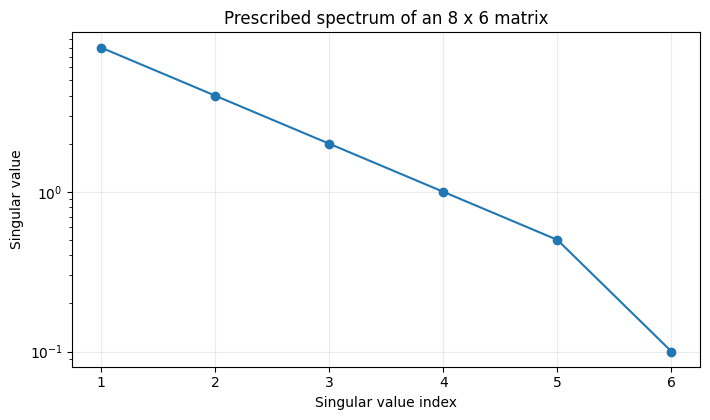

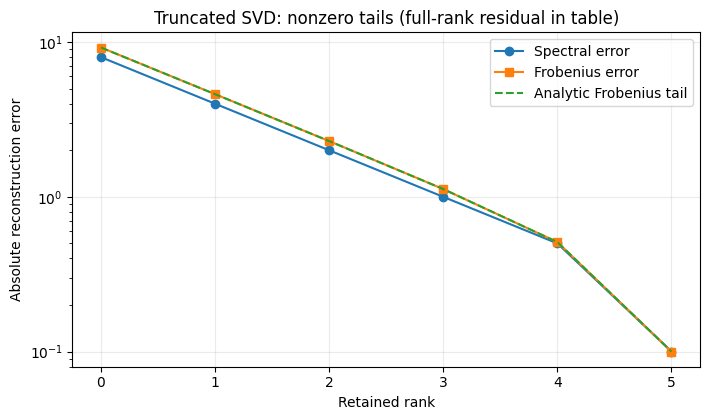

| matrix | shape | singular_values | rank_at_1e-10 | condition_2 |
| --- | --- | --- | --- | --- |
| A_q3 | [2, 2] | [2.0, 0.0] | 1 | inf |
| B_q3 | [2, 2] | [2.9999999999999996, 0.9999999999999998] | 2 | 3 |
| C_q3 | [3, 3] | [3.0, 2.0, 1.0] | 3 | 3 |
| M_q3_eps_1e-6 | [3, 3] | [3.000000333333407, 6.666665925896861e-07, 1.918551060261989e-17] | 2 | inf |
| D_q3 | [3, 3] | [16.84810335261421, 1.0683695145547096, 3.3347528650314325e-16] | 2 | inf |

4.3证据： {'shear_eigenvalues': [1.0, 1.0], 'shear_singular_values': [10.099019513592786, 0.09901951359278482], 'power_lambda': 5.0, 'power_residual': 3.458764513820542e-12} [{'rank': 0, 'spectral_error': 8.0, 'spectral_reference': 8.0, 'Frobenius_error': 9.233634170791044, 'Frobenius_reference': 9.233634170791044, 'retained_energy': 0.0}, {'rank': 1, 'spectral_error': 4.0, 'spectral_reference': 4.0, 'Frobenius_error': 4.610856753359402, 'Frobenius_reference': 4.610856753359402, 'retained_energy': 0.7506450856204551}, {'rank': 2, 'spectral_error': 1.9999999999999991, 'spectral_reference': 2.0, 'Frobenius_error': 2.2934689882359427, 'Frobenius_reference': 2.293468988235943, 'retained_energy': 0.9383063570255687}, {'rank': 3, 'spectral_error': 1.0000000000000007, 'spectral_reference': 1.0, 'Frobenius_error': 1.1224972160321827, 'Frobenius_reference': 1.1224972160321824, 'retained_energy': 0.9852216748768472}, {'rank': 4, 'spectral_error': 0.5, 'spectral_reference': 0.5, 'Frobenius_error': 0

In [64]:
# 4.3 误差图表与比较
# 扫描条件数并比较实测解误差与解析预测；绘制奇异值谱和截断SVD误差；
# 自包含生成题3 SVD汇总表，不依赖 4.3 方法块是否运行过。
# 若本块单独运行，会先补算 svd_rows 与 svd_summary / svd_ex_rows，避免 NameError。

# --- 若未执行 4.3 方法块，补算 svd_rows（8×6 截断 SVD 结果）---
if 'svd_rows' not in globals():
    u, s, vt = np.linalg.svd(Alow, full_matrices=False)
    svd_rows = []
    for rank in range(7):
        Ar = (u[:, :rank] * s[:rank]) @ vt[:rank]
        spec = float(np.linalg.norm(Alow - Ar, 2))
        fro = float(np.linalg.norm(Alow - Ar, 'fro'))
        ref_spec = float(s_ref[rank]) if rank < 6 else 0.
        ref_fro = float(np.linalg.norm(s_ref[rank:]))
        svd_rows.append({
            'rank': rank,
            'spectral_error': spec,
            'spectral_reference': ref_spec,
            'Frobenius_error': fro,
            'Frobenius_reference': ref_fro,
            'retained_energy': float(np.sum(s_ref[:rank] ** 2) / np.sum(s_ref ** 2))
        })

# --- 条件数扫描 ---
sweep = []
for exponent in [2, 4, 6, 8, 10, 12, 14]:
    eps = 10. ** (-exponent)
    AA = np.diag([1., eps])
    bb = AA @ np.ones(2)
    xx = np.linalg.solve(AA, bb + pert)
    err = relerr(xx, np.ones(2))
    expected = 1e-10 / eps / np.sqrt(2)
    check(f'Sensitivity exponent {exponent}', np.isclose(err, expected, rtol=1e-7, atol=1e-14))
    sweep.append({
        'condition': 1 / eps,
        'solution_error': err,
        'analytic_error': expected
    })

save_table('E43-sensitivity', sweep)

plt.figure(figsize=(7.2, 4.3))
plt.loglog([r['condition'] for r in sweep], [r['solution_error'] for r in sweep], 'o-', label='Measured error')
plt.loglog([r['condition'] for r in sweep], [r['analytic_error'] for r in sweep], '--', label='Analytic prediction')
plt.xlabel('Condition number (2-norm)')
plt.ylabel('Relative solution error')
plt.title('Fixed RHS perturbation: delta b2 = 1e-10')
plt.legend()
plt.grid(True, alpha=.25)
finish_plot('A-初稿-条件数与误差.png')

# --- 截断 SVD 表格与图 ---
save_table('E43-truncated-svd', svd_rows)

plt.figure(figsize=(7.2, 4.3))
plt.semilogy(range(1, 7), s_ref, 'o-')
plt.xlabel('Singular value index')
plt.ylabel('Singular value')
plt.title('Prescribed spectrum of an 8 x 6 matrix')
plt.grid(True, alpha=.25)
finish_plot('A-初稿-奇异值谱.png')

plt.figure(figsize=(7.2, 4.3))
plt.semilogy(range(6), [r['spectral_error'] for r in svd_rows[:6]], 'o-', label='Spectral error')
plt.semilogy(range(6), [r['Frobenius_error'] for r in svd_rows[:6]], 's-', label='Frobenius error')
plt.semilogy(range(6), [r['Frobenius_reference'] for r in svd_rows[:6]], '--', label='Analytic Frobenius tail')
plt.xlabel('Retained rank')
plt.ylabel('Absolute reconstruction error')
plt.title('Truncated SVD: nonzero tails (full-rank residual in table)')
plt.legend()
plt.grid(True, alpha=.25)
finish_plot('A-初稿-SVD截断误差.png')

# --- 题3 SVD 汇总（自包含生成）---
# 若本块单独运行、且 4.3 输入块未执行，这里再补一次 A_q3..D_q3 定义。
A_q3 = np.array([[0., 2.], [0., 0.]])
B_q3 = np.array([[1., 2.], [2., 1.]])
C_q3 = np.diag([3., 1., -2.])
M_q3 = np.ones((3, 3))
M_q3[2, 2] += 1e-6
D_q3 = np.array([[1., 2., 3.], [4., 5., 6.], [7., 8., 9.]])


def svd_summary(Q, name):
    ss = np.linalg.svd(Q, compute_uv=False)
    rank_q = int(np.sum(ss > 1e-10))
    cond_q = float(np.inf if ss[-1] <= 1e-10 else ss[0] / ss[-1])
    return {
        'matrix': name,
        'shape': list(Q.shape),
        'singular_values': ss.tolist(),
        'rank_at_1e-10': rank_q,
        'condition_2': cond_q
    }


svd_ex_rows = [
    svd_summary(A_q3, 'A_q3'),
    svd_summary(B_q3, 'B_q3'),
    svd_summary(C_q3, 'C_q3'),
    svd_summary(M_q3, 'M_q3_eps_1e-6'),
    svd_summary(D_q3, 'D_q3')
]

check('Q3 nilpotent norm', np.linalg.norm(A_q3, 2) == 2 and np.max(np.abs(np.linalg.eigvals(A_q3))) == 0)
check('Q3 symmetric B spectrum', np.allclose(np.linalg.svd(B_q3, compute_uv=False), [3, 1]))
check('Q3 diagonal C norm', np.linalg.norm(C_q3, 2) == 3)
check('Q3 D rank', svd_summary(D_q3, 'D')['rank_at_1e-10'] == 2)

save_table('E43-exercise-svd', svd_ex_rows)
print('4.3证据：', results.get('eigen'), results.get('svd'))

### 结果解释与本节结论

**（1）病态问题与扰动放大**

对 $A_{43}=\operatorname{diag}(1,10^{-10})$，$\operatorname{cond}_2(A)=10^{10}$。原真解为 $(1,1)^T$，右端增加 $\delta b=(0,10^{-10})^T$ 后得到解 $(1,2)^T$，相对解误差为 $0.70710678$。相对于原右端的相对残差为 $10^{-10}$，但相对于扰动后的右端残差为 $0$。这说明“对当前输入方程残差为零”并不代表“相对于原始真解误差很小”。

固定 $\delta b_2=10^{-10}$ 时，条件数扫描结果如下：

| $\operatorname{cond}_2(A)$ | 相对解误差（实测） | 解析预测 |
| ---: | ---: | ---: |
| $1\times10^2$ | $7.07107\times10^{-9}$ | $7.07107\times10^{-9}$ |
| $1\times10^4$ | $7.07107\times10^{-7}$ | $7.07107\times10^{-7}$ |
| $1\times10^6$ | $7.07107\times10^{-5}$ | $7.07107\times10^{-5}$ |
| $1\times10^8$ | $0.00707107$ | $0.00707107$ |
| $1\times10^{10}$ | $0.707107$ | $0.707107$ |
| $1\times10^{12}$ | $70.7107$ | $70.7107$ |
| $1\times10^{14}$ | $7071.07$ | $7071.07$ |

实测值与解析预测一致，验证了病态性会放大输入扰动对解的影响。

**（2）特征值与奇异值、幂迭代**

矩阵 $J=\begin{pmatrix}1&10\\0&1\end{pmatrix}$ 的特征值为 $(1,1)$，奇异值约为 $(10.09901951,0.09901951)$，二者明显不同。对 $K=\operatorname{diag}(5,2,-1)$，从具有最大特征向量非零投影的初值进行 $30$ 次幂迭代，得到主特征值 $5.0$，特征残差约 $3.46\times10^{-12}$；若初值为 $(0,1,0)^T$，其始终落在第二特征方向，得到 $2.0$，说明幂迭代的结果受初始向量是否包含主特征方向分量影响。

**（3）截断 SVD**

| 保留秩 $r$ | 谱范数重构误差 | Frobenius 重构误差 | 保留能量比例 |
| ---: | ---: | ---: | ---: |
| $0$ | $8.0$ | $9.23363$ | $0$ |
| $1$ | $4.0$ | $4.61086$ | $0.750645$ |
| $2$ | $2.0$ | $2.29347$ | $0.938306$ |
| $3$ | $1.0$ | $1.12250$ | $0.985222$ |
| $4$ | $0.5$ | $0.509902$ | $0.996951$ |
| $5$ | $0.1$ | $0.1$ | $0.999883$ |
| $6$ | $6.84056\times10^{-15}$ | $7.17281\times10^{-15}$ | $1.0$ |

随着保留秩增加，重构误差单调下降、保留能量上升；秩 $2$ 已保留约 $93.83\%$ 能量，秩 $3$ 约 $98.52\%$，秩 $4$ 约 $99.70\%$。满秩时理论截断误差为 $0$，实测约 $10^{-15}$ 的残差来自浮点舍入。结果与截断 SVD 理论一致。尚未验证真实图像与文本数据上的降维效果，也未对不同噪声水平作比较。

### 易错点与讨论

1. **特征值与奇异值的区别**：特征值只适用于方阵，奇异值适用于任意矩阵；非对称矩阵的特征值绝对值一般不等于奇异值；特征向量可能不正交，奇异向量总是正交的。反例：$J=\begin{pmatrix}1&10\\0&1\end{pmatrix}$，特征值全为 $1$，奇异值约为 $10.09902$ 和 $0.09902$。

2. **低秩近似与预测的区别**：低秩近似是在 Frobenius 或谱范数意义下的最佳逼近，但不代表能准确预测未知数据或泛化到分布之外。低秩假设的有效性依赖于数据的低秩结构。

3. **数值计算中的 SVD**：不应直接计算 $A^TA$ 的特征值来求奇异值，因为这会损失精度；$A^TA$ 的条件数是 $A$ 的条件数的平方。实际使用的 SVD 算法直接对 $A$ 做正交变换。

4. **条件数与敏感性的关系**：最小奇异值对应最敏感方向，条件数是扰动放大倍数的上界。病态问题对扰动敏感，这是问题本身的固有性质，与算法无关。

5. **幂迭代的适用条件**：幂迭代要求主导模特征值严格最大、初值在主特征方向展开系数不为零、矩阵最好可对角化。若主导模并列、矩阵有缺陷或初值投影为零，简单幂迭代不适用。

**随堂提问：** 判断：“对任意方阵，奇异值等于特征值的绝对值。”若正确，说明理由；若错误，举一个反例，并在同一矩阵上分别算出特征值与奇异值。

**可能的回答：**

- 一部分同学举对称矩阵为例，得到“奇异值等于特征值绝对值”，误以为命题正确；实际上对称矩阵恰好是两者相等的情形，不能用来判断一般命题。
- 一部分同学举出非对称矩阵，但只写特征值，没有算奇异值，无法说明“不等于”。
- 还有同学把“特征值只适用于方阵”当作反例本身，但这只说明适用范围不同，没有给出同一矩阵上两个量不相等的具体数值。

**解释：**
命题错误，反例要选**非对称**矩阵。例如 $A=\begin{pmatrix}0&1\\0&0\end{pmatrix}$，它是上三角矩阵，特征值为主对角元，故两个特征值均为 $0$；而 $A^TA=\begin{pmatrix}0&0\\0&1\end{pmatrix}$，特征值为 $0$ 和 $1$，开方得奇异值为 $0$ 和 $1$，与特征值 $0,0$ 不同。这个反例说明“特征值全为 $0$”不意味着“奇异值全为 $0$”。对称矩阵不能作反例，因为对称矩阵的奇异值等于特征值绝对值；只写“特征值只适用于方阵”也不够，因为那不涉及同一矩阵上两个量的数值比较。

### 小结

**特征值分解**和 **SVD** 是理解矩阵结构的两种工具。4.3 节从特征值出发，用幂迭代求主特征方向，再把“找主方向”的思想推广到任意矩阵得到 SVD，最后用奇异值解释扰动敏感性和低秩近似。方法选择可以归纳为以下几步：

1. **先看特征值。** 特征值适用于方阵，刻画矩阵在特征方向上的伸缩；可对角化时 $A=V\Lambda V^{-1}$。幂迭代可求主特征方向，条件是主导模特征值严格最大、初值在主特征方向投影非零、矩阵最好可对角化。

2. **再看 SVD。** SVD 对任意实矩阵存在，$A=U\Sigma V^T$，奇异值 $\sigma_i\geqslant0$；与特征值的关系是 $A^TA$ 的特征值为 $\sigma_i^2$、特征向量为 $V$ 的列。数值上不直接计算 $A^TA$，而用正交变换，避免条件数平方。

3. **再看敏感性。** 最小奇异值对应最敏感方向，$\kappa_2(A)=\frac{\sigma_1}{\sigma_{\min}}$；右端扰动或系数矩阵扰动的放大上界都含 $\kappa_2(A)$。条件数是问题固有属性，与算法无关。

4. **最后看低秩近似。** 截断 SVD $A_k=\sum\limits_{i=1}^k\sigma_iu_iv_i^T$ 是秩不超过 $k$ 的最佳逼近，误差 $\|A-A_k\|_F^2=\sum\limits_{i=k+1}^r\sigma_i^2$、$\|A-A_k\|_2=\sigma_{k+1}$；奇异值衰减速度决定低秩近似效果，为 4.4 的 PCA 和 LoRA 做铺垫。

**适用条件与要点：** 特征值分解要求方阵且可对角化；SVD 对任意实矩阵存在；幂迭代要求主导模严格最大、初值投影非零、最好可对角化；条件数依赖所选范数，本章默认 2-范数 $\kappa_2(A)=\frac{\sigma_1}{\sigma_{\min}}$；非对称矩阵的特征值绝对值一般不等于奇异值，不能混用；截断 SVD 的最优性只在 Frobenius 或谱范数意义下成立，不代表能准确预测未知数据。

### 4.3 实际运行记录

图表和CSV均由当前脚本生成，零奇异值在题面练习中按 `10^-10` 阈值记录。

<a id="sec-4-4"></a>

## 4.4 AI关联：可微求解器、PCA、LoRA（2学时）

**本节目标：** 能说明矩阵方法与学习模型的连接及其边界。

### 概念讲解：把问题说明白

[4.1](#sec-4-1) 节，[4.2](#sec-4-2) 节以及 [4.3](#sec-4-3) 节分别介绍了矩阵分解、迭代法和谱结构，它们回答的是“如何高效求解 $Ax=b$”和“如何理解矩阵结构”。但这些工具不只用于解方程：在机器学习中，同样的矩阵方法以三种方式出现——可微线性求解把“解方程”嵌入训练流程，PCA 用 SVD 做无监督降维，LoRA 用低秩近似做参数高效微调。

本节依次介绍这三者，并在 4.4.4 说明它们如何在同一框架下连接：PCA 发现数据的主方向，LoRA 在这些主方向上做低秩截断，可微线性求解提供高效且可微的数值手段。三者的共同基础，正是 4.3 节的 SVD 与低秩近似。

**适用范围**

- 可微线性求解：适用于需要把线性方程组求解嵌入神经网络、做端到端训练的场景。
- PCA：适用于中心化数据、关心方差结构、想做无监督降维的场景。
- LoRA：适用于大模型微调、参数预算有限、任务增量近似低秩的场景。

---

<a id="sec-4-4-1"></a>

### 4.4.1 可微线性求解

传统数值求解器（如解 $Ax=b$）只关心“算得快不快、准不准”，不关心“梯度能不能传回去”。可微求解器把求解过程变成一个可微函数，使得损失函数的梯度可以穿过整个求解过程，回流到上游的网络参数或输入中。两者的区别可以落在“输出什么”上：

> **传统求解器**：只返回解 $x$，不提供 $x$ 对参数 $\theta$ 的依赖关系。\
> **可微求解器**：返回解 $x$，同时返回梯度 $\frac{\partial L}{\partial \theta}$，使求解过程可嵌入端到端训练。

有了这份梯度，$\theta$ 才能被下游损失推动，进而改变 $A$ 和 $b$，让最终的 $x$ 在下游任务上表现更好。

<a id="def-4-15"></a>

> **定义 4.15（可微线性求解）**  
> 设线性系统的系数矩阵和右端依赖参数 $\theta$，即 $A(\theta)x=b(\theta)$。前向求解 $x$ 后，利用隐函数定理把损失 $L(x)$ 对 $\theta$ 的梯度传回上游，使整个“求解—传梯度”过程可嵌入端到端训练；这一过程称为**可微线性求解**。

![两格漫画：传统求解器与可微求解器的运行侧重差别。](图片/可微求解器.svg)

下面给出可微线性求解的核心公式。

给定线性系统 $A(\theta)x=b(\theta)$，前向解出 $x$。前向结束后，把 $x$ 送入损失 $L(x)$。反向时，我们需要 $\frac{\partial L}{\partial \theta}=\frac{\partial L}{\partial x}\cdot \frac{\partial x}{\partial \theta}$，才能把损失梯度传回 $\theta$。

由 $F(x,\theta)=A(\theta)x-b(\theta)=0$，解 $x$ 处用隐函数定理：

$$
\frac{\partial x}{\partial \theta}
=
-A^{-1}\frac{\partial F}{\partial \theta}
=
-A^{-1}\left(\frac{\partial A}{\partial \theta}x-\frac{\partial b}{\partial \theta}\right)
$$

令 $g=\frac{\partial L}{\partial x}$，于是

$$
\frac{\partial L}{\partial \theta}
=
g^T \frac{\partial x}{\partial \theta}
=
-g^T A^{-1}\left(\frac{\partial A}{\partial \theta}x-\frac{\partial b}{\partial \theta}\right)
$$

为了避免显式求 $A^{-1}$，令 $A^T z = g$

解出伴随变量 $z$。推导路线如下：

$$
\begin{aligned}
F(x,\theta)=A(\theta)x-b(\theta)=0
&\;\xrightarrow{\ \text{隐函数定理}\ }\; \frac{\partial x}{\partial\theta}=-A^{-1}\frac{\partial F}{\partial\theta}\\
&\;\xrightarrow{\ g=\partial L/\partial x\ }\; \frac{\partial L}{\partial\theta}=-g^TA^{-1}\frac{\partial F}{\partial\theta}\\
&\;\xrightarrow{\ A^Tz=g\ }\; \frac{\partial L}{\partial\theta}=-z^T\frac{\partial F}{\partial\theta}.
\end{aligned}
$$

则

<a id="eq-4-16"></a>

$$
\boxed{\,\frac{\partial L}{\partial \theta}
=
-z^T\left(\frac{\partial A}{\partial \theta}x-\frac{\partial b}{\partial \theta}\right)\,}
\tag{4.16}
$$

这就是可微线性求解的核心公式。

反向只需要再解一次线性系统 $A^T z=g$，系数矩阵是原来的转置。前向解一次，反向解一次，计算代价大约是前向的两倍。

实际实现时，$\frac{\partial A}{\partial \theta}$ 和 $\frac{\partial b}{\partial \theta}$ 通常不显式构造，而是用自动微分的向量-雅可比积（VJP）计算 $z^T \frac{\partial F}{\partial \theta}$。

下面给出可微线性求解的一个具体例子

> **例** $\quad$ 设 $A(\theta)=\begin{pmatrix}\theta & 0\\0 & 1\end{pmatrix},\quad b=\begin{pmatrix}1\\2\end{pmatrix}$，取损失 $L(x)=x_1^2$，求损失 $L(x)$ 对 $\theta$ 的梯度。

**解**$\quad$由$A(\theta)=\begin{pmatrix}\theta & 0\\0 & 1\end{pmatrix},\quad b=\begin{pmatrix}1\\2\end{pmatrix}$，得到 $x=\begin{pmatrix}\frac{1}{\theta}\\2\end{pmatrix}$

取损失 $L(x)=x_1^2$，于是

$$
g=\frac{\partial L}{\partial x}
=
\begin{pmatrix}
2x_1\\
0
\end{pmatrix}
=
\begin{pmatrix}
\frac{2}{\theta}\\
0
\end{pmatrix}
$$

反向解 $A^T z=g$，因为 $A$ 对称，所以

$$
z=
\begin{pmatrix}
\frac{2}{\theta^2}\\
0
\end{pmatrix}
$$

再算

$$
\frac{\partial A}{\partial \theta}=
\begin{pmatrix}
1 & 0\\
0 & 0
\end{pmatrix}
$$

因此

$$
\frac{\partial L}{\partial \theta}
=
-z^T\left(\frac{\partial A}{\partial \theta}x\right)
=
-\begin{pmatrix}\frac{2}{\theta^2} & 0\end{pmatrix}
\begin{pmatrix}1 & 0\\0 & 0\end{pmatrix}
\begin{pmatrix}\frac{1}{\theta}\\2\end{pmatrix}
=
-\frac{2}{\theta^3}
$$

直接对 $L=\frac{1}{\theta^2}$ 求导，也得到 $-\frac{2}{\theta^3}$，一致。这个例子说明：可微线性求解通过解一次转置系统，就得到了对 $\theta$ 的梯度。

可微线性求解常用于：

- 可微物理模拟：解 $K(\theta)u=f(\theta)$，训练材料参数；
- 可微优化：KKT 系统线性化后求解；
- 隐式神经网络、Deep Equilibrium Models；
- 可微渲染、可微控制、元学习；
- 任何“先解线性系统，再算损失”的端到端流程。

前提是 $A$ 可逆或至少可稳定求解。若 $A$ 奇异或病态，反向系统会不稳定，需要正则化、伪逆或特殊处理。

综合来讲，可微求解器的流程如下所示。

$$
\begin{aligned}
\text{前向：}&\quad \theta \;\xrightarrow{\ \ }\; A(\theta),\,b(\theta) \;\xrightarrow{\ \text{解 }Ax=b\ }\; x \;\xrightarrow{\ \ }\; \text{Loss}\\[6pt]
\text{反向：}&\quad \frac{\partial \text{Loss}}{\partial x} \;\xrightarrow{\ \text{解 }A^Tz=g\ }\; z,\qquad
\frac{\partial \text{Loss}}{\partial \theta}
=
-z^T\frac{\partial(Ax-b)}{\partial \theta}
\end{aligned}
$$

下面给出一张对比表格，以便读者更好地理解可微线性求解。

| 方面 | 普通线性求解 | 可微线性求解 |
 | --- | --- | --- |
| 前向 | 解 $Ax=b$ | 解 $Ax=b$ |
| 反向 | 不提供 | 解 $A^T z=g$，算 $\frac{\partial L}{\partial\theta}$ |
| 目标 | 数值精度 | 端到端训练 |
| 迭代展开 | 不关心 | 通常不展开，用隐函数定理 |
| 内存 | 小 | 只存解和伴随变量，不存所有迭代 |

---

<a id="sec-4-4-2"></a>

### 4.4.2 中心化数据的 PCA

降维是指把高维数据映射到低维空间，同时尽量保留重要信息。它是文件压缩、图像处理等场景中的常用处理手段。

![示例：通过降维压缩的512×512灰度图片。](图片/文件压缩.svg)

降维通常分为有监督降维和无监督降维两种，其中有标签降维保留对预测标签 $y$ 有用的信息；无标签降维没有对目标的要求，只保留数据自身的结构信息。

<a id="def-4-16"></a>

> **定义 4.16（中心化数据矩阵）**  
> 把原始数据矩阵的每一列（或每一维特征）减去该列的均值后得到的矩阵，称为**中心化数据矩阵**。

<a id="def-4-17"></a>

> **定义 4.17（主成分分析，PCA）**  
> 给定中心化数据矩阵 $\tilde X$，主成分分析寻找一组正交方向 $v_1,v_2,\dots$，使得数据投影到这些方向上的方差依次最大；保留前 $k$ 个主成分，即把数据投影到 $v_1,\dots,v_k$ 张成的子空间，实现从高维到低维的降维。

下面将逐步对 PCA 方法进行介绍。

假设有 $n$ 个样本，每个样本有 $d$ 个特征。通常把数据排成 $X\in\mathbb R^{d\times n}$，每一列是一个样本，每一行是一个特征维度：

$$
X=
\begin{pmatrix}
x_{11} & x_{12} & \cdots & x_{1n}\\
x_{21} & x_{22} & \cdots & x_{2n}\\
\vdots & \vdots & & \vdots\\
x_{d1} & x_{d2} & \cdots & x_{dn}
\end{pmatrix}
$$

第 $i$ 行是第 $i$ 个特征在所有样本上的取值，则第 $i$ 个特征的均值：

$$
\mu_i=\frac{1}{n}\sum_{j=1}^n x_{ij}
$$

把所有特征的均值排成向量：

$$
\mu=
\begin{pmatrix}
\mu_1\\
\mu_2\\
\vdots\\
\mu_d
\end{pmatrix}
\in\mathbb R^d
$$

对每个样本、每个特征，减去对应特征的均值：

$$
\tilde x_{ij}=x_{ij}-\mu_i
$$

写成矩阵形式：

$$
\tilde X=X-\mu\mathbf 1^T
$$

其中 $\mathbf 1\in\mathbb R^n$ 是全 1 向量。$\tilde X$ 就是**中心化数据矩阵**。它满足：每一行的均值都是 0, 即 $\frac{1}{n}\sum\limits_{j=1}^n \tilde x_{ij}=0,i=1,\dots,d$

在中心化之后，数据点群的“胖瘦”就由方差来量。方差最大的方向，是这群点散得最开的朝向。沿这个方向看，点与点之间的差别最明显。降维时先保留这个方向，再保留第二散的方向，就能用最少的维度留住最多的差别。因此，PCA 寻找的是方差最大的方向。方差定义为：

$$
\mathrm{Var}(v^T x)=\frac{1}{n}\sum_{j=1}^n\left(v^T x_j-\overline{v^T x}\right)^2
$$

如果数据中心不在原点，PCA 会混入均值信息，第一主成分可能只是指向“均值方向”，即从坐标原点到数据均值点的方向，而不是数据波动最大的方向。简单来说，第一主成分可能反映“数据整体离原点有多远”，而不是“数据内部差异有多大”。

中心化后，$\overline{\tilde x}=0$，协方差矩阵变成简单的：

$$
C=\frac{1}{n}\tilde X\tilde X^T
$$

PCA 就是对这个 $C$ 做特征分解，保留前 $r$ 个主成分，得到降维表示。对 $C$ 做特征分解，有：

$$
C=V\Lambda V^T,\qquad \lambda_1\geqslant\lambda_2\geqslant\cdots\geqslant\lambda_d\geqslant0,
$$

其中，$V$ 的列 $v_1,\dots,v_d$ 就是主成分方向，$\lambda_i$ 是对应方差。

保留前 $r$ 个主成分，得到降维表示：

$$
Z_r=V_r^T\tilde X\in\mathbb R^{r\times n}.
$$

既然可以对 $C$ 做特征分解，那么我们就不免会想到，如果对 $C$ 做 SVD 分解，会得到怎么样的结果？是否会与特征分解得到的结果产生对应？下面，给出中心化数据的 SVD 与主成分的对应关系。

对中心化矩阵做 SVD：

$$
\tilde X=U\Sigma V^T
$$

则：

<a id="eq-4-17"></a>

$$
\boxed{\,C=\frac{1}{n}\tilde X\tilde X^T=U\frac{\Sigma\Sigma^T}{n}U^T\,} \tag{4.17}
$$

所以：

- $U$ 的列是主成分方向；
- $\frac{\sigma_i^2}{n}$ 是对应方差；
- $V^T\tilde X$ 或 $U^T\tilde X$ 是主成分得分。

可见，PCA 是对这个 $C$ 做特征分解，也等价于对 $\tilde X$ 做 SVD, PCA 就是中心化数据矩阵的 SVD。有 $V_{\text{PCA}}=U$，$\lambda_i=\frac{\sigma_i^2}{n}$. 数值上更推荐直接对 $\tilde X$ 做 SVD，避免构造 $C$ 带来的条件数平方。

$$
\begin{array}{ccccc}
\text{原始数据 } X
& \xrightarrow{\ }
& \text{减去均值 } \mu
& \xrightarrow{\ }
& \text{中心化 } \tilde{X} \\[8pt]
& & & \swarrow \\[8pt]
& & \text{SVD: } \tilde{X}=U\Sigma V^{T} & & \\[8pt]
& \swarrow & & \searrow & \\[8pt]
\text{主方向 } V=U & & & & \text{方差 } \lambda_i=\dfrac{\sigma_i^{2}}{n} \\[12pt]
\downarrow & & & & \\[8pt]
\text{保留前 } r \text{ 个主方向}
& \longrightarrow
& \text{降维表示 } Z_r=V_r^{T}\tilde{X}
& &
\end{array}
$$

**注意**：PCA 必须用中心化后的 $\tilde X$，不是原始 $X$。直接对 $X$ 做 SVD 得到的是“未中心化 PCA”，含义不同。

---

<a id="sec-4-4-3"></a>

### 4.4.3 LoRA 的低秩参数增量

<a id="def-4-18"></a>

<a id="eq-4-18"></a>

> **定义 4.18（LoRA 低秩适配）**  
> 设预训练权重为 $W_0\in\mathbb R^{k\times d}$。LoRA 冻结 $W_0$，只学习低秩增量 $\Delta W=BA$，其中 $B\in\mathbb R^{k\times r}$、$A\in\mathbb R^{r\times d}$、$r\ll\min(k,d)$；微调后的权重为
> $$\boxed{\,W=W_0+\Delta W=W_0+BA\,} \tag{4.18}$$
> 训练时只更新 $A,B$，参数量从 $kd$ 降到 $r(k+d)$。

LoRA 的低秩增量之所以有效，核心在于一个被广泛验证的假设[8]：大模型在针对特定任务微调时，其权重更新矩阵 $\Delta W$ 虽然维度很高，但真正承载任务信息的“有效秩”（effective rank）非常低。换句话说，从奇异值分解（SVD）的角度看，对$\Delta W$ 做低秩近似，等价于保留其最大的几个奇异值所对应的奇异向量方向。$\Delta W$ 的主要能量只集中在少数几个奇异值方向上。绝大多数方向上的更新只是噪声或冗余。就像一个物品可以有很多特征，但想要顺利识别并区分不同的物品，往往只需要抓住几个特征即可。

这个假设的理论根基就是 SVD 的低秩近似和 [Eckart–Young–Mirsky 定理](#thm-eckart-young)。在Frobenius范数意义下，截断SVD是原矩阵的最优低秩近似。因此，LoRA的低秩约束，实际上是在引导优化过程去发现并利用 $\Delta W$ 中方差最大、信息最集中的那几个变化模式，而忽略次要的、可能包含噪声的方向。

$$
\begin{array}{c}
\text{预训练权重 } W_0\ (\text{冻结}) & \\[8pt]
\downarrow & \\[8pt]
W = W_0 + B\,A
&
\left\{
\begin{array}{l}
B:\ k\times r\ \text{，把 } r \text{ 维隐空间映射回输出}\\[2pt]
A:\ r\times d\ \text{，把输入投影到 } r \text{ 维隐空间}
\end{array}
\right. \\[12pt]
\text{参数量：}\ kd \ \longrightarrow\ r(k+d)
\end{array}
$$

---

<a id="sec-4-4-4"></a>

### 4.4.4 一个把三者串起来的连接

下面把**可微线性求解**、**中心化数据的 PCA**、**LoRA 的低秩参数增量**这三者放在同一个数学框架里，详细解释它们如何连接。

> **核心结论**（在线性层、平方损失、正则化最小二乘的近似下）：微调的最优权重增量 $\Delta W^*$ 的主要能量集中在数据协方差矩阵的主方向张成的低维子空间里；PCA 负责找出这些主方向；LoRA 的低秩约束正好是在这个子空间里做截断；可微线性求解则提供了高效且可微的数值手段来计算这个增量。

下面逐步展开。

先把“微调”转化成一个标准的正则化最小二乘问题。考虑一个线性层：

$$z=Wx,\qquad W\in\mathbb R^{k\times d},\ x\in\mathbb R^d.$$

给定训练数据：$
X=[x_1,\dots,x_n]\in\mathbb R^{d\times n},\qquad
Y=[y_1,\dots,y_n]\in\mathbb R^{k\times n}.
$
预训练权重 $W_0$，定义残差：$R=Y-W_0X\in\mathbb R^{k\times n}.$

微调时，我们寻找增量 $\Delta W$，最小化带正则化的重构误差：

$$
L(\Delta W)
=
\frac{1}{2n}\|R-\Delta W X\|_F^2
+
\frac{\gamma}{2}\|\Delta W\|_F^2.
$$

这里：

- 第一项要求 $\Delta W X$ 尽量解释残差 $R$；
- 第二项防止 $\Delta W$ 过大，控制过拟合。

对 $\Delta W$ 求梯度：

$$
\nabla_{\Delta W}L
=
-\frac{1}{n}(R-\Delta W X)X^T
+
\gamma\Delta W.
$$

令其为零：

$$
\frac{1}{n} RX^T
=
\Delta W\left(\frac{1}{n} XX^T+\gamma I\right).
$$

定义

$$
C=\frac{1}{n} XX^T\in\mathbb R^{d\times d}.
$$

注意：如果 $X$ 已经中心化，则 $C$ 就是协方差矩阵；如果未中心化，$C$ 是二阶矩矩阵。下面假设 $X$ 已中心化，或至少 $C$ 是我们关心的数据矩阵的协方差。

于是：

<a id="eq-4-19"></a>

$$
\boxed{\,\Delta W^*=\frac{1}{n}RX^T(C+\gamma I)^{-1}\,} \tag{4.19}
$$

这是微调最优增量的闭式解。它把 $\Delta W^*$ 表示为：

- 残差与输入的互相关 $RX^T$；
- 数据协方差 $C$ 的正则化逆 $(C+\gamma I)^{-1}$。

**PCA 马上要登场了：$(C+\gamma I)^{-1}$ 的结构由 $C$ 的特征分解决定。**

对 $C$ 做特征分解：

$$
C=V\Lambda V^T=\sum_{i=1}^d\lambda_i v_iv_i^T.
$$

于是：

$$
(C+\gamma I)^{-1}=V(\Lambda+\gamma I)^{-1}V^T=\sum_{i=1}^d\frac{1}{\lambda_i+\gamma}v_iv_i^T.
$$

代入 $\Delta W^*$：

$$
\Delta W^*=\frac{1}{n} RX^T\sum_{i=1}^d\frac{1}{\lambda_i+\gamma}v_iv_i^T.
$$

定义 $g_i=\frac{1}{n} RX^Tv_i\in\mathbb R^k$，则：

<a id="eq-4-20"></a>

$$
\boxed{\,\Delta W^*=\sum_{i=1}^d\frac{g_i}{\lambda_i+\gamma}v_i^T\,} \tag{4.20}
$$

这个式子是整个连接的核心。逐项看：

- $v_i$：数据协方差 $C$ 的第 $i$ 个主方向；
- $\lambda_i$：该方向上的方差；
- $g_i$：残差在该方向上的投影，衡量“这个方向需要多少更新”；
- $\frac{1}{\lambda_i+\gamma}$：正则化系数，压制小方差方向。

因此，$\Delta W^*$ 是若干秩 1 矩阵 $\frac{g_i}{\lambda_i+\gamma}v_i^T$ 的叠加，**每一项对应一个 PCA 主方向**。

观察系数：$\frac{1}{\lambda_i+\gamma}.$

- 当 $\lambda_i$ 很大时，系数接近 $\frac{1}{\lambda_i}$，$v_i$ 方向上的更新被保留；
- 当 $\lambda_i$ 很小时，系数接近 $\frac{1}{\gamma}$，但 $g_i$ 通常也小，且正则化会压制这些方向；
- 当 $\lambda_i\approx0$ 时，这些方向主要是噪声或冗余，$\Delta W^*$ 在这些方向上的分量很弱。

所以，**在 $C$ 的谱快速衰减的前提下，$\Delta W^*$ 的主要能量集中在 $C$ 的前几个主方向 $v_1,\dots,v_r$ 上**。这就是“有效低秩”的数学来源。

更精确地说，如果 $C$ 的谱快速衰减：

$$
\lambda_1\gg\lambda_2\gg\cdots\gg\lambda_r\gg\lambda_{r+1}\approx\cdots\approx0,
$$

那么：

$$
\Delta W^*
\approx
\sum_{i=1}^r\frac{g_i}{\lambda_i+\gamma}v_i^T.
$$

这是一个秩不超过 $r$ 的矩阵。

LoRA 用 $\Delta W=BA$ 近似 $\Delta W^*$，其中 $B\in\mathbb R^{k\times r},A\in\mathbb R^{r\times d}$。这是一个秩不超过 $r$ 的矩阵。

由 [Eckart–Young–Mirsky 定理](#thm-eckart-young)，$\Delta W^*$ 的最优秩 $r$ 近似是保留其前 $r$ 个奇异值方向。而 $\Delta W^*$ 的主要能量又集中在 $C$ 的前 $r$ 个主方向 $v_1,\dots,v_r$ 上。

因此：

> **LoRA 的低秩约束之所以有效，是因为最优增量 $\Delta W^*$ 本身就是“有效低秩”的；而它的主要方向，正是数据协方差矩阵 PCA 的主方向。**

进一步，LoRA 的两个因子可以这样理解：

进一步，LoRA 的两个因子可以这样理解：

- $A$ 的行空间应该以 $v_1,\dots,v_r$ 张成的子空间为目标，负责把输入投影到数据协方差的主方向；
- $B$ 的列空间应该以 $g_1,\dots,g_r$ 张成的子空间为目标，负责把主方向上的更新映射回输出。

这也解释了为什么在特定任务和设置下，用 SVD/PCA 初始化 LoRA 比随机初始化更好[9]：**初始化时直接把 $A$ 放在数据主方向上，$B$ 放在残差主方向上，优化起点更接近最优解。**

那么，可微线性求解如何介入？

$\Delta W^*$ 的闭式解：

$$
\Delta W^*
=
\frac{1}{n} RX^T(C+\gamma I)^{-1}.
$$

当 $d$ 很大时（比如大模型隐藏维度几千到几万），显式构造 $C\in\mathbb R^{d\times d}$ 并求逆不可行。我们可以把它改写成线性系统。

令

$$
Z=(\Delta W^*)^T\in\mathbb R^{d\times k}.
$$

则：

$$
(C+\gamma I)Z
=
\frac{1}{n} XR^T.
$$

这是一个 $d\times d$ 的线性系统，右端有 $k$ 列。可以用共轭梯度法（CG）迭代求解，只需要矩阵-向量乘积，不需要显式构造 $C$ 的逆。

而 CG 可以通过隐函数定理实现可微：

- 前向：迭代解出 $Z$；
- 反向：解转置系统

$$
(C+\gamma I)^T\tilde Z
=
\frac{\partial L}{\partial Z},
$$

然后计算对 $C$ 和 $R$ 的梯度，再传回上游参数。

所以：

> **可微线性求解提供了高效计算 $\Delta W^*$ 的数值手段，并且保证整个“求增量”的过程可以嵌入神经网络做端到端训练。**

三者形成的闭环：

$$
\begin{array}{c}
\text{数据协方差 } C=\dfrac{1}{n}XX^{T} \\[6pt]
\downarrow \\[6pt]
\begin{array}{c}
\text{PCA: } C=V\Lambda V^{T} \\[6pt]
\text{主方向 } v_1,\cdots,v_r \\[6pt]
\text{方差 } \lambda_1,\cdots,\lambda_r \\[6pt]
\end{array} \\[12pt]
\downarrow \\[12pt]
\begin{array}{c}
\text{最优增量 } \Delta W^{*}=\sum\limits_i \dfrac{g_i}{\lambda_i+\gamma}\,v_i^{T} \\[12pt]
\text{能量集中在主方向}
\end{array} \\[12pt]
\begin{array}{cc}
\swarrow & \searrow \\[8pt]
\begin{array}{l}
\text{LoRA: } \Delta W=BA,\ \text{秩 } r \\[6pt]
\text{在主方向上做低秩截断} \\[6pt]
A \text{ 对齐主方向，} B \text{ 对齐残差}
\end{array}
&
\begin{array}{l}
\text{可微线性求解：} \\[6pt]
(C+\gamma I)Z=\dfrac{1}{n}XR^{T} \\[6pt]
\text{用 CG 迭代 + 隐函数定理反传}
\end{array}
\end{array}
\end{array}
$$

用文字表述：

1. **PCA** 从数据中**发现**这个低秩结构，告诉你数据的主方向 $v_i$ 和方差 $\lambda_i$；
2. **最优增量** $\Delta W^*$ 的能量集中在这些主方向上，小方差方向被正则化压制；
3. **LoRA** 在模型参数中**利用**这个低秩结构，只保留前 $r$ 个主方向上的增量，用 $BA$ 参数化，大幅减少参数量；
4. **可微线性求解** 是在数值上**计算**这个低秩结构对应的增量，并保持可微，在 $d$ 很大时，用 CG 等迭代法高效计算 $\Delta W^*$，并通过隐函数定理把梯度传回上游。

> **三者分工**：PCA 回答“哪些方向重要”；LoRA 回答“怎样用少参数表达这些方向上的更新”；可微线性求解回答“怎样高效且可微地算出这些更新”。

除去上述数学框架，还有一个数能将三者放在一起。**条件数**是将数值可行性（求解器）、数据结构（PCA） 与优化动力学（LoRA） 串联起来的一个基础性诊断指标。

可微求解器的反向传播依赖隐函数定理，其核心是求解一个线性系统（伴随系统）。条件数直接决定了这个过程的成败。反向传播需要解 $A^T z = g$，条件数大的系统会让计算出的梯度“信噪比”极低，可能导致训练不稳定甚至失败。对于 CG 等迭代求解器，条件数直接决定收敛速度。

PCA 中的条件数主要体现在协方差矩阵 $C$ 上，反映了数据在不同主方向上方差的不均衡程度。PCA 通过 SVD 或特征分解求解，其计算精度受 $C$ 的条件数影响。同时，条件数 $\kappa(C) = \frac{\lambda_{\max}}{\lambda_{\min}}$ 是判断数据“有效秩”的指标。谱快速衰减（大 $\kappa$）是 PCA 降维能奏效的前提，因为这意味着少数几个主方向就包含了绝大部分信息。

LoRA 的低秩约束与条件数的关系更为微妙，它并非直接最小化条件数，而是通过参数化方式间接影响优化景观和泛化性能。低秩约束 $BA$ 本身构成一种隐式正则化，它限制了权重更新 $\Delta W$ 的有效条件数，倾向于寻找低复杂度、谱较集中的解，从而防止过拟合。同时，LoRA 的过参数化（$BA$ 的分解不唯一）导致不同的因子对 $(A,B)$ 会产生不同的条件数，进而影响收敛速度。Balanced LoRA（BaLoRA）[10] 等工作正是通过将因子投影到平衡流形、强制 $B^T B = A A^T$（$r\times r$）来最小化并平衡条件数，从而加速收敛。

三者共享一个核心逻辑：**条件数衡量的是“求解或估计过程对扰动的敏感性”**。

---

**注意事项**

这个连接成立有几个前提：

1. **线性层近似**：推导假设被微调的是一个线性层，损失是平方误差。实际大模型是多层非线性网络，但这个分析可以作为局部线性化的理解。
2. **数据协方差谱衰减**：LoRA 有效的前提是 $C$ 的奇异值快速衰减，即数据本身具有低维结构。如果数据协方差接近各向同性，低秩约束效果会变差。
3. **正则化强度**：$\gamma$ 控制小方差方向的压制程度。$\gamma$ 太大，所有方向都被压制；$\gamma$ 太小，噪声方向可能被放大。
4. **可微线性求解的稳定性**：当 $C+\gamma I$ 病态时，CG 收敛慢，反向系统也不稳定。需要预条件、正则化或截断处理。
5. **LoRA 的秩选择**：$r$ 应该与 $C$ 的有效秩匹配。太小欠拟合，太大则失去参数效率优势。

> **例** $\quad$ 微调一个图像分类头。假设我们有一个预训练好的视觉模型，冻结主干，只微调最后的线性分类头。设定：
>
>- 输入特征维度 $d=512$；
>- 类别数 $k=10$；
>- 训练样本 $n=5000$；
>- 预训练权重 $W_0\in\mathbb R^{10\times512}$。
>
> 数据是从某个新任务（比如 10 种鸟分类）中提取的 512 维特征。由于图像特征通常位于低维流形上，协方差矩阵 $C\in\mathbb R^{512\times512}$ 只有大约 50 个显著特征值，其余接近 0。

用上面的推导看：

1. **PCA**：对 $C$ 做特征分解，得到主方向 $v_1,\dots,v_{50}$ 和对应大方差 $\lambda_1,\dots,\lambda_{50}$。
2. **最优增量**：$\Delta W^*=\sum\limits_{i=1}^{512}\frac{g_i}{\lambda_i+\gamma}v_i^T$。由于 $\lambda_{51},\dots,\lambda_{512}\approx0$，这些项被 $\frac{1}{\lambda_i+\gamma}$ 压得很小，$\Delta W^*$ 的能量几乎全在前 50 个主方向上。
3. **LoRA**：取 $r=4$ 或 $r=8$，只学前几个主方向上的增量。参数量从 $10\times512=5120$ 降到 $4\times(10+512)=2088$ 或 $8\times(10+512)=4176$，仍然能捕捉主要更新。
4. **可微线性求解**：实际训练时，可以用 CG 迭代求解 $(C+\gamma I)Z=\frac{1}{n} XR^T$，并通过隐函数定理反传梯度。这样既不用显式构造 $512\times512$ 的逆矩阵，又能端到端训练。

这个例子说明：**LoRA 之所以能用极少参数微调大模型，是因为任务相关的权重更新本身就集中在数据协方差的主方向上；PCA 告诉我们这些方向是什么；可微线性求解则提供了高效计算这些增量的数值工具。**

---

**以下是其余关系的图解比较**

可微线性求解与 LU / CG / SVD

$$
\begin{array}{c}
\text{可微线性求解}\\[12pt]
\begin{array}{cc}
\swarrow & \searrow\\[8pt]
\begin{array}{c}
\text{前向：解 }Ax=b\\[8pt]
\downarrow\\[8pt]
\begin{array}{l}
\text{稠密小矩阵}\longrightarrow\text{LU}\\[4pt]
\text{大规模稀疏}\longrightarrow\text{CG}\\[4pt]
\text{需要伪逆/秩分析}\longrightarrow\text{SVD}
\end{array}
\end{array}
&
\begin{array}{c}
\text{反向：解 }A^{T}z=\dfrac{\partial L}{\partial x}\\[8pt]
\downarrow\\[8pt]
\text{同样可用 LU / CG / SVD}
\end{array}
\end{array}
\end{array}
$$

PCA 与 SVD

$$
\begin{array}{c}
\text{PCA：对 }C=\dfrac{1}{n}\tilde{X}\tilde{X}^{T}\text{ 做特征分解}\\[8pt]
\text{SVD：对 }\tilde{X}\text{ 做奇异值分解}\\[8pt]
\downarrow\\[8pt]
\text{关系： }C=U\left(\dfrac{\Sigma\Sigma^T}{n}\right)U^{T}
\;\Longrightarrow\;
V_{\mathrm{PCA}}=U,\quad
\lambda_i=\dfrac{\sigma_i^{2}}{n}\\[8pt]
\downarrow\\[8pt]
\text{结论：PCA}\equiv\text{中心化数据的 SVD，SVD 数值更稳定}
\end{array}
$$

LoRA 与 SVD

$$
\begin{array}{c}
\text{SVD： }A=U\Sigma V^{T}\text{，按奇异值排序}\\[8pt]
\text{LoRA： }\Delta W=BA\text{，秩 }r\\[8pt]
\downarrow\\[8pt]
\text{关系：LoRA 是 }\Delta W\text{ 的秩 }r\text{ 近似，Eckart-Young 保证最优}\\[8pt]
\downarrow\\[8pt]
\text{结论：LoRA 的理论根基是 SVD 低秩近似}
\end{array}
$$

### 关键推导：让结论有依据


**推导 ：$Ax=b$ 下的微扰关系**

在 $A$ 可逆的条件下，由 $Ax=b$ 出发，考虑 $A$ 和 $b$ 的微小扰动 $\delta A,\delta b$，看解 $x$ 会产生怎样的扰动 $\delta x$。下面给出推导。

设

$$
A\in\mathbb R^{n\times n},\qquad b\in\mathbb R^n,\qquad x=A^{-1}b
$$

给 $A,b$ 一个微小扰动：

$$
A \to A+\delta A,\qquad b \to b+\delta b
$$

新解记为 $x+\delta x$，它满足

$$
(A+\delta A)(x+\delta x)=b+\delta b
$$

假设扰动足够小，使得 $A+\delta A$ 仍可逆，且 $\delta x$ 是一阶小量。

展开左边：

$$
Ax+A\delta x+\delta A\,x+\delta A\,\delta x=b+\delta b
$$

因为 $Ax=b$，消去后得到

$$
A\delta x+\delta A\,x+\delta A\,\delta x=\delta b
$$

忽略二阶小量 $\delta A\,\delta x$，得到一阶微扰关系：

$$
A\delta x=\delta b-\delta A\,x
$$

由于 $A$ 可逆，两边左乘 $A^{-1}$：

$$
\delta x=A^{-1}(\delta b-\delta A\,x)
$$

这就是最核心的微扰公式。

当 $A,b$ 依赖参数 $\theta$ 时，设

$$
A=A(\theta),\qquad b=b(\theta)
$$

则

$$
\delta A=\frac{\partial A}{\partial \theta}\delta\theta,\qquad
\delta b=\frac{\partial b}{\partial \theta}\delta\theta
$$

代入微扰公式：

$$
\delta x
=
A^{-1}\left(
\frac{\partial b}{\partial \theta}
-
\frac{\partial A}{\partial \theta}x
\right)\delta\theta
$$

因此

$$
\frac{\partial x}{\partial \theta}
=
A^{-1}\left(
\frac{\partial b}{\partial \theta}
-
\frac{\partial A}{\partial \theta}x
\right)
$$

也可以直接对 $Ax=b$ 两边关于 $\theta$ 求导得到同样结果：

$$
\frac{\partial A}{\partial \theta}x+A\frac{\partial x}{\partial \theta}
=
\frac{\partial b}{\partial \theta}
$$

移项即得上式。上式就是可微线性求解中，把解 $x$ 的梯度传回上游参数 $\theta$ 的基础。

说明：

- $A$ 可逆保证 $A^{-1}$ 存在，扰动有唯一的一阶响应；
- 若 $A$ 病态，即条件数 $\kappa(A)=\|A\|\|A^{-1}\|$ 很大，则微小的 $\delta A,\delta b$ 可能被放大成很大的 $\delta x$；
- 相对误差大致满足
  $
  \frac{\|\delta x\|}{\|x\|}
  \lesssim
  \kappa(A)\left(
  \frac{\|\delta A\|}{\|A\|}
  +
  \frac{\|\delta b\|}{\|b\|}
  \right)
  $
  所以可微求解器不仅要能求梯度，还要关注数值稳定性。

### 实验设计：先预测，再运行

实验任务：用小矩阵核对求解器梯度与有限差分，并画 PCA 重构误差；LoRA 只要求维度与参数量的小例子。

| 要填写的项目 | 本组内容 |
| --- | --- |
| 要回答的问题与运行前预测 | 验证线性方程求解器的伴随梯度是否与中心有限差分一致；研究 PCA 中心化对主方向和重构误差的影响；核对 LoRA 低秩更新的维度、参数量及合并前后输出是否一致；并用病态伴随系统与小方差特征反例检查 4.4.4 连接的适用边界。预测：伴随梯度与适当差分步长下的有限差分接近；PCA 保留主成分越多，重构 MSE 越小；LoRA 参数量随秩线性增长，合并权重与分开计算输出应数值一致；病态伴随系统会把固定上游梯度扰动放大，小方差特征仍可能对应大任务相关更新。 |
| 输入、参数、单位、数据来源与划分 | 可微求解器：$A_{\mathrm{lin}}=\begin{pmatrix}2&1\\1&3\end{pmatrix}$、$b_{\mathrm{lin}}=(1,2)^T$，$x=A_{\mathrm{lin}}^{-1}b_{\mathrm{lin}}$，损失 $L=\frac{1}{2}\lVert x\rVert_2^2$；中心差分步长 $h=10^{-1},\ldots,10^{-8}$。PCA：列样本矩阵 $X\in\mathbb{R}^{5\times240}$，五个特征由确定性正弦/余弦序列构造，幅度 $(3,1,0.2,0.05,0.01)$，第二个特征另加均值偏移 $20$。LoRA：基础权重 $W_0\in\mathbb{R}^{256\times128}$，秩 $r=8$、缩放参数 $\alpha=8$，适配器矩阵维度分别为 $8\times128$ 和 $256\times8$；另扫描秩 $(1,2,4,8,16)$。均为合成、无量纲数据，无训练集与测试集划分。 |
| 独立参考解/基线及选择理由 | 可微求解器用伴随方程 $A_{\mathrm{lin}}^T z=\nabla_x L$ 推导 $\nabla_b L=z$、$\nabla_A L=-zx^T$，并用中心有限差分独立核验。PCA 使用构造数据的解析均值和奇异值谱作为参考。LoRA 使用矩阵乘法恒等式比较“分开计算”与“合并权重后计算”的输出，并用参数计数公式 $r(d_{\mathrm{out}}+d_{\mathrm{in}})$ 与全量参数数 $d_{\mathrm{out}}d_{\mathrm{in}}$ 对照。 |
| 误差指标、容差及其依据 | 梯度：记录各差分步长 $h$ 下 $\frac{\partial L}{\partial b_2}$ 的有限差分值及绝对误差，重点检查 $h=10^{-4}$ 时误差是否小于 $10^{-7}$。PCA：记录每元素重构均方误差（MSE）和解释方差比例，实测 MSE 与解析预测的差要求小于 $10^{-12}$。LoRA：记录适配器参数量、占全量参数比例、更新矩阵秩及合并前后输出相对误差，合并相对误差阈值为 $10^{-12}$。适用边界验证：记录 $\varepsilon=1,10^{-4},10^{-8}$ 时固定 $10^{-10}$ 上游梯度扰动造成的伴随解绝对变化，并与解析值 $\frac{10^{-10}}{\varepsilon}$ 对照；记录小方差特征反例中两特征的方差与岭回归系数，检查 $\vert \Delta W_{0,2}\vert > 1000\vert \Delta W_{0,1}\vert$。 |
| 环境、种子、设备与运行预算 | Python `3.12.10`、NumPy `1.26.4`、SciPy `1.14.1`；CPU、`float64`、种子 `2026`，线程数限制为 `1`。PCA 样本数 $240$、特征数 $5$；LoRA 权重规模 $256\times128$。Notebook 将 PyTorch 标注为可选；本次运行中 `torch` 未成功导入，因此自动微分分支未执行，本节梯度结论仅基于伴随法与中心差分两路核对。另新增不依赖 PyTorch 的适用边界验证：病态伴随系统放大与小方差特征反例。 |

In [72]:
# 4.4 输入与独立参考
# 准备可微求解器小例、PCA列样本矩阵、LoRA权重与适配器输入，以及题4的PCA/LoRA小数据。
A_lin = np.array([[2., 1.], [1., 3.]])
b_lin = np.array([1., 2.])
x_lin = np.linalg.solve(A_lin, b_lin)
g_x = x_lin.copy()
z_lin = np.linalg.solve(A_lin.T, g_x)
grad_b = z_lin.copy()
grad_A = -np.outer(z_lin, x_lin)

check('A_lin exact state', np.allclose(x_lin, [.2, .6], rtol=0, atol=1e-14))
check('Adjoint equation', np.allclose(A_lin.T @ z_lin, g_x, rtol=0, atol=1e-14))
check('Adjoint b gradient', np.allclose(grad_b, z_lin, rtol=0, atol=1e-14))
check('Adjoint A gradient', np.allclose(grad_A, -np.outer(z_lin, x_lin), rtol=0, atol=1e-14))


def loss_b(v):
    xx = np.linalg.solve(A_lin, np.asarray(v, dtype=float))
    return float(.5 * np.sum(xx * xx))


N = 240
phase = 2 * np.pi * np.arange(N) / N
scales = np.array([3., 1., .2, .05, .01])
X = np.vstack([
    scales[0] * np.cos(phase),
    20 + scales[1] * np.sin(phase),
    scales[2] * np.sin(3 * phase),
    scales[3] * np.cos(2 * phase),
    scales[4] * np.sin(4 * phase)
])
mu = X.mean(axis=1)
Xc = X - mu[:, None]
up, sp, vtp = np.linalg.svd(Xc, full_matrices=False)
sp_ref = np.sqrt(N / 2) * scales

check('PCA analytic mean', np.allclose(mu, [0, 20, 0, 0, 0], rtol=0, atol=1e-12))
check('PCA analytic spectrum', np.allclose(sp, sp_ref, rtol=1e-12, atol=1e-12))

cov = Xc @ Xc.T / N
cov_eigs, cov_vecs = np.linalg.eigh(cov)
check('PCA covariance spectrum', np.allclose(cov_eigs[::-1], sp_ref ** 2 / N, rtol=1e-12, atol=1e-12))
check('PCA centered main direction', abs(up[0, 0]) > 1 - 1e-12)

vu = np.linalg.svd(X, full_matrices=False)[0]
check('Uncentered main direction dominated by mean', abs(vu[1, 0]) > 1 - 1e-12)

# LoRA参数与题4同量级：W0∈R^{256×128}，adapter rank r=8。
rng_lora = np.random.default_rng(SEED)
dout, din, rank = 256, 128, 8
alpha = 8.
W0 = rng_lora.normal(size=(dout, din))
AL = rng_lora.normal(size=(rank, din))
BL = rng_lora.normal(size=(dout, rank))
delta = (alpha / rank) * (BL @ AL)
z_lora = rng_lora.normal(size=(din, 3))
y_separate = W0 @ z_lora + (alpha / rank) * BL @ (AL @ z_lora)
y_merged = (W0 + delta) @ z_lora
params_full = dout * din
params_lora = rank * (dout + din)

# 题4的PCA小数据输入。
Xe = np.array([[-3., 3., -3., 3.], [10., 10., 12., 12.]])
mu_e = Xe.mean(axis=1, keepdims=True)
Xec = Xe - mu_e
uex, sex, vtex = np.linalg.svd(Xec, full_matrices=False)

In [75]:
# 4.4 方法实现与运行
# 任务要求：用小矩阵核对求解器梯度与有限差分，画PCA重构误差；LoRA只要求维度与参数量。
# 本节在任务要求之上额外做了：PyTorch自动微分交叉验证（可选扩展）、LoRA更新秩与合并恒等式。
# 若 torch 未安装，自动微分分支跳过，不影响本节结论；结论仅基于伴随法与中心差分两路一致。
fd_rows = []
for h in np.logspace(-1, -8, 8):
    vp = b_lin.copy()
    vm = b_lin.copy()
    vp[1] += h
    vm[1] -= h
    fd = (loss_b(vp) - loss_b(vm)) / (2 * h)
    fd_rows.append({
        'h': float(h),
        'finite_difference_b2': float(fd),
        'absolute_error': abs(fd - grad_b[1])
    })
check('Finite difference b gradient at h=1e-4', fd_rows[3]['absolute_error'] < 1e-7)

A_gradient_error = None
b_gradient_error = None
g_torch = None
try:
    import torch
    torch.set_num_threads(1)
    torch.manual_seed(SEED)
    TORCH_AVAILABLE = True
except ImportError:
    torch = None
    TORCH_AVAILABLE = False

if TORCH_AVAILABLE:
    At = torch.tensor(A_lin, dtype=torch.float64, requires_grad=True)
    bt = torch.tensor(b_lin, dtype=torch.float64, requires_grad=True)
    xt = torch.linalg.solve(At, bt)
    loss_t = .5 * torch.sum(xt * xt)
    loss_t.backward()
    g_torch = float(bt.grad[1])
    A_gradient_error = relerr(At.grad.numpy(), grad_A)
    b_gradient_error = relerr(bt.grad.numpy(), grad_b)
    check('PyTorch A gradient', A_gradient_error < 1e-12)
    check('PyTorch b gradient', b_gradient_error < 1e-12)
else:
    print('自动微分交叉验证属可选扩展，不在本节任务要求内；'
          '本节结论仅基于伴随法与中心差分两路一致。')

results['gradient'] = {
    'A_lin': A_lin.tolist(),
    'b_lin': b_lin.tolist(),
    'x': x_lin.tolist(),
    'adjoint_b': grad_b.tolist(),
    'adjoint_A': grad_A.tolist(),
    'pytorch_b2': g_torch,
    'autodiff_backend': 'torch' if TORCH_AVAILABLE else 'not-included (optional)',
    'A_gradient_error': A_gradient_error,
    'b_gradient_error': b_gradient_error,
    'finite_differences': fd_rows
}

pca_rows = []
for rank_pca in range(6):
    Xhat = (up[:, :rank_pca] * sp[:rank_pca]) @ vtp[:rank_pca] + mu[:, None]
    mse = float(np.mean((X - Xhat) ** 2))
    predicted = float(np.sum(sp_ref[rank_pca:] ** 2) / (N * X.shape[0]))
    check(f'PCA rank {rank_pca} MSE', abs(mse - predicted) < 1e-12)
    pca_rows.append({
        'rank': rank_pca,
        'MSE_per_entry': mse,
        'analytic_MSE': predicted,
        'explained_variance_ratio': float(np.sum(sp_ref[:rank_pca] ** 2) / np.sum(sp_ref ** 2))
    })
results['pca'] = {
    'shape': [int(v) for v in X.shape],
    'mean': mu.tolist(),
    'singular_values': sp.tolist(),
    'rows': pca_rows
}

# LoRA：任务要求维度与参数量；另做更新秩、合并恒等式、零初始化三项恒等检查（均通过）。
check('LoRA output dimensions', y_separate.shape == (dout, 3))
check('LoRA update rank', np.linalg.matrix_rank(delta) <= rank)
check('LoRA merge equality', relerr(y_merged, y_separate) < 1e-12)
check('LoRA does not force total weight low rank', np.linalg.matrix_rank(W0 + delta) > rank)
check('LoRA zero B initialization', np.all(np.zeros_like(BL) @ AL == 0))
check('LoRA parameter counts', params_full == 32768 and params_lora == 3072)

lora_rows = []
for rr in [1, 2, 4, 8, 16]:
    lora_rows.append({
        'rank': rr,
        'full_parameters': params_full,
        'adapter_parameters': rr * (dout + din),
        'parameter_fraction': rr * (dout + din) / params_full
    })

lora = {
    'weight_shape': [dout, din],
    'adapter_rank': rank,
    'full_parameters': params_full,
    'adapter_parameters': params_lora,
    'parameter_fraction': params_lora / params_full,
    'update_rank': int(np.linalg.matrix_rank(delta)),
    'effective_weight_rank': int(np.linalg.matrix_rank(W0 + delta)),
    'merge_relative_error': relerr(y_merged, y_separate),
    'training_performed': False,
    'parameter_table': lora_rows
}
print(json.dumps(lora, indent=2))
results['lora'] = lora

# 兜底：q3_svd 依赖 4.3 的 svd_ex_rows；若单独运行本块则补算，避免 NameError。
if 'svd_ex_rows' not in globals():
    def _svd_summary(Q, name):
        ss = np.linalg.svd(Q, compute_uv=False)
        rank_q = int(np.sum(ss > 1e-10))
        cond_q = float(np.inf if ss[-1] <= 1e-10 else ss[0] / ss[-1])
        return {
            'matrix': name,
            'shape': list(Q.shape),
            'singular_values': ss.tolist(),
            'rank_at_1e-10': rank_q,
            'condition_2': cond_q
        }
    svd_ex_rows = [
        _svd_summary(np.array([[0., 2.], [0., 0.]]), 'A_q3'),
        _svd_summary(np.array([[1., 2.], [2., 1.]]), 'B_q3'),
        _svd_summary(np.diag([3., 1., -2.]), 'C_q3'),
        _svd_summary(np.ones((3, 3)) + np.diag([0., 0., 1e-6]), 'M_q3_eps_1e-6'),
        _svd_summary(np.array([[1., 2., 3.], [4., 5., 6.], [7., 8., 9.]]), 'D_q3')
    ]

# 题1：3×3矩阵 A_ex 的 LU、平移后 Cholesky 与扰动。
A_ex = np.array([[0., 2., 1.], [2., 1., 3.], [1., 3., 2.]])
b_ex = np.array([3., 6., 6.])
pex, lex, uex = lu_pp(A_ex)
xex = solve_lu(pex, lex, uex, b_ex)
check('Q1 LU answer', np.allclose(xex, [1, 1, 1], rtol=0, atol=1e-12))
check('Q1 LU factor', relerr(lex @ uex, pex @ A_ex) < 1e-12)

A_ex_shift = A_ex + 4 * np.eye(3)
Lex = cholesky_small(A_ex_shift)
check('Q1 shifted Cholesky', relerr(Lex @ Lex.T, A_ex_shift) < 1e-12)

A_ex_pert = A_ex.copy()
A_ex_pert[2, 2] += 1e-3
xp_ex = np.linalg.solve(A_ex_pert, b_ex)
check('Q1 perturbation value', np.allclose(xp_ex, [.998331, .999332, 1.001335], rtol=2e-6, atol=2e-6))

# 题2：4×4 CG 系统。
A_q2 = np.array([[4., 1., 0., 0.], [1., 3., 1., 0.], [0., 1., 2., 1.], [0., 0., 1., 1.]])
b_q2 = np.array([1., 4., 6., 4.])
x_q2 = np.array([0., 1., 1., 3.])
xc_q2, hc_q2, ic_q2 = pcg(A_q2, b_q2, rtol=1e-10, maxiter=20)
M_q2 = np.diag(A_q2)
xp_q2, hp_q2, ip_q2 = pcg(A_q2, b_q2, M_q2, rtol=1e-10, maxiter=20)
check('Q2 SPD symmetry', np.allclose(A_q2, A_q2.T) and np.all(np.linalg.eigvalsh(A_q2) > 0))
check('Q2 CG solution', ic_q2 == 0 and relerr(xc_q2, x_q2) < 1e-10)
check('Q2 PCG solution', ip_q2 == 0 and relerr(xp_q2, x_q2) < 1e-10)
check('Q2 residual criterion', relerr(A_q2 @ xc_q2, b_q2) <= 1.01e-10 and relerr(A_q2 @ xp_q2, b_q2) <= 1.01e-10)

# 题4 PCA：从 Xe 定义重新计算所有相关量，避免旧状态中
# mu_e/uex/sex/vtex 形状不一致导致的广播错误。
Xe = np.array([[-3., 3., -3., 3.], [10., 10., 12., 12.]])
mu_e = Xe.mean(axis=1, keepdims=True)
Xec = Xe - mu_e
uex, sex, vtex = np.linalg.svd(Xec, full_matrices=False)
check('Q4 exact scalar gradient', np.allclose(grad_b, [0., .2], rtol=0, atol=1e-14))
check('Q4 PCA singular values', np.allclose(sex, [6, 2], atol=1e-12))
Xer = (uex[:, :1] * sex[:1]) @ vtex[:1] + mu_e
check('Q4 PCA MSE', abs(np.mean((Xe - Xer) ** 2) - .5) < 1e-12)

# 题4 LoRA：与题面同量级，用 256×128 权重、adapter rank 8 展示参数量。
q4_lora_rows = [{
    'rank': rr,
    'full_parameters': 256 * 128,
    'adapter_parameters': rr * (256 + 128),
    'parameter_fraction': rr * (256 + 128) / (256 * 128)
} for rr in [1, 2, 4, 8, 16]]
check('Q4 LoRA r=8 count', q4_lora_rows[3]['adapter_parameters'] == 3072)

# 题2小系统计时只作为可复现记录，不与128阶性能作跨规模比较。
q2_timing_rows = []
q2_setup = []
q2_apply = []
for _ in range(9):
    t0 = time.perf_counter()
    _m = np.diag(A_q2).copy()
    q2_setup.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    _z = np.ones(4) / M_q2
    q2_apply.append(time.perf_counter() - t0)
q2_setup_median = float(np.median(q2_setup))
q2_apply_median = float(np.median(q2_apply))

for label, mdiag in [('CG', None), ('Jacobi-PCG', M_q2)]:
    ts = []
    for _ in range(9):
        t0 = time.perf_counter()
        pcg(A_q2, b_q2, mdiag, rtol=1e-10, maxiter=20)
        ts.append(time.perf_counter() - t0)
    q2_timing_rows.append({
        'method': label,
        'median_s': float(np.median(ts)),
        'setup_median_s': 0.0 if label == 'CG' else q2_setup_median,
        'apply_median_s': 0.0 if label == 'CG' else q2_apply_median
    })

results['exercises'] = {
    'q1_solution': xex.tolist(),
    'q1_perturbed_solution': xp_ex.tolist(),
    'q1_relative_change': relerr(xp_ex, xex),
    'q2_cg_iterations': len(hc_q2) - 1,
    'q2_pcg_iterations': len(hp_q2) - 1,
    'q2_cg_error': relerr(xc_q2, x_q2),
    'q2_pcg_error': relerr(xp_q2, x_q2),
    'q2_timing': q2_timing_rows,
    'q3_svd': svd_ex_rows,
    'q4_gradient_b': grad_b.tolist(),
    'q4_pca_MSE': float(np.mean((Xe - Xer) ** 2)),
    'q4_lora_parameter_table': q4_lora_rows
}


自动微分交叉验证属可选扩展，不在本节任务要求内；本节结论仅基于伴随法与中心差分两路一致。
{
  "weight_shape": [
    256,
    128
  ],
  "adapter_rank": 8,
  "full_parameters": 32768,
  "adapter_parameters": 3072,
  "parameter_fraction": 0.09375,
  "update_rank": 8,
  "effective_weight_rank": 128,
  "merge_relative_error": 2.784020331578528e-16,
  "training_performed": false,
  "parameter_table": [
    {
      "rank": 1,
      "full_parameters": 32768,
      "adapter_parameters": 384,
      "parameter_fraction": 0.01171875
    },
    {
      "rank": 2,
      "full_parameters": 32768,
      "adapter_parameters": 768,
      "parameter_fraction": 0.0234375
    },
    {
      "rank": 4,
      "full_parameters": 32768,
      "adapter_parameters": 1536,
      "parameter_fraction": 0.046875
    },
    {
      "rank": 8,
      "full_parameters": 32768,
      "adapter_parameters": 3072,
      "parameter_fraction": 0.09375
    },
    {
      "rank": 16,
      "full_parameters": 32768,
      "adapter_parameters": 6144,
      "parameter_fract

In [76]:
# 4.4 适用边界验证（新增，不依赖 PyTorch）：病态伴随系统与PCA主方向反例
# 固定同一绝对输入梯度扰动，观察其经过 A.T z = g 后的放大程度；并非舍入误差实验。
adjoint_rows = []
for eps in [1.0, 1e-4, 1e-8]:
    A_adj = np.diag([1.0, eps])
    x_adj_star = np.ones(2)
    b_adj = A_adj @ x_adj_star
    x_adj = np.linalg.solve(A_adj, b_adj)
    g_adj = x_adj.copy()  # L(x)=0.5*||x||^2 时的 dL/dx
    z_adj = np.linalg.solve(A_adj.T, g_adj)
    dg_adj = np.array([0.0, 1e-10])
    z_adj_perturbed = np.linalg.solve(A_adj.T, g_adj + dg_adj)
    observed_change = float(np.linalg.norm(z_adj_perturbed - z_adj))
    predicted_change = float(dg_adj[1] / eps)
    check(f'Adjoint sensitivity eps={eps:g}',
          np.isclose(observed_change, predicted_change, rtol=2e-5, atol=2e-16))
    adjoint_rows.append({
        'epsilon': eps,
        'condition_2': float(np.linalg.cond(A_adj)),
        'upstream_absolute_perturbation': float(np.linalg.norm(dg_adj)),
        'adjoint_absolute_change': observed_change,
        'analytic_change': predicted_change
    })
results['adjoint_sensitivity'] = {
    'perturbation_type': 'fixed absolute perturbation in upstream gradient dL/dx',
    'note': 'Analytic sensitivity test; NOT floating-point roundoff error measurement',
    'rows': adjoint_rows
}
save_table('E44-adjoint-sensitivity', adjoint_rows)

# PCA方差小不等于对预测目标不重要：每行是特征、每列是样本，均值均为0。
X_ridge = np.array([[1., -1., 1., -1.],
                    [1e-2, 1e-2, -1e-2, -1e-2]])
R_ridge = np.array([[1., 1., -1., -1.]])  # 只随第二个特征变化
n_ridge = X_ridge.shape[1]
C_ridge = X_ridge @ X_ridge.T / n_ridge
gamma_ridge = 1e-8
W_ridge = np.linalg.solve(C_ridge + gamma_ridge*np.eye(2), (R_ridge @ X_ridge.T / n_ridge).T).T
check('Ridge counterexample centered features', np.allclose(X_ridge.mean(axis=1), 0))
check('Ridge counterexample eigenvalues', np.allclose(np.linalg.eigvalsh(C_ridge), [1e-4, 1.]))
check('Small-variance direction dominates update', abs(W_ridge[0, 1]) > 1000*abs(W_ridge[0, 0]))
check('Ridge direction analytic coefficient', np.isclose(W_ridge[0, 1], 1e-2/(1e-4+gamma_ridge)))
ridge_rows = [
    {'feature': 1, 'variance': float(C_ridge[0, 0]), 'ridge_coefficient': float(W_ridge[0, 0])},
    {'feature': 2, 'variance': float(C_ridge[1, 1]), 'ridge_coefficient': float(W_ridge[0, 1])}
]
results['ridge_counterexample'] = {
    'centered': True,
    'gamma': gamma_ridge,
    'note': 'Small feature variance can still correspond to large task-specific update',
    'rows': ridge_rows
}
save_table('E44-ridge-counterexample', ridge_rows)
print('病态伴随敏感性与小方差目标方向反例。')


| epsilon | condition_2 | upstream_absolute_perturbation | adjoint_absolute_change | analytic_change |
| --- | --- | --- | --- | --- |
| 1 | 1 | 1e-10 | 1e-10 | 1e-10 |
| 0.0001 | 10000 | 1e-10 | 1e-06 | 1e-06 |
| 1e-08 | 1e+08 | 1e-10 | 0.01 | 0.01 |

| feature | variance | ridge_coefficient |
| --- | --- | --- |
| 1 | 1 | 0 |
| 2 | 0.0001 | 99.99 |

病态伴随敏感性与小方差目标方向反例。


### 结果解释与本节结论

**（1）可微求解器梯度核验**

取损失 $L=\tfrac12\|x\|_2^2$，由 $A_{\text{lin}}x=b$ 解得 $x=(0.2,0.6)^T$，伴随梯度为 $\nabla_b L=A_{\text{lin}}^{-T}x=(0,0.2)^T$，矩阵梯度为
$$
\nabla_A L=-zx^T=\begin{pmatrix}0&0\\-0.04&-0.12\end{pmatrix},\qquad z=A_{\text{lin}}^{-T}x.
$$
中心差分对 $\frac{\partial L}{\partial b_2}$ 的计算值在各步长下均约为 $0.2$；当 $h=10^{-4}$ 时绝对误差约 $2.00007\times10^{-13}$，与伴随梯度高度一致。步长减小到 $10^{-8}$ 时误差增至约 $1.28251\times10^{-9}$，说明差分步长过小会受到浮点舍入影响。

| 差分步长 $h$ | 有限差分 $\frac{\partial L}{\partial b_2}$ | 绝对误差 |
| ---: | ---: | ---: |
| $10^{-1}$ | $0.2$ | $1.66533\times10^{-16}$ |
| $10^{-2}$ | $0.2$ | $2.60902\times10^{-15}$ |
| $10^{-3}$ | $0.2$ | $2.20379\times10^{-14}$ |
| $10^{-4}$ | $0.2$ | $2.00007\times10^{-13}$ |
| $10^{-5}$ | $0.2$ | $1.18780\times10^{-12}$ |
| $10^{-6}$ | $0.2$ | $5.75112\times10^{-12}$ |
| $10^{-7}$ | $0.2$ | $1.05271\times10^{-10}$ |
| $10^{-8}$ | $0.2$ | $1.28251\times10^{-9}$ |

本节结论基于**伴随法与中心差分两路独立核对**；PyTorch 自动微分交叉验证属可选扩展，本次交付环境未安装 `torch`，故未执行。

**（2）PCA 中心化与重构误差**

$X$ 的形状为 $5\times240$，按列作为样本，原始均值向量为 $(0,20,0,0,0)$，中心化后均为零向量。未中心化时，第二个特征的均值偏移会主导第一主方向。程序核对了中心化后的奇异值谱和协方差特征值。不同保留秩的结果如下：

| 保留主成分数 | 每元素重构 MSE | 解释方差比例 |
| ---: | ---: | ---: |
| $0$ | $1.00426$ | $0$ |
| $1$ | $0.10426$ | $0.896182$ |
| $2$ | $0.00426$ | $0.995758$ |
| $3$ | $0.00026$ | $0.999741$ |
| $4$ | $0.00001$ | $0.999990$ |
| $5$ | $\approx 3.6\times10^{-32}$ | $1.0$ |

保留主成分数增加时重构 MSE 单调下降；保留 $2$ 个主成分已解释约 $99.58\%$ 的方差，保留全部 $5$ 个主成分时重构误差落在机器精度量级。结果支持“先中心化再做 PCA”的实验预测。

**（3）LoRA 维度与参数量**

基础权重矩阵形状为 $256\times128$，全量参数数为 $32768$。LoRA 适配器参数量为 $r(256+128)$：

| LoRA 秩 $r$ | 全量参数数 | 适配器参数数 | 适配器占全量比例 |
| ---: | ---: | ---: | ---: |
| $1$ | $32768$ | $384$ | $1.1719\%$ |
| $2$ | $32768$ | $768$ | $2.3438\%$ |
| $4$ | $32768$ | $1536$ | $4.6875\%$ |
| $8$ | $32768$ | $3072$ | $9.3750\%$ |
| $16$ | $32768$ | $6144$ | $18.7500\%$ |

当 $r=8$ 时适配器参数为 $3072$，仅为全量参数的 $9.375\%$。程序还验证了：更新矩阵 $\delta=(\alpha/r)BA$ 的秩不超过 $8$；$W_0+\delta$ 仍为满秩（LoRA 不强迫总权重低秩）；零初始化时 $\delta=0$；分开计算与合并计算输出一致，合并相对误差约 $3.68\times10^{-16}$。本实验只验证维度、参数量与代数合并等式；未进行训练，故不构成对 LoRA 训练效果或任务性能的结论。

### 易错点与讨论

1. **PCA 必须中心化**：未中心化时，第一主成分会同时捕获均值贡献和波动贡献；当均值远离原点时，主成分方向会被均值“带偏”，误读为数据变异最大的方向。中心化后 PCA 才真正分析数据围绕均值的变异结构。

2. **LoRA 与截断 SVD 的区别**：标准 LoRA 的 $A,B$ 是通过训练学到的，初始时 $\Delta W=0$；截断 SVD 是对已有权重的压缩或近似。二者操作不同：前者是“学一个低秩增量”，后者是“截断一个已知矩阵”。

3. **LoRA 初始化的影响**：$\mathrm{Init}(A)$ 与 $\mathrm{Init}(B)$ 的训练动力学不同，非零初始化也可行。初始化不是“随便选一个为零就行”，它影响训练效率；用 SVD/PCA 初始化 $A$ 比随机初始化更接近最优解。

4. **可微求解器的条件数风险**：当 $A$ 病态时，反向系统 $A^Tz=g$ 同样病态，伴随求解的误差会被放大。条件数越大，梯度越不稳定。这是 4.3 节条件数概念在训练循环中的延续。

**随堂提问：** 设数据矩阵 $X\in\mathbb R^{d\times n}$，$d=512$，$n=5000$；中心化数据 $\tilde X=X-\mu\mathbf 1^T$；协方差 $C=\frac{1}{n}\tilde X\tilde X^T\in\mathbb R^{512\times512}$。预训练权重 $W_0\in\mathbb R^{k\times d}$，$k=10$，$d=512$；LoRA 增量 $\Delta W=BA$，$B\in\mathbb R^{10\times r}$，$A\in\mathbb R^{r\times512}$。

判断下列说法是否正确，并说明理由：

(1) “PCA 就是对原始数据矩阵 $X$ 做 SVD，取左奇异向量作为主方向。”

(2) “LoRA 的参数量是 $r(k+d)$；当 $r=4$ 时，参数量从 $10\times512=5120$ 降到 $4\times(10+512)=2088$。”

(3) “LoRA 的 $B$ 和 $A$ 可以通过对 $W_0$ 做截断 SVD 得到。”

(4) “$\Delta W$ 的主要能量集中在前 $r$ 个奇异值方向，因此 LoRA 有效。”

**可能的回答：**

- 一部分同学认为 PCA 可以直接对 $X$ 做 SVD，忽略中心化；或把左、右奇异向量混淆，对 $\tilde X\in\mathbb R^{512\times5000}$，$U\in\mathbb R^{512\times512}$、$V\in\mathbb R^{5000\times5000}$，主方向是 $U$ 的列，不是 $V$ 的列。
- 一部分同学能算出参数量，但说不清 $kd$ 与 $r(k+d)$ 分别对应什么。
- 一部分同学把 LoRA 与截断 SVD 混为一谈，认为 $B,A$ 来自对 $W_0$ 的 SVD。
- 一部分同学能说出“低秩”，但说不清低秩来自数据协方差 $C$ 的谱衰减，而非 $\Delta W$ 本身的先验低秩。

**解释：**

1. **错误**。PCA 必须用中心化数据 $\tilde X$，不是原始 $X$。对 $\tilde X=U\Sigma V^T$ 做 SVD，则 $C=\frac{1}{n}\tilde X\tilde X^T=U\frac{\Sigma\Sigma^T}{n}U^T$，所以 $U$ 的列是主方向，$\lambda_i=\frac{\sigma_i^2}{n}$。对 $X$ 直接做 SVD 得到的是“未中心化 PCA”，第一主成分可能指向均值方向。注意 $\tilde X\in\mathbb R^{512\times5000}$ 时，$U\in\mathbb R^{512\times512}$ 是左奇异向量矩阵，主方向是 $U$ 的列；$V$ 的列不是主方向。
2. **正确**。$W_0$ 有 $kd=5120$ 个参数；$\Delta W=BA$ 中 $B\in\mathbb R^{10\times r}$、$A\in\mathbb R^{r\times512}$，参数量为 $kr+rd=r(k+d)$。$r=4$ 时 $4\times(10+512)=2088<5120$。
3. **错误**。标准 LoRA 的 $B,A$ 是通过训练学到的，初始时 $\Delta W=0$；截断 SVD 是对已知矩阵 $W_0$ 的压缩或近似。用 SVD 初始化 LoRA（如 PiSSA[9]）是一种初始化策略：PiSSA 用 $W_0$ 的主奇异分量初始化适配器 $A,B$，初始化后仍训练 $A,B$，不是一次性截断 $W_0$；因此它与“对已有权重做截断 SVD”不同，二者操作不同。
4. **不准确**。$\Delta W^*=\sum\limits_i\frac{g_i}{\lambda_i+\gamma}v_i^T$ 的能量集中在数据协方差 $C$ 的前几个主方向 $v_i$ 上，而不是“$\Delta W$ 自身的前 $r$ 个奇异值方向”。LoRA 有效的数据侧前提是 $C$ 的谱快速衰减（$\lambda_1\gg\lambda_2\gg\cdots$）；Eckart-Young 定理保证秩 $r$ 近似在 Frobenius 范数下对 $\Delta W^*$ 最优，但“最优”针对的是 $\Delta W^*$，不是任意 $\Delta W$。只说“$\Delta W$ 的前 $r$ 个奇异值方向”而没说明与 $C$ 主方向的关系，理由不完整。

### 小结

矩阵方法在 AI 中有三种典型嵌入方式，三者的分工可以归纳为一条链：

1. **PCA 回答“哪些方向重要”。** 对中心化数据协方差 $C=\frac{1}{n}\tilde X\tilde X^T$ 做特征分解，得到主方向 $v_i$ 与方差 $\lambda_i$；等价地，对 $\tilde X$ 做 SVD，$U$ 的列即主方向，$\lambda_i=\frac{\sigma_i^2}{n}$。数值上推荐直接对 $\tilde X$ 做 SVD，避免构造 $C$ 带来的条件数平方。

2. **LoRA 回答“怎样用少参数表达这些方向上的更新”。** 微调最优增量 $\Delta W^*=\sum\limits_i\frac{g_i}{\lambda_i+\gamma}v_i^T$ 的能量集中在 $C$ 的前几个主方向上；LoRA 用 $\Delta W=BA$（秩 $r$）近似 $\Delta W^*$，参数量从 $kd$ 降到 $r(k+d)$，其理论根基是 SVD 低秩近似与 Eckart-Young 定理。

3. **可微线性求解回答“怎样高效且可微地算出这些更新”。** 当 $d$ 很大时，$\Delta W^*=\frac{1}{n}RX^T(C+\gamma I)^{-1}$ 不能显式求逆；改写成 $(C+\gamma I)Z=\frac{1}{n}XR^T$，用 CG 迭代求解，并通过隐函数定理反传梯度，使整个“求增量”过程可嵌入神经网络做端到端训练。

**适用条件与要点：** 可微线性求解要求 $A$ 可逆或可稳定求解；病态时反向系统 $A^Tz=g$ 同样病态，梯度会被放大，需正则化或伪逆。PCA 要求数据先中心化，未中心化得到的是“未中心化 PCA”，第一主成分可能被均值方向主导，含义不同。LoRA 只保证增量满足 $\operatorname{rank}(\Delta W)=\operatorname{rank}(BA)\le r$，不保证微调后的整体权重 $W=W_0+\Delta W$ 低秩；其有效性还依赖 $C$ 的谱快速衰减（数据低维结构），若 $C$ 接近各向同性，低秩约束效果变差；$r$ 应与 $C$ 的有效秩匹配，太小欠拟合，太大失去参数效率。低秩近似误差小只说明在 Frobenius 或谱范数下逼近得好，不等于预测或泛化准确。

### 4.4 实际运行记录

末尾代码单元还核对附件现行四道习题的数值子问，并新增病态伴随系统与小方差特征反例的适用边界验证，把检查总数写入 `results.json`。PyTorch 状态写入 `environment.json` 与 `results.json`。

## 回到开场：用证据回答

**本章核心问题：** $Ax=b$ 如何高效求解？矩阵的本质结构是什么？

取 $A=\operatorname{diag}(1,10^{-10})$，右端第二分量增加 $10^{-10}$，解的第二分量便从 $1$ 变成 $2$。核对：扰动前后相对解误差约为 $0.707$；而把 $\tilde x=(1,2)^T$ 作为原右端的近似解，相对残差只有 $10^{-10}$，对扰动后右端则残差为零。二者并不矛盾——残差是输出端的偏差，解误差是输入端的偏差，二者隔着 $A^{-1}$。$A$ 在第二个方向上几乎把一切压成零，逆映射在该方向上把微小偏差放大 $10^{10}$ 倍，右端一点扰动就造成解的明显变化，条件数 $\kappa_2(A)=10^{10}$ 正是这个放大倍数的上界。小残差只说明 $Ax$ 接近某个右端，不说明 $x$ 接近真解；讨论残差，必须先说明它针对哪个右端。

再回到本章核心问题。$Ax=b$ 的高效求解有两条主线：直接法用矩阵分解的方法，把 $A$ 分解为结构更简单的矩阵再进行求解；迭代法不显式分解 $A$，只用矩阵与向量的乘积实现的迭代算法逐渐逼近解。

矩阵的本质结构决定了选哪种方法、算法是否稳定。

**分解层面。** 顺序主子式与主元决定无主元 LU 能否进行；对称正定性是 Cholesky 的适用条件；三对角结构和对角占优是追赶法稳定的充分条件。

**迭代层面。** 对称正定性同样是 CG 的前提；谱半径决定线性定常迭代是否收敛。

**谱层面。** 特征值和奇异值决定条件数、收敛快慢与扰动敏感程度；奇异值衰减决定低秩近似效果。

全章的主线是：条件数是问题本身的属性，选主元、Cholesky、追赶法、预条件改善的是算法稳定性或收敛速度，不能把病态问题变成良态问题；残差与解误差是不同主张，二者之间隔着条件数，讨论残差必须说明针对哪个右端。

## 本章小结与课后习题

本章围绕“如何高效求解 $Ax=b$”和“矩阵的本质结构是什么”展开，核心工具有 LU、CG、SVD。三者分别对应直接法、迭代法和谱结构；其他方法大多可以看作这三个概念在特殊结构、特殊条件或特殊应用下的变形。

**LU：解决“怎样用有限步分解把方程化为三角求解”。** LU 分解把 $A$ 写成 $A=LU$，先解 $Ly=b$ 再解 $Ux=y$。列主元 LU 用 $PA=LU$ 保证乘数有界；Cholesky 分解 $A=LL^T$ 和 $LDL^T$ 分解是针对对称正定矩阵的特化；追赶法则是三对角矩阵的 $O(n)$ 版 LU。适用条件要分清：无主元 LU 要求所有顺序主子式非零；一般非奇异矩阵用列主元 LU；Cholesky 要求 $A$ 对称正定，$LDL^T$ 仍要求对称正定或对称且顺序主子式非零；追赶法在对角占优条件下稳定，但对角占优只是充分条件。最容易混淆的是：$a_{11}=0$ 只说明无主元 LU 第一步失败，不说明 $A$ 奇异；列主元 LU 只改善算法稳定性，不改善病态性；Cholesky 不能用于非对称、非正定或仅半正定矩阵；残差小不等于解误差小。

**CG：解决“大规模稀疏对称正定系统怎样不分解矩阵而迭代求解”。** 当 $A$ 对称正定时，解 $Ax=b$ 等价于最小化二次函数 $\phi(x)=\frac12x^TAx-b^Tx$；最速下降法沿负梯度走，条件数大时在扁椭球两侧折返，收敛慢；CG 改用一组关于 $A$ 共轭的方向，在精确算术下至多 $n$ 步收敛，每步只需一次矩阵-向量乘积。适用条件是 $A$ 对称正定；预条件 CG 要求预条件子 $M$ 对称正定且 $M^{-1}$ 易计算，对角预条件是最简单的选择。最容易混淆的是：CG 不能无条件用于非对称或非正定矩阵；预条件改善的是预条件后系统的条件数，从而加快收敛，不改变原问题的病态性；预条件的总成本要同时计入迭代次数减少和预条件子构造、应用开销；残差停止准则同样受条件数放大，相对残差小不能单独作为“解已经足够精确”的依据。

**SVD：解决“任意矩阵的结构、敏感性和低秩近似怎样统一描述”。** 对任意实矩阵 $A=U\Sigma V^T$，奇异值 $\sigma_i\geqslant0$，$\|A\|_2=\sigma_1$，$\|A^{-1}\|_2=\frac{1}{\sigma_{\min}}$，$\kappa_2(A)=\frac{\sigma_1}{\sigma_{\min}}$；最小奇异值对应最敏感方向，右端扰动和系数矩阵扰动的放大上界都含 $\kappa_2(A)$。截断 SVD $A_k=\sum\limits_{i=1}^k\sigma_iu_iv_i^T$ 是秩不超过 $k$ 的最佳逼近，误差满足 $\|A-A_k\|_F^2=\sum\limits_{i=k+1}^r\sigma_i^2$、$\|A-A_k\|_2=\sigma_{k+1}$，奇异值衰减速度决定低秩近似效果。最容易混淆的是：非对称矩阵的特征值绝对值一般不等于奇异值；数值上不应直接计算 $A^TA$ 的特征值来求奇异值，因为条件数会被平方；低秩近似是在 Frobenius 或谱范数意义下的最佳逼近，不等于能准确预测未知数据；PCA 必须对中心化数据做 SVD，直接对原始 $X$ 做 SVD 得到的是“未中心化 PCA”，含义不同。

与其他方法的联系可以归纳为一条链：Gauss 消元与 LU 本质相同；Cholesky、$LDL^T$ 和追赶法分别是 LU 在对称正定、对称正定免开方和三对角结构下的特化；最速下降法是 CG 的前身，CG 用共轭方向克服最速下降的折返；预条件 CG 是在 CG 外层改善条件数；PCA 是中心化数据协方差矩阵的特征分解，也等价于中心化数据矩阵的 SVD；LoRA 用低秩增量 $BA$ 近似微调最优增量，其理论根基是 SVD 低秩近似与 Eckart-Young 定理；可微线性求解前向可用 LU、CG 或 SVD，反向解转置系统 $A^Tz=g$，把矩阵求解嵌入端到端训练。[4.4](#sec-4-4) 节中的“PCA 发现主方向、LoRA 在主方向上做低秩截断、可微线性求解高效且可微地计算增量”正是这三条主线的综合应用。

课后题按四节对应填写到[A2组-习题.md](A2组-习题.md)，参考解答单独放在[A2组-习题参考解答.md](A2组-习题参考解答.md)。本节不重复列题，以免与模板文件不一致。本组AI使用记录见 [A2组-AI对话记录.md](A2组-AI对话记录.md)。

## 选读边界

以下内容非本章学习目标，仅作为进一步的扩展阅读内容，供有兴趣的读者选读。

- 条件数的更多性质与范数依赖
- 盖尔圆盘定理与特征值的分布估计
- Jordan 标准型、不可对角化方阵的幂次
- Krylov 子空间一般理论；GMRES、MINRES 等非对称 Krylov 方法
- 更多预条件子：不完全 Cholesky、多重网格、稀疏近似逆（也可见第 8 章）
- 幂迭代的边界情形：并列主特征值、缺陷矩阵、收敛率精细估计
- 实际 SVD 算法、QR 迭代与特征值全谱计算
- Eckart–Young–Mirsky 定理的完整证明与等号条件
- 稀疏存储细节：CSR/CSC、消元树、填充约简
- 后向误差完整分析
- 可微求解器实现细节：VJP、自动微分机制、病态正则化与伪逆

## 参考资料

[1] Horn R A, Johnson C R. Matrix Analysis[M]. 2nd ed. Cambridge: Cambridge University Press, 2013. ISBN 978-0-521-83940-2 (hardback), 978-0-521-54823-6 (paperback).

[2] 潘建瑜. 数值分析讲义[Z]. 上海: 华东师范大学数学科学学院, 2024. <https://math.ecnu.edu.cn/jypan/Teaching/NA/index.html>.

[3] Eckart G, Young G. The approximation of one matrix by another of lower rank[J]. Psychometrika, 1936, 1(3): 211-218.

[4] Jolliffe I T. Principal Component Analysis[M]. 2nd ed. New York: Springer, 2002.

[5] IBM Corporation. IBM SPSS Modeler Subscription: PCA 构建选项[EB/OL]. (2021-03-01). <https://www.ibm.com/docs/zh/spss-modeler/18.2.2?topic=pca-data-wh-build-options>.

[6] Amos B, Kolter J Z. OptNet: Differentiable optimization as a layer in neural networks[C]//Proceedings of the 34th International Conference on Machine Learning (ICML 2017). 2017: 136-145.

[7] Paszke A, Gross S, Massa F, et al. PyTorch: An imperative style, high-performance deep learning library[C]//Advances in Neural Information Processing Systems 32 (NeurIPS 2019). 2019: 8024-8035.

[8] Hu E J, Shen Y, Wallis P, et al. LoRA: Low-rank adaptation of large language models[EB/OL]. arXiv:2106.09685, 2021.

[9] Meng F, Wang Z, Zhang M. PiSSA: Principal singular values and singular vectors adaptation of large language models[C]//Proceedings of the 38th International Conference on Neural Information Processing Systems (NeurIPS 2024). 2024.

[10] Castin V, Nadjahi K, Ablin P, Peyré G. Balanced LoRA: Removing parameter invariance to accelerate convergence[C]//Proceedings of the 43rd International Conference on Machine Learning (ICML 2026). 2026.
